This notebook weeds the defective samples out of the synthetic strokes that `07-inksight-synthetic-strokes.ipynb` saved, and shows what it removed and what it kept despite doubts.

InkSight traced each word from an image of it, and we still have those images. So every sample is laid back over its image and compared with the ink it was meant to trace:

- **Wrong strokes** are strokes with no ink beneath them running the same way, and ink that no stroke follows.
- **Hidden faults** do not show when a sample is drawn: the pen scribbling back and forth on the spot, and points packed many times more densely than the rest of the training data.

A sample is **removed** when one of these is past its limit, kept as **borderline** when one comes close, and is **clean** otherwise. The limits are in one cell, [Verdicts](#Verdicts), and `MANUAL_REMOVE` beside them takes anything the measures miss.

The kept samples (clean and borderline) are saved beside the originals as `stroke_data_cleaned.npz` and `texts_cleaned.json`.

# Setup

In [1]:
import io
import json
from pathlib import Path
import time
from typing import NamedTuple

from IPython import display
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image
from scipy import ndimage
from scipy.optimize import minimize
from scipy.spatial import cKDTree

# Load Data

In [2]:
# Change this to your project root

ROOT = Path("/Users/jacob/github.com/jda5/handwriting-synthesis")

SYNTHETIC_DIR = ROOT / "data" / "synthetic"
DATA_DIR = ROOT / "data" / "cleaned" / "synthetic-2026-11-03T20-29-25"

In [3]:
with open(SYNTHETIC_DIR / "labels.json", encoding="utf-8") as f:
    labels = json.load(f)

with open(DATA_DIR / "texts.json", encoding="utf-8") as f:
    texts = json.load(f)

with np.load(DATA_DIR / "strokes_data.npz") as data:
    samples = [data[f"arr_{i}"] for i in range(len(data.files))]

# Notebook 07 writes one sample per label, in order, so sample i was traced from image i
assert [label["text"] for label in labels] == texts
assert len(samples) == len(texts)

print("Samples:", len(samples))

Samples: 1643


# Lay a Sample Over its Image

A sample is its line's ink after a shift, a rotation and a scaling, so one similarity transform (a scale, an angle and a shift) puts it back. The transform was not saved, so it is found again: start from the box around the line's words, then nudge it until the strokes lie on the ink and the ink lies under the strokes.

Distances are capped while fitting, so a stroke that strays far from the ink counts no more than one that strays a little, and cannot drag the rest of the sample off the ink with it.

Throughout, **sample units** are the units the samples are saved in (one unit is roughly the height of the main body of the letters) and **pixels** are those of the line image.

In [4]:
STEP = 0.02  # spacing of the points a stroke is measured at, in sample units
RESOLUTION = 12  # pixels per sample unit in a sample's own distance map
CAP = 1.0  # distances are capped here while fitting, in sample units


class Fit(NamedTuple):
    scale: float  # image pixels per sample unit
    angle: float  # radians
    shift: np.ndarray  # image pixels

    def to_image(self, points: np.ndarray) -> np.ndarray:
        return self.scale * points @ rotation(self.angle).T + self.shift

    def to_sample(self, points: np.ndarray) -> np.ndarray:
        return (points - self.shift) @ rotation(self.angle) / self.scale


def rotation(angle: float) -> np.ndarray:
    cos, sin = np.cos(angle), np.sin(angle)
    return np.array([[cos, -sin], [sin, cos]])

In [5]:
def to_strokes(sample: np.ndarray) -> list[np.ndarray]:
    """
    Splits a sample into its strokes, each an `(N, 2)` array of points in sample units.
    """
    points = sample[:-1, :2].cumsum(axis=0).astype(float)
    return np.split(points, np.flatnonzero(sample[:-1, 3]) + 1)[:-1]


def densify(stroke: np.ndarray) -> np.ndarray:
    """
    Re-spaces a stroke to a point every `STEP` along it, so that counting points measures length.
    """
    distance = np.concatenate([[0.0], np.cumsum(np.hypot(*np.diff(stroke, axis=0).T))])
    if distance[-1] == 0:
        return stroke[:1]
    targets = np.arange(0, distance[-1] + STEP, STEP)
    return np.column_stack([np.interp(targets, distance, stroke[:, i]) for i in (0, 1)])


def read_ink(label: dict) -> np.ndarray:
    """
    Reads a label's line image as a mask that is true where there is ink.
    """
    return np.array(Image.open(SYNTHETIC_DIR / "images" / label["image"]).convert("L")) < 128

In [6]:
def read_map(distance_map: np.ndarray, points: np.ndarray) -> np.ndarray:
    """
    Looks up a distance map at `x, y` points, giving infinity to points that fall outside it.
    """
    height, width = distance_map.shape
    x, y = np.round(points).astype(int).T
    inside = (x >= 0) & (x < width) & (y >= 0) & (y < height)
    values = np.full(len(points), np.inf)
    values[inside] = distance_map[y[inside], x[inside]]
    return values


def fit_to_image(points: np.ndarray, ink: np.ndarray, box: np.ndarray) -> Fit:
    """
    Finds the transform that lays a sample's points over the ink they were traced from.

    Args:
        points: The sample's densified points, in sample units.
        ink: The line image's ink mask.
        box: The box around the line's words, as `[left, top, right, bottom]` pixels.

    Returns:
        The `Fit` with the least distance from strokes to ink and from ink to strokes.
    """
    to_ink = ndimage.distance_transform_edt(~ink)  # pixels

    # The same for the strokes, in a map of their own so it is drawn once and not per guess
    low, high = points.min(axis=0), points.max(axis=0)
    origin = low - 2
    cells = np.round((points - origin) * RESOLUTION).astype(int)
    blank = np.ones(np.ceil((high - origin + 2) * RESOLUTION).astype(int)[::-1] + 1, bool)
    blank[cells[:, 1], cells[:, 0]] = False
    to_strokes_map = ndimage.distance_transform_edt(blank) / RESOLUTION  # sample units

    points = points[:: max(1, len(points) // 1500)]
    ink_points = np.argwhere(ink)[:, ::-1].astype(float)
    ink_points = ink_points[:: max(1, len(ink_points) // 1500)]

    def unpack(q: np.ndarray, scale: float, shift: np.ndarray) -> Fit:
        return Fit(scale * np.exp(q[0]), q[1], shift + scale * q[2:])

    def cost(q: np.ndarray, scale: float, shift: np.ndarray) -> float:
        fit = unpack(q, scale, shift)
        strokes_off = read_map(to_ink, fit.to_image(points)) / fit.scale
        ink_off = read_map(to_strokes_map, (fit.to_sample(ink_points) - origin) * RESOLUTION)
        return np.minimum(strokes_off, CAP).mean() + np.minimum(ink_off, CAP).mean()

    # Start with the sample filling the box, sized by its width and then by its height
    best = None
    first_steps = np.vstack([np.zeros(4), np.diag([0.03, 0.02, 0.3, 0.3])])
    for scale in (box[2:] - box[:2]) / np.maximum(high - low, 1e-6):
        shift = (box[:2] + box[2:]) / 2 - scale * (low + high) / 2
        result = minimize(
            cost,
            np.zeros(4),
            (scale, shift),
            method="Nelder-Mead",
            options={"initial_simplex": first_steps, "xatol": 1e-4, "fatol": 1e-5, "maxiter": 600},
        )
        if best is None or result.fun < best[0]:
            best = (result.fun, unpack(result.x, scale, shift))

    return best[1]

# Compare Strokes and Ink

The ink is thinned to its **centreline**, a line one pixel wide down the middle of every pen stroke in the image. A faithful sample runs along that centreline, and the centreline has a stroke along all of it.

Being near ink is not enough. In a crowded word every stroke is near *some* ink, so a word of gibberish would pass. A stroke point therefore only matches ink that **runs the same way** (within about 30°), and ink only matches a stroke that runs its way. Each point's direction is sorted into one of `BINS` bins, and a point matches points in its own bin or the bin either side.

In [7]:
TOLERANCE = 0.08  # how far a stroke may sit from the ink it traces, in letter heights
BINS = 8  # directions are sorted into this many bins, over 180 degrees


def thin(mask: np.ndarray) -> np.ndarray:
    """
    Thins a mask to its centreline, one pixel wide, with the Zhang-Suen algorithm.

    Notes:
        https://dl.acm.org/doi/10.1145/357994.358023
    """
    image = mask.astype(np.uint8)

    while True:
        removed = False
        for step in (0, 1):
            p = np.pad(image, 1)
            n, ne, e, se = p[:-2, 1:-1], p[:-2, 2:], p[1:-1, 2:], p[2:, 2:]
            s, sw, w, nw = p[2:, 1:-1], p[2:, :-2], p[1:-1, :-2], p[:-2, :-2]
            ring = [n, ne, e, se, s, sw, w, nw, n]

            count = sum(ring[:-1])
            crossings = sum((a == 0) & (b == 1) for a, b in zip(ring, ring[1:]))
            if step == 0:
                corner = (n * e * s == 0) & (e * s * w == 0)
            else:
                corner = (n * e * w == 0) & (n * s * w == 0)

            drop = (image == 1) & (count >= 2) & (count <= 6) & (crossings == 1) & corner
            image[drop] = 0
            removed |= bool(drop.any())

        if not removed:
            return image.astype(bool)

In [8]:
def direction_bin(angle: np.ndarray) -> np.ndarray:
    return np.floor((angle % np.pi) / np.pi * BINS).astype(int) % BINS


def centreline_directions(centre: np.ndarray, radius: int = 3) -> np.ndarray:
    """
    Finds which way the centreline runs at each pixel: the main axis of the centreline pixels
    within `radius` of it.

    Returns:
        The direction bin of every pixel of `centre`, meaningful only on the centreline.
    """
    weight = centre.astype(float)
    y, x = np.mgrid[: centre.shape[0], : centre.shape[1]].astype(float)

    def mean(values: np.ndarray) -> np.ndarray:
        return ndimage.uniform_filter(values, 2 * radius + 1, mode="constant")

    total = np.maximum(mean(weight), 1e-12)
    mean_x, mean_y = mean(weight * x) / total, mean(weight * y) / total
    var_x = mean(weight * x * x) / total - mean_x**2
    var_y = mean(weight * y * y) / total - mean_y**2
    cov = mean(weight * x * y) / total - mean_x * mean_y

    return direction_bin(0.5 * np.arctan2(2 * cov, var_x - var_y))


def stroke_directions(stroke: np.ndarray) -> np.ndarray:
    """
    Finds which way a stroke runs at each of its points. A dot has no direction, and gets -1.
    """
    if len(stroke) < 3:
        return np.full(len(stroke), -1)
    dx, dy = np.gradient(stroke, axis=0).T
    return direction_bin(np.arctan2(dy, dx))


def distance_to_like(
    points: np.ndarray, bins: np.ndarray, targets: np.ndarray, target_bins: np.ndarray
) -> np.ndarray:
    """
    Measures from each point to the nearest target that runs the same way.

    Args:
        points: `(N, 2)` points.
        bins: Each point's direction bin, or -1 to match targets of any direction.
        targets: `(M, 2)` points to measure to.
        target_bins: Each target's direction bin, or -1 to match points of any direction.

    Returns:
        `N` distances, infinite where no target runs the same way.
    """
    distance = np.full(len(points), np.inf)

    for b in np.unique(bins):
        gap = np.minimum((target_bins - b) % BINS, (b - target_bins) % BINS)
        like = (b == -1) | (target_bins == -1) | (gap <= 1)
        if like.any():
            distance[bins == b] = cKDTree(targets[like]).query(points[bins == b])[0]

    return distance

### Measures

Lengths are in **letter heights**: the height of the line's typical word, from the boxes saved with the images. A lowercase letter takes about one letter height of pen travel, so a figure of 1.0 is about one letter's worth.

| Measure | What it is | What it catches |
| --- | --- | --- |
| `wrong` | In the line's worst word: the length of stroke with no ink beneath it, plus the length of ink with no stroke along it. | Garbled, missing and invented letters. |
| `flaw` | The longest single run of stray stroke, or the largest single piece of untraced ink. | One stray line or one missing part in an otherwise good line. |
| `retrace` | In the worst stroke: its length beyond twice the length of the path it covers. A pen goes down a stem and back up it, but no further. | The pen scribbling to and fro over the same spot. |
| `oversampling` | How many times more densely the points are packed than the 0.19 units notebook 07 spaces them to. | Samples with several times too many steps. |

The last two cannot be seen when a sample is drawn, but they are in the numbers the model trains on.

In [9]:
TARGET_STEP = 0.19  # the point spacing notebook 07 resamples to, in sample units
FOOTPRINT_RESOLUTION = 24  # cells per sample unit when measuring the path a stroke covers


# What is needed to draw a sample over its image, in image pixels

class Overlay(NamedTuple):
    strokes: list[np.ndarray]
    stray: np.ndarray  # stroke points with no ink beneath them
    missed: np.ndarray  # centreline pixels with no stroke along them


def longest_run(mask: np.ndarray) -> int:
    edges = np.flatnonzero(np.diff(np.concatenate([[0], mask, [0]])))
    return (edges[1::2] - edges[::2]).max(initial=0)


def largest_piece(pixels: np.ndarray) -> int:
    """
    Counts the pixels in the largest connected group of `x, y` pixels.
    """
    if not len(pixels):
        return 0
    mask = np.zeros(pixels.max(axis=0)[::-1] + 1, bool)
    mask[pixels[:, 1], pixels[:, 0]] = True
    groups, _ = ndimage.label(mask, structure=np.ones((3, 3)))
    return np.bincount(groups[mask]).max()


def nearest_word(x: np.ndarray, boxes: np.ndarray) -> np.ndarray:
    """
    Finds which word box each `x` position falls in, or is nearest to.
    """
    gap = np.maximum(boxes[:, 0] - x[:, None], x[:, None] - boxes[:, 2]).clip(min=0)
    return gap.argmin(axis=1)

In [10]:
def measure(label: dict, sample: np.ndarray) -> tuple[dict, Overlay]:
    """
    Lays a sample over its image and measures how far it departs from the ink.

    Args:
        label: The sample's label: its image, text and word boxes.
        sample: The `(N, 5)` sample.

    Returns:
        The sample's measures (see the table above), and the `Overlay` to draw it with.
    """
    ink = read_ink(label)
    boxes = np.array(label["word_boxes"], float)
    letter_height = np.median(boxes[:, 3] - boxes[:, 1])  # pixels
    tolerance = TOLERANCE * letter_height

    strokes = [densify(stroke) for stroke in to_strokes(sample)]
    line_box = np.concatenate([boxes[:, :2].min(axis=0), boxes[:, 2:].max(axis=0)])
    fit = fit_to_image(np.concatenate(strokes), ink, line_box)
    point_length = STEP * fit.scale / letter_height  # the length one stroke point stands for

    # ---------------------------------------- strokes against ink
    strokes_px = [fit.to_image(stroke) for stroke in strokes]
    points = np.concatenate(strokes_px)
    point_bins = np.concatenate([stroke_directions(stroke) for stroke in strokes_px])

    centre = thin(ink)
    centre_points = np.argwhere(centre)[:, ::-1]
    centre_bins = centreline_directions(centre)[centre]

    stray = distance_to_like(points, point_bins, centre_points, centre_bins) > tolerance
    missed = distance_to_like(centre_points, centre_bins, points, point_bins) > tolerance

    # ---------------------------------------- the worst word
    stray_by_word = np.bincount(
        nearest_word(points[:, 0], boxes), weights=stray, minlength=len(boxes)
    )
    missed_by_word = np.bincount(
        nearest_word(centre_points[:, 0].astype(float), boxes), weights=missed, minlength=len(boxes)
    )
    wrong = stray_by_word * point_length + missed_by_word / letter_height

    # ---------------------------------------- the largest single flaw
    ends = np.cumsum([len(stroke) for stroke in strokes])[:-1]
    stray_run = max(longest_run(run) for run in np.split(stray, ends)) * point_length
    missed_piece = largest_piece(centre_points[missed]) / letter_height

    # ---------------------------------------- hidden faults
    def retrace(stroke: np.ndarray) -> float:
        cells = np.unique(np.round(stroke * FOOTPRINT_RESOLUTION).astype(int), axis=0)
        return (len(stroke) - 1) * STEP - 2 * len(cells) / FOOTPRINT_RESOLUTION

    pen_down = sample[:-2, 2] == 1
    steps = np.hypot(*sample[1:-1, :2].T)[pen_down]

    measures = {
        "wrong": wrong.max(),
        "worst_word": label["text"].split()[int(wrong.argmax())],
        "flaw": max(stray_run, missed_piece),
        "retrace": max(map(retrace, strokes)) * fit.scale / letter_height,
        "oversampling": TARGET_STEP / max(np.median(steps), 1e-9),
        "points": len(sample),
    }
    return measures, Overlay(strokes_px, points[stray], centre_points[missed])

### Measure Every Sample

This takes a few minutes.

In [11]:
rows, overlays = [], []
started = time.perf_counter()

for i, (label, sample) in enumerate(zip(labels, samples)):
    measures, overlay = measure(label, sample)
    rows.append({"text": label["text"], "font": label["font"], "source": label["source"], **measures})
    overlays.append(overlay)

    if (i + 1) % 400 == 0 or i + 1 == len(samples):
        print(f"{i + 1}/{len(samples)} samples in {(time.perf_counter() - started) / 60:.1f} min")

report = pd.DataFrame(rows)
report[["wrong", "flaw", "retrace", "oversampling"]].describe(percentiles=[0.5, 0.75, 0.9]).round(2)

400/1643 samples in 0.2 min
800/1643 samples in 0.5 min
1200/1643 samples in 0.8 min
1600/1643 samples in 1.2 min
1643/1643 samples in 1.2 min


,wrong,flaw,retrace,oversampling
count,1643.00,1643.00,1643.00,1643.00
mean,2.65,0.41,-0.16,2.18
std,4.10,0.52,0.43,33.54
min,0.01,0.01,-1.69,0.42
50%,0.96,0.26,-0.08,0.96
75%,3.26,0.57,-0.03,1.02
90%,7.78,0.88,-0.01,1.10
max,43.17,8.25,7.10,1284.09


# Verdicts

Each measure has two limits. Past the second, the sample is **removed**. Past the first, it is kept but marked **borderline**. To be stricter or more lenient, change them here and run the notebook from this cell down.

The limits were set by looking at samples on either side of them. As a guide to `wrong`: at 0.5, part of one letter is off; at 0.9, about one letter is drawn wrongly, or a small part (the inside of an `@`, the bar of a `£`) is missing altogether.

In [12]:
# measure: (borderline above, removed above)

LIMITS = {
    "wrong": (0.5, 0.9),
    "flaw": (0.3, 0.5),
    "retrace": (0.25, 0.5),
    "oversampling": (1.4, 2.0),
}

# Samples to remove whatever their measures say, with the reason. These four passed the limits,
# but their @ is too small in the image for its inside to register (see Notes).

MANUAL_REMOVE = {
    457: "@ drawn as an o, dots missing",
    502: "@ drawn as an o, dots missing",
    586: "@ drawn as an a, dots missing",
    905: "@ drawn as an o",
}

In [13]:
def describe(row: pd.Series, level: int) -> str:
    """
    Says which measures put a sample past limit `level` (0 for borderline, 1 for removed).
    """
    wording = {
        "wrong": f"wrong {row.wrong:.1f} in '{row.worst_word}'",
        "flaw": f"flaw {row.flaw:.1f}",
        "retrace": f"retrace {row.retrace:.1f}",
        "oversampling": f"{row.oversampling:.1f}x too many points ({row.points:,})",
    }
    return ", ".join(wording[name] for name in LIMITS if row[name] > LIMITS[name][level])


# How far past its removal limit a sample's worst measure is: above 1, it is removed

report["severity"] = np.max([report[name] / LIMITS[name][1] for name in LIMITS], axis=0)

borderline = np.any([report[name] > LIMITS[name][0] for name in LIMITS], axis=0)
report["verdict"] = np.select([report.severity > 1, borderline], ["removed", "borderline"], "clean")
report["reason"] = [describe(row, int(row.verdict == "removed")) for _, row in report.iterrows()]

for i, reason in MANUAL_REMOVE.items():
    report.loc[i, ["verdict", "reason"]] = "removed", f"by hand: {reason}"

kept = report.verdict != "removed"
print(f"Kept {kept.sum()} of {len(report)} samples ({(report.verdict == 'borderline').sum()} of them borderline)")

Kept 777 of 1643 samples (174 of them borderline)


In [14]:
pd.crosstab(report.source, report.verdict, margins=True)[["clean", "borderline", "removed", "All"]]

verdict,clean,borderline,removed,All
source,,,,
corpus,113,110,434,657
emails,0,0,246,246
postcodes,390,12,9,411
symbols,100,52,177,329
All,603,174,866,1643


What each measure removes, on its own or with others, and how many samples it alone removes:

In [15]:
removed = report[report.verdict == "removed"]
past = pd.DataFrame({name: removed[name] > LIMITS[name][1] for name in LIMITS})

pd.DataFrame({"removes": past.sum(), "alone": past[past.sum(axis=1) == 1].sum()})

,removes,alone
wrong,844,379
flaw,469,10
retrace,42,2
oversampling,26,2


How many samples each `wrong` limit would remove, with the other limits as they are. The first row is the limit in use:

In [16]:
def removed_at(wrong_limit: float) -> int:
    limits = {**{name: limit for name, (_, limit) in LIMITS.items()}, "wrong": wrong_limit}
    return int(np.any([report[name] > limit for name, limit in limits.items()], axis=0).sum())


pd.DataFrame(
    {"removed": [removed_at(limit) for limit in (LIMITS["wrong"][1], 1.2, 1.5, 2.0, 3.0)]},
    index=pd.Index([LIMITS["wrong"][1], 1.2, 1.5, 2.0, 3.0], name="wrong limit"),
)

,removed
wrong limit,
0.9,862
1.2,766
1.5,707
2.0,650
3.0,566


The synthetic set exists to teach rare characters, so here is how many samples with each of the new symbols survive:

In [17]:
symbols = {
    symbol: report[report.text.str.contains(symbol, regex=False)].verdict.value_counts()
    for symbol in "@$£%&"
}
pd.DataFrame(symbols).T.reindex(columns=["clean", "borderline", "removed"]).fillna(0).astype(int)

verdict,clean,borderline,removed
@,6,3,275
$,17,5,48
£,34,20,76
%,39,24,28
&,12,2,10


# Save

In [18]:
kept_samples = [sample for sample, keep in zip(samples, kept) if keep]
kept_texts = [text for text, keep in zip(texts, kept) if keep]

np.savez(DATA_DIR / "stroke_data_cleaned.npz", *kept_samples)

with open(DATA_DIR / "texts_cleaned.json", "w", encoding="utf-8") as f:
    json.dump(kept_texts, f, ensure_ascii=False, separators=(",", ":"))

print(f"Saved {len(kept_samples)} samples to {DATA_DIR}")
print(f"Points: {sum(map(len, samples)):,} before, {sum(map(len, kept_samples)):,} after")

Saved 777 samples to /Users/jacob/github.com/jda5/handwriting-synthesis/data/cleaned/synthetic-2026-11-03T20-29-25
Points: 1,751,960 before, 308,431 after


# Review

Each sample is drawn twice. On the left it lies over its image: the image's ink in grey, the strokes in black, <span style="color:crimson">**stray strokes in red**</span> and <span style="color:royalblue">**untraced ink in blue**</span>. On the right are the strokes alone, which is what the model would learn from. The titles give the sample's number (its position in `strokes_data.npz`), its text and its font, and on the right the measures that flagged it, in letter heights.

In [19]:
def show(indices: list[int], per_page: int = 12):
    """
    Draws samples over their images, and alone, `per_page` to a figure.
    """
    for start in range(0, len(indices), per_page):
        page = indices[start : start + per_page]
        fig, axes = plt.subplots(len(page), 2, figsize=(14, 1.25 * len(page)), dpi=58, squeeze=False)

        for (left, right), i in zip(axes, page):
            overlay, row = overlays[i], report.loc[i]
            ink = read_ink(labels[i])

            # One line for all the strokes, broken between them
            path = np.concatenate([np.vstack([stroke, [np.nan, np.nan]]) for stroke in overlay.strokes])

            left.imshow(ink, cmap="gray_r", alpha=0.25)
            left.plot(*path.T, color="black", linewidth=0.7)
            left.plot(*overlay.missed.T, ".", color="royalblue", markersize=3)
            left.plot(*overlay.stray.T, ".", color="crimson", markersize=2)
            right.plot(*path.T, color="black", linewidth=0.9)

            for ax in (left, right):
                ax.set_xlim(0, ink.shape[1])
                ax.set_ylim(ink.shape[0], 0)
                ax.set_aspect("equal")
                ax.axis("off")

            title = f"#{i}  {row.text}  ({row.font})"
            left.set_title(title.replace("$", r"\$"), fontsize=9, loc="left")
            right.set_title(row.reason.replace("$", r"\$"), fontsize=9, loc="left", color="firebrick", wrap=True)

        plt.tight_layout()

        # Shown as a 16-colour image, a quarter of the size, so the notebook stays light
        full, small = io.BytesIO(), io.BytesIO()
        fig.savefig(full, format="png")
        plt.close(fig)
        Image.open(full).convert("RGB").quantize(16).save(small, format="png", optimize=True)
        display.display(display.Image(small.getvalue()))

### Borderline, Kept

Every sample that was kept with a measure past its first limit, the nearest to removal first. If these look too rough, lower the second limits in `LIMITS`, or add their numbers to `MANUAL_REMOVE`.

174 samples


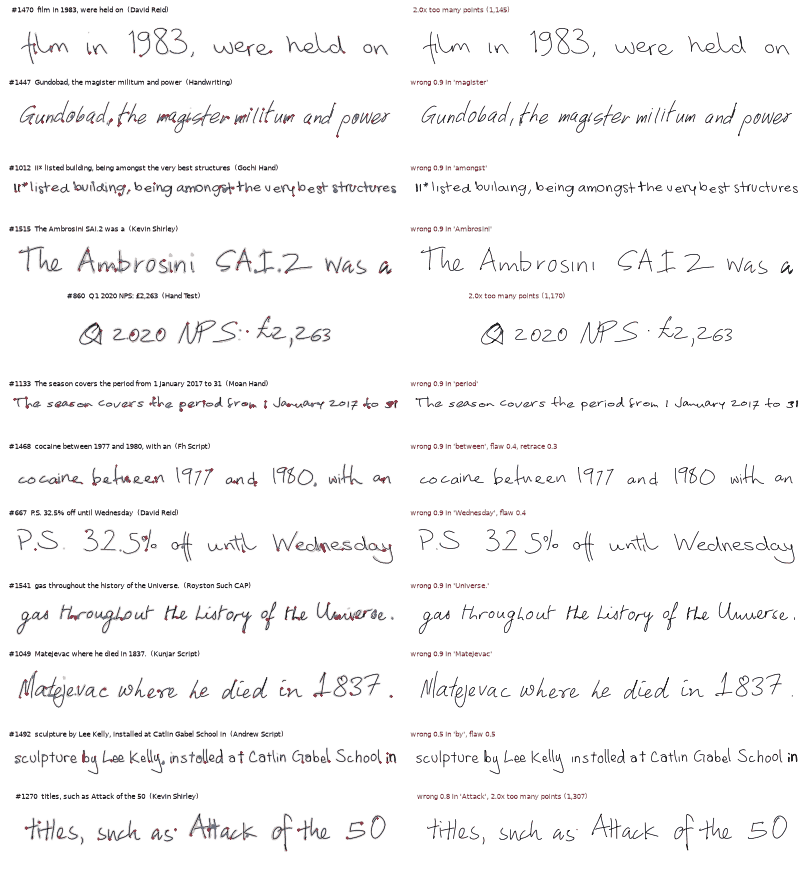

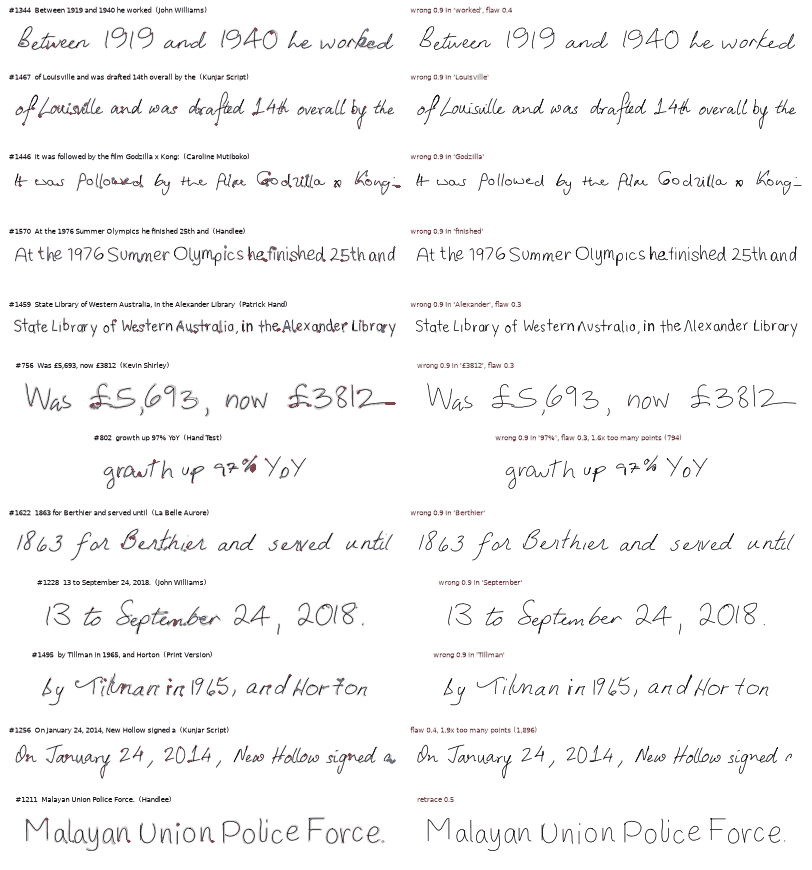

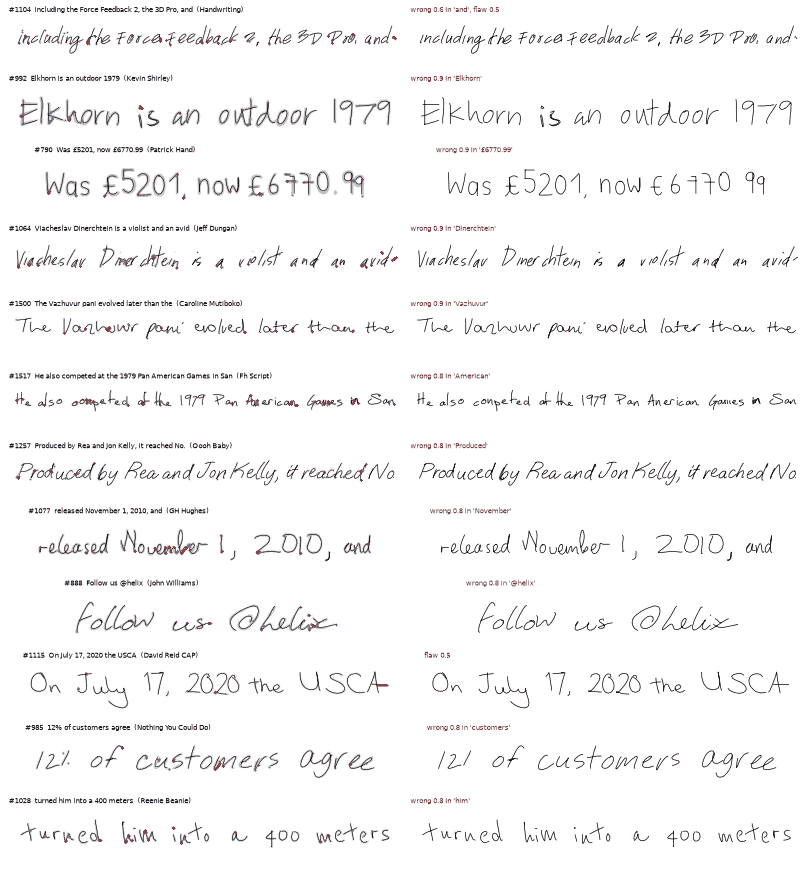

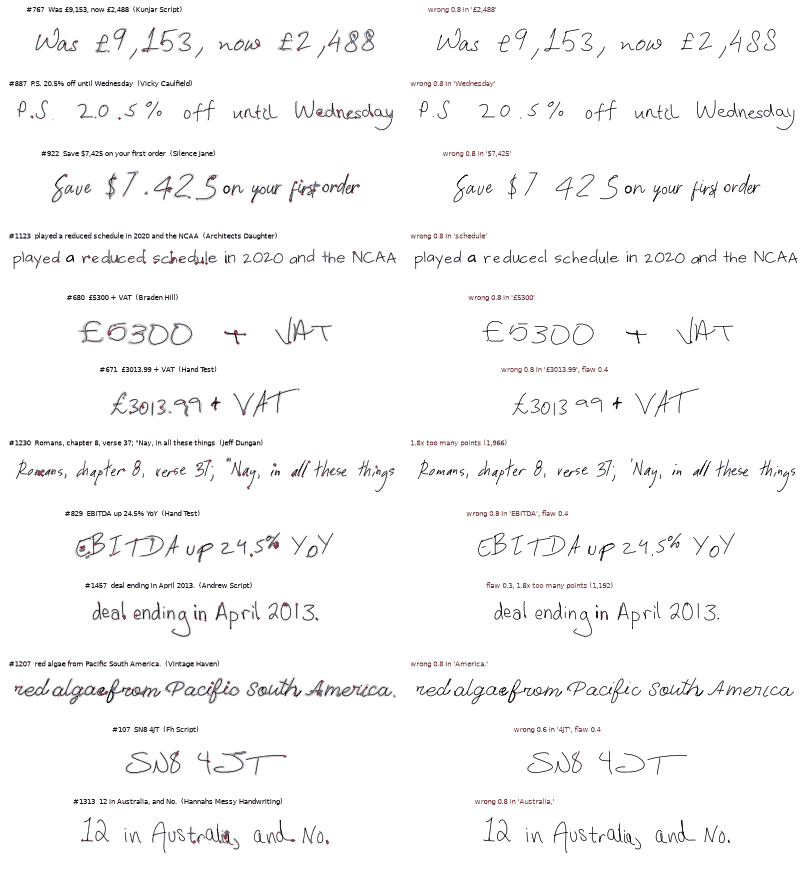

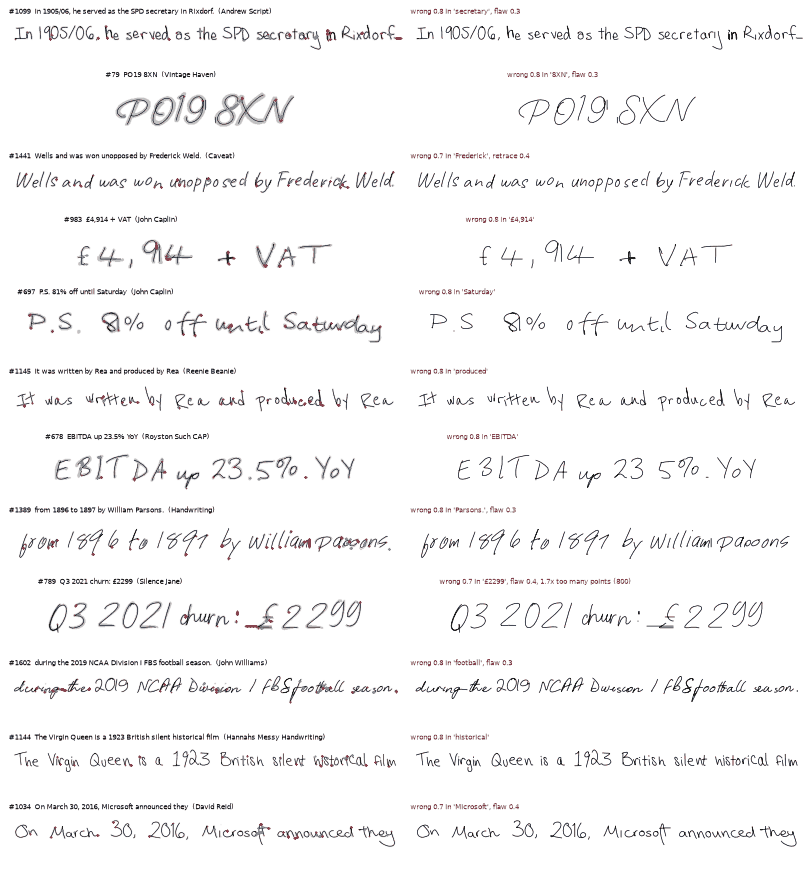

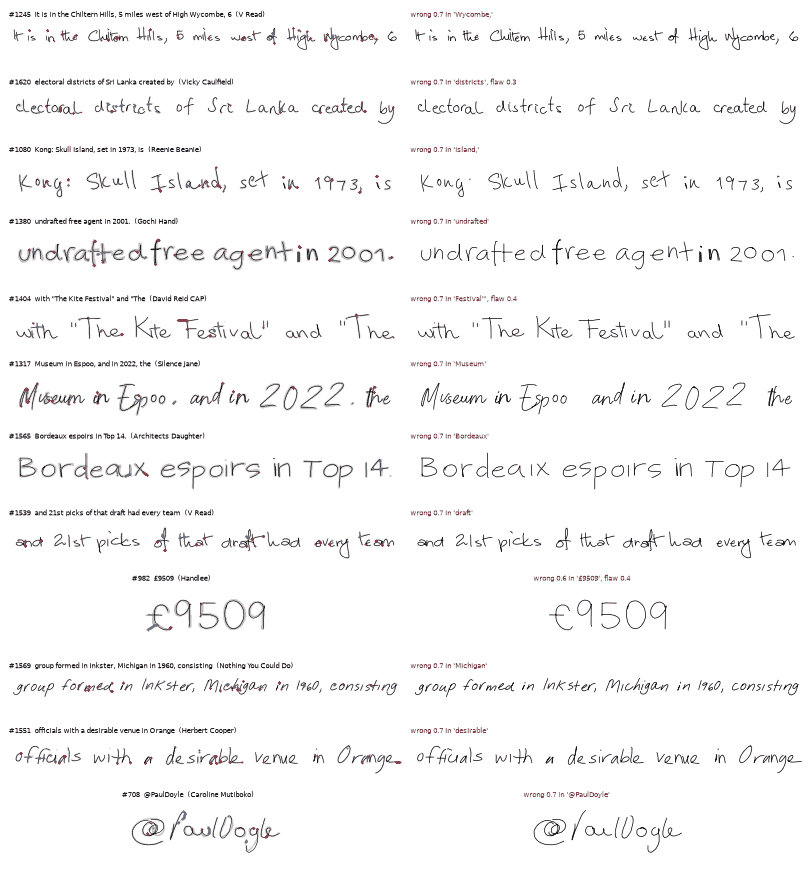

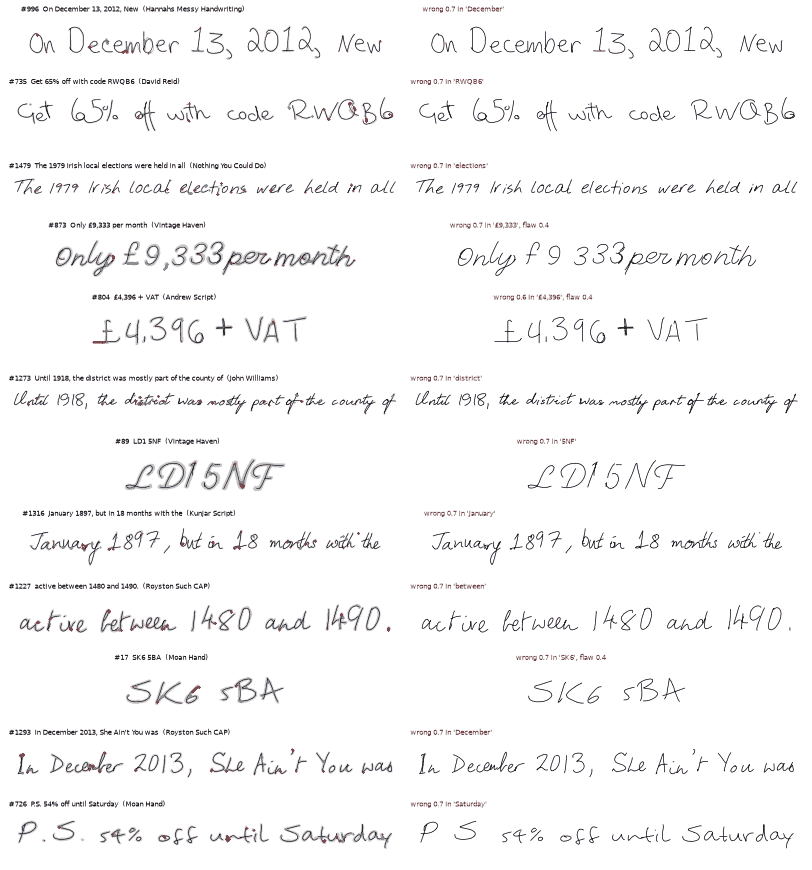

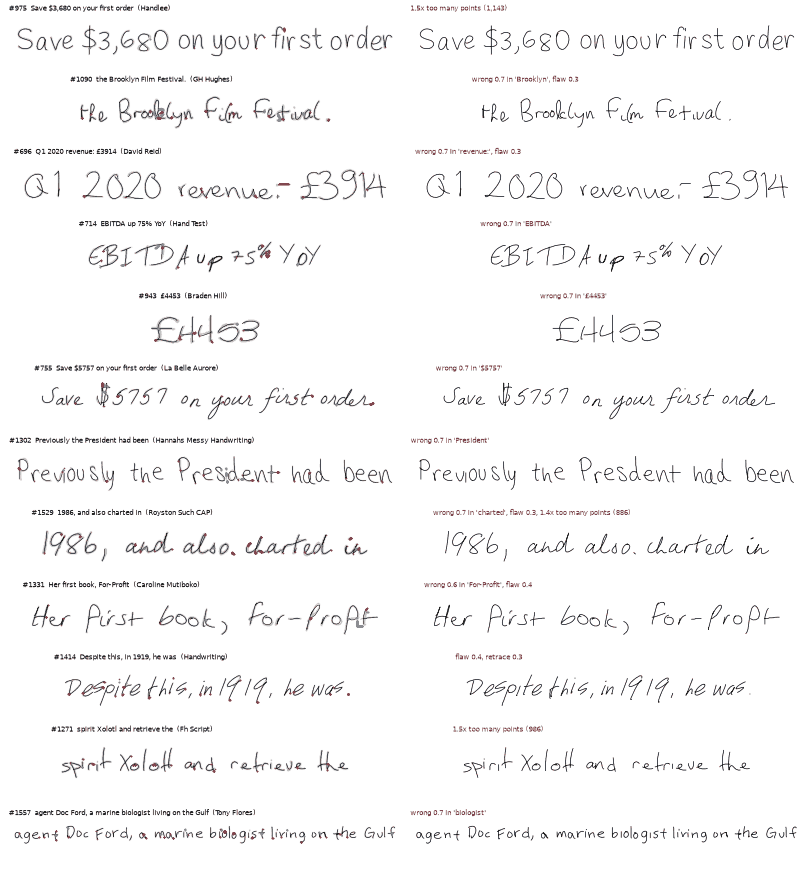

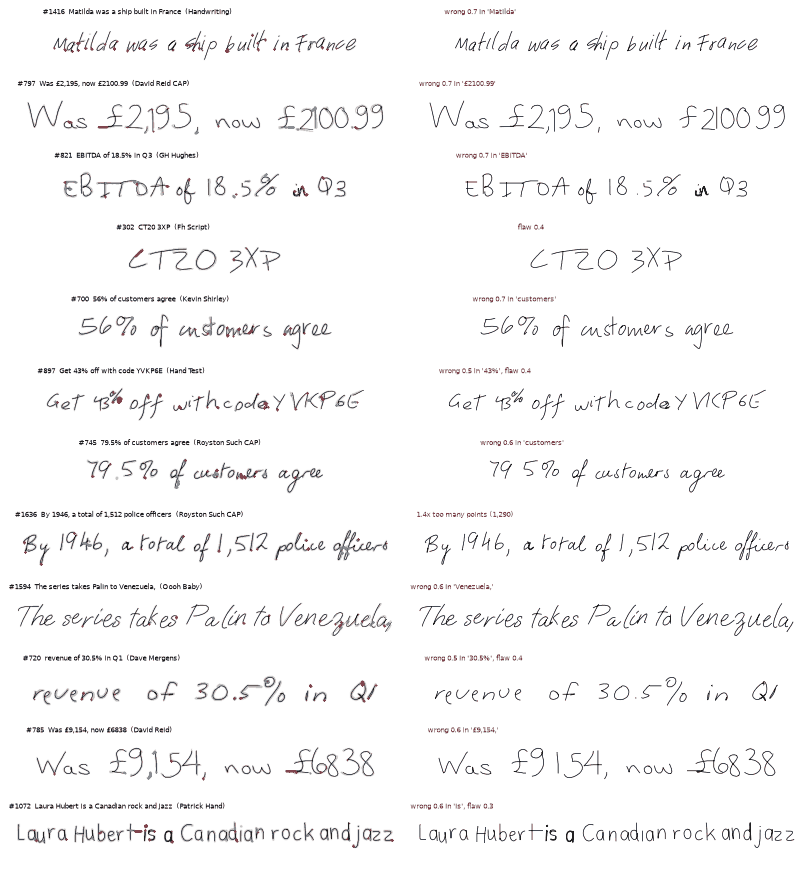

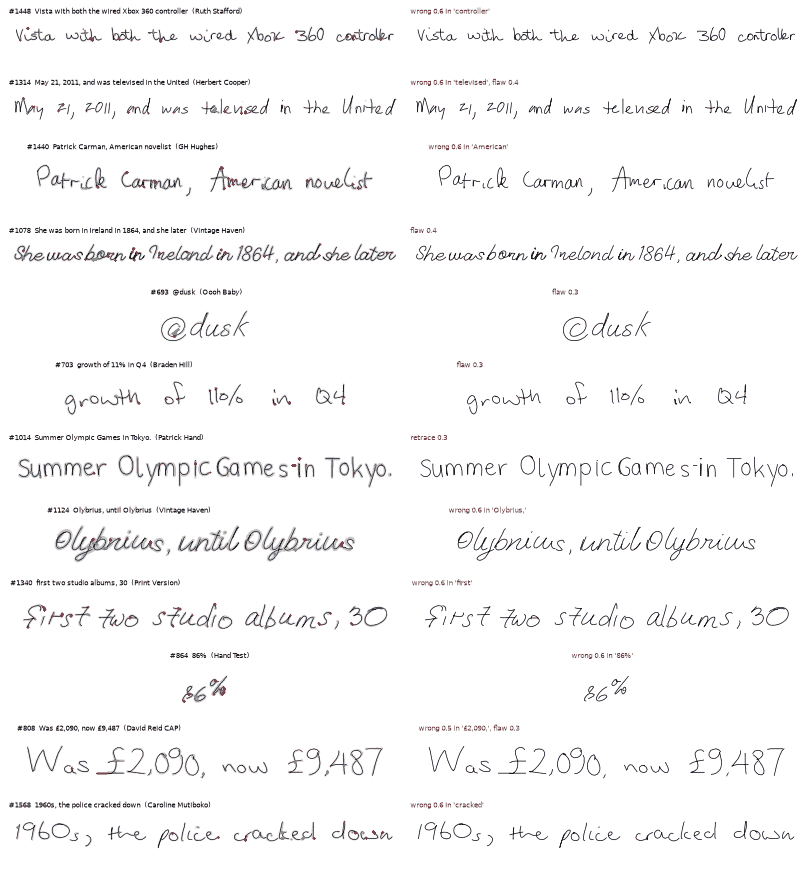

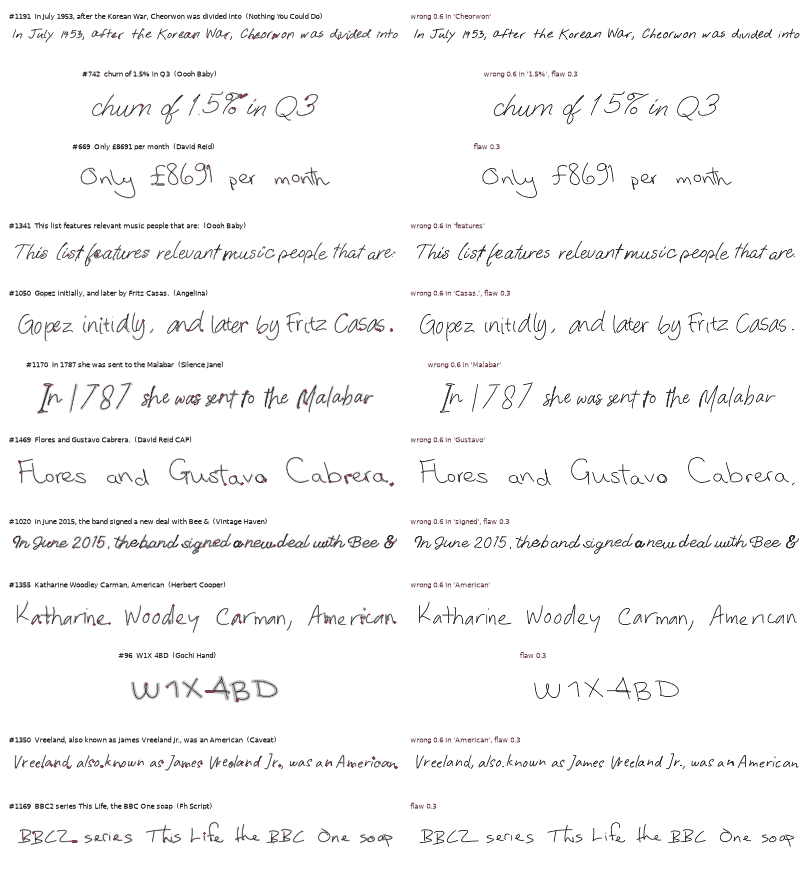

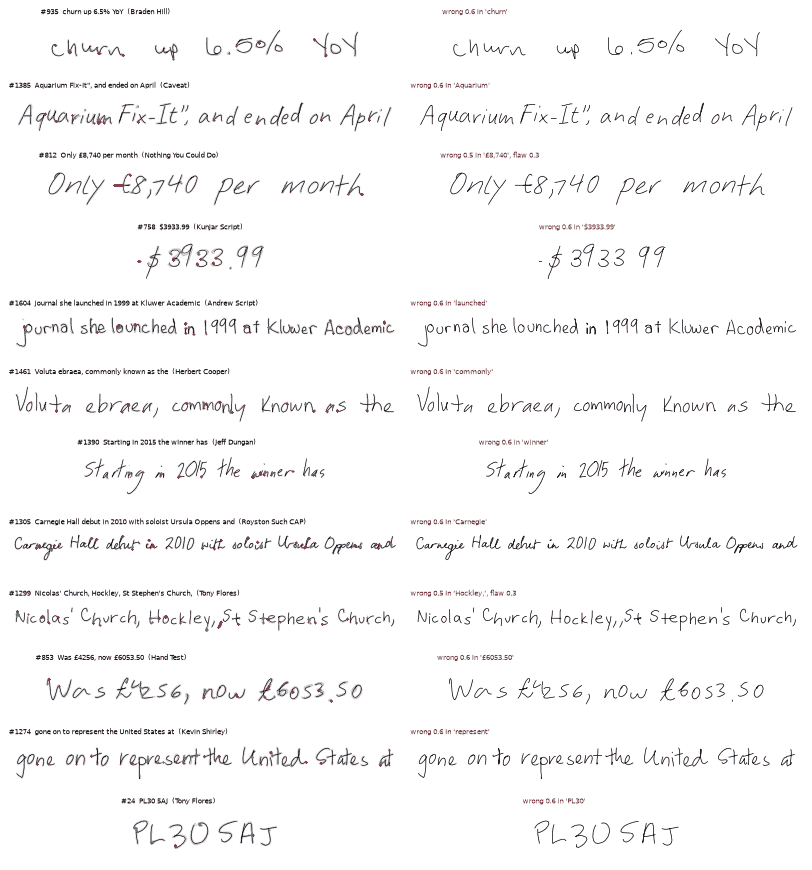

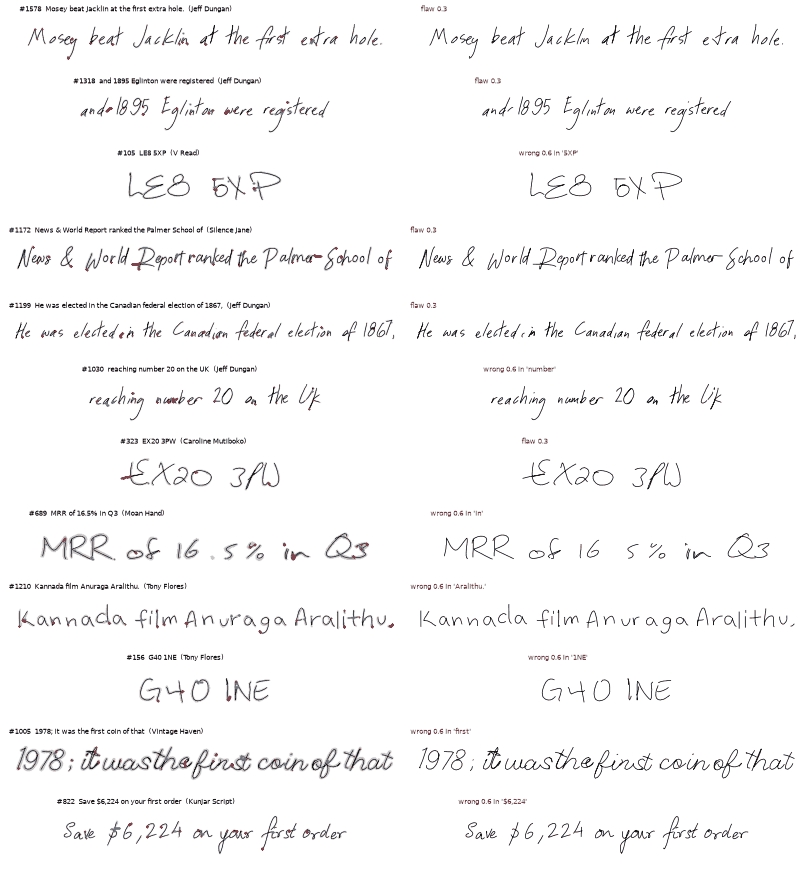

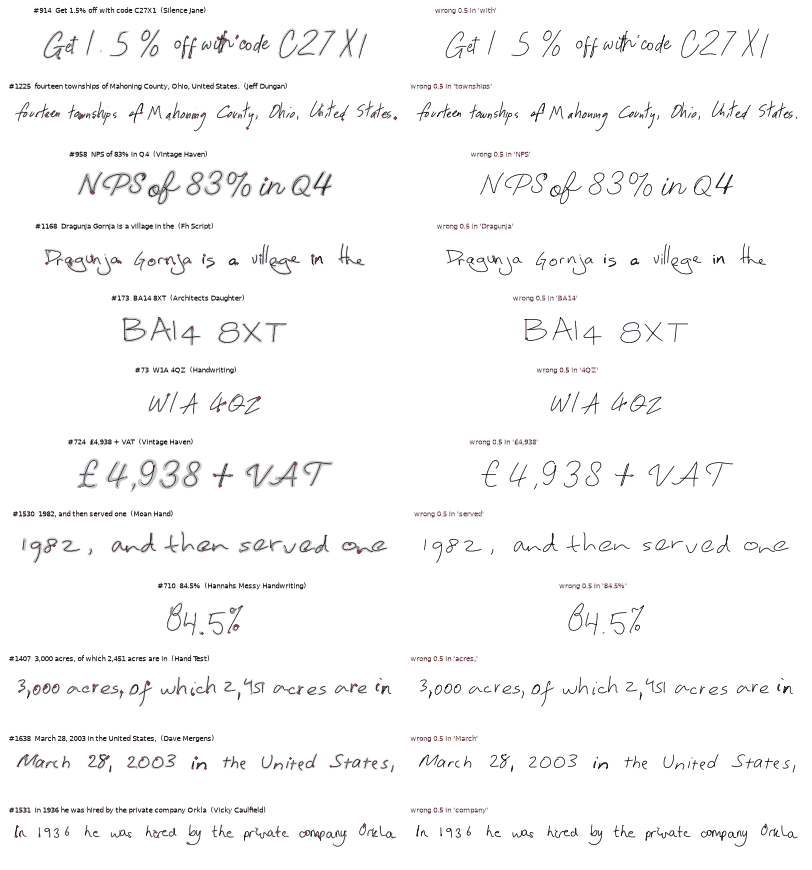

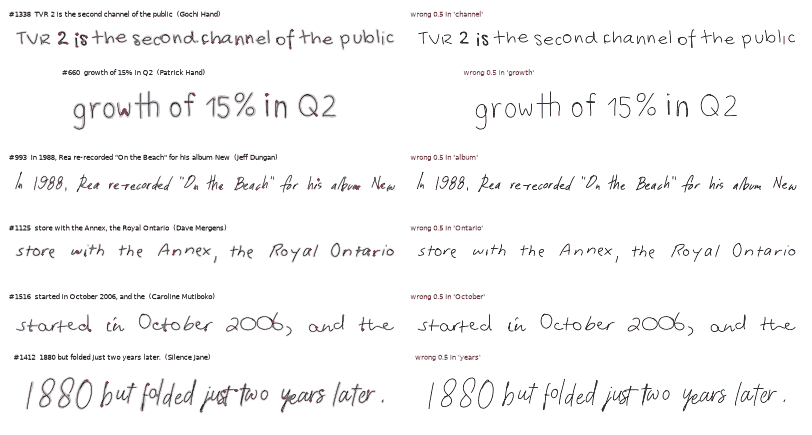

In [20]:
borderline_kept = report[report.verdict == "borderline"].sort_values("severity", ascending=False)
print(len(borderline_kept), "samples")

show(list(borderline_kept.index))

### Removed

Every removed sample, starting with the ones that only just crossed a limit (the ones most worth a second look) and ending with the worst.

866 samples


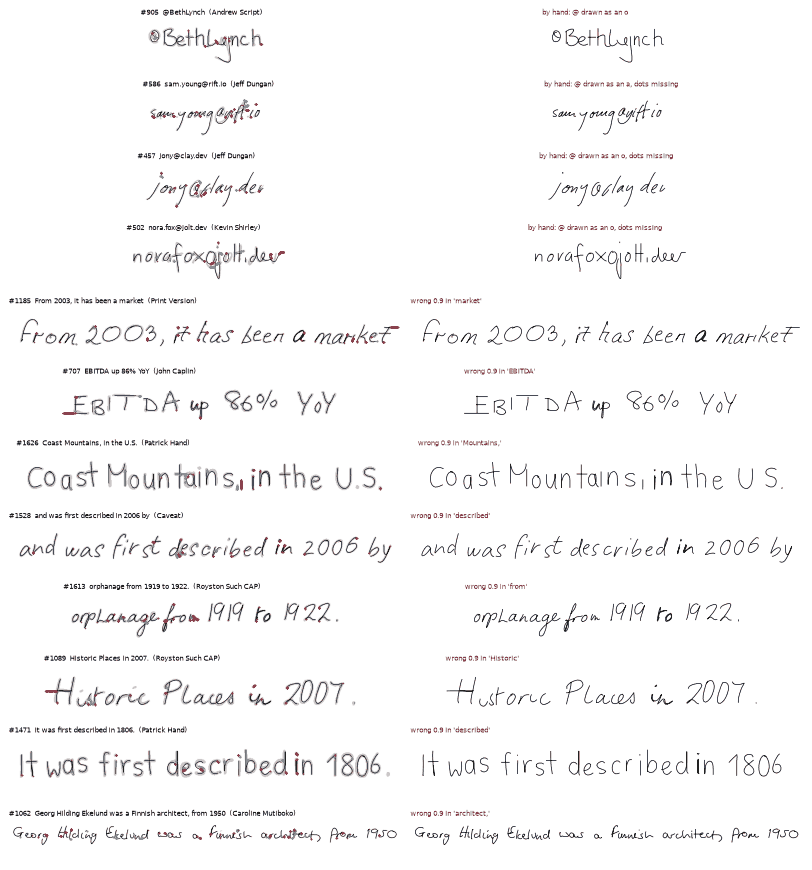

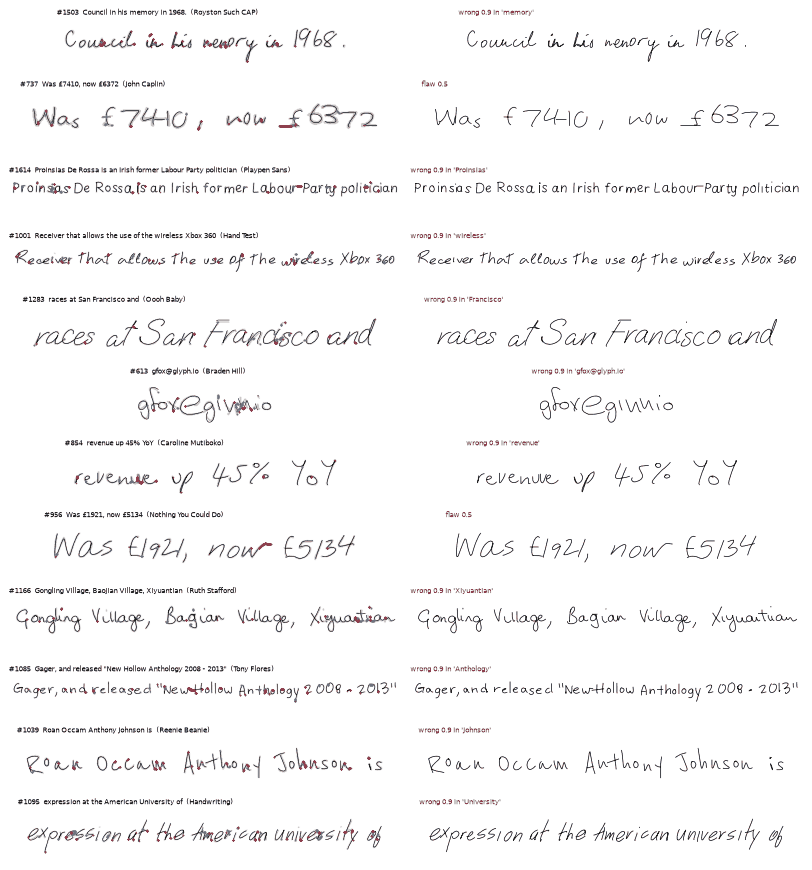

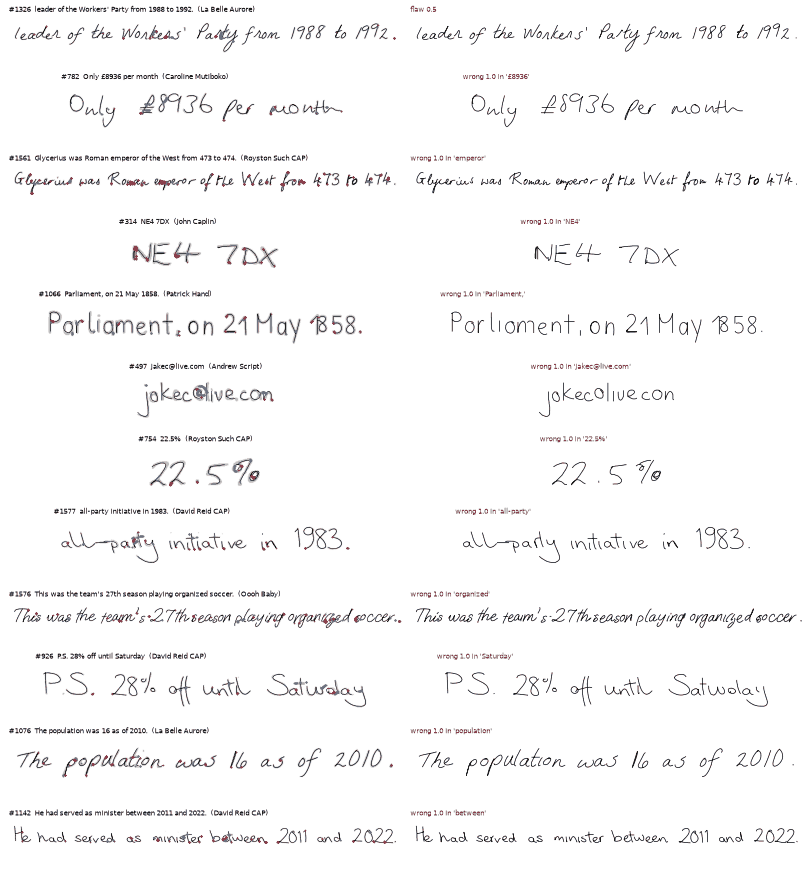

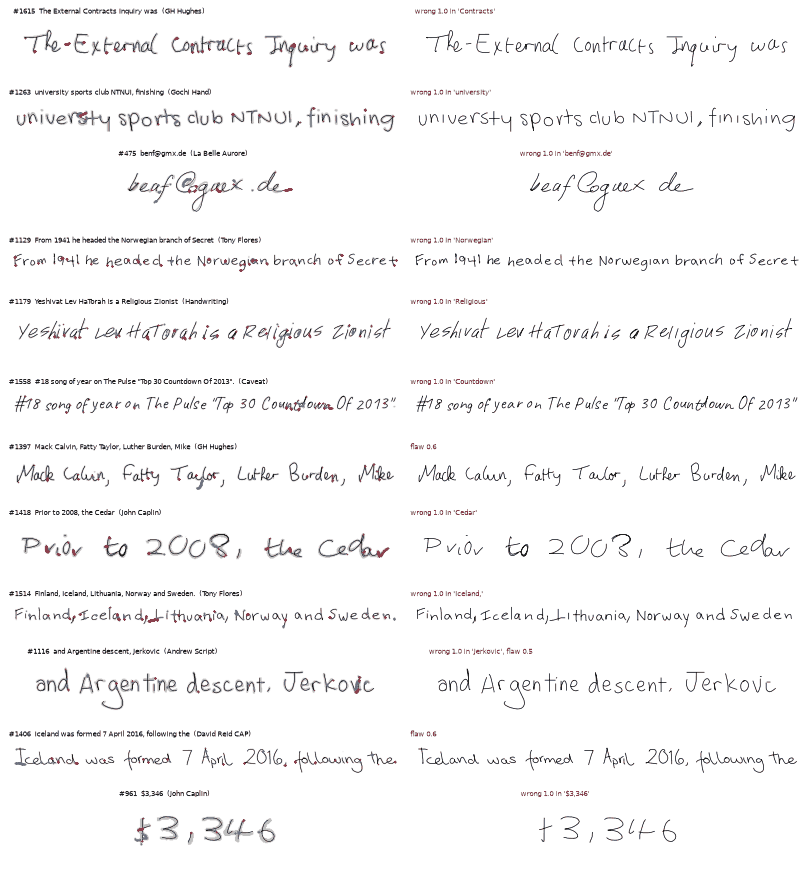

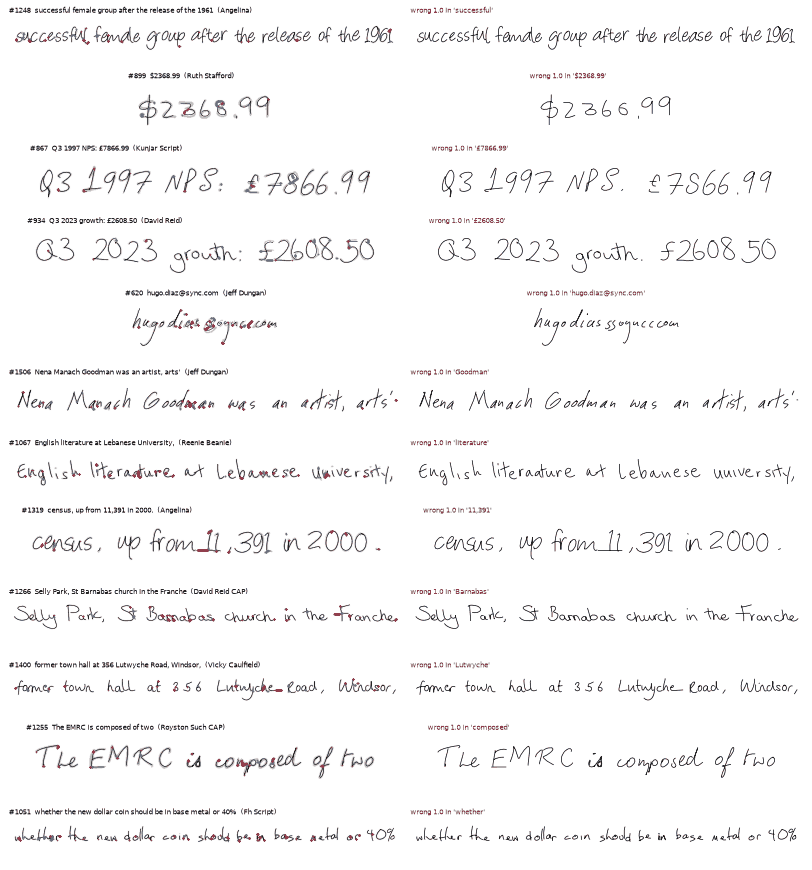

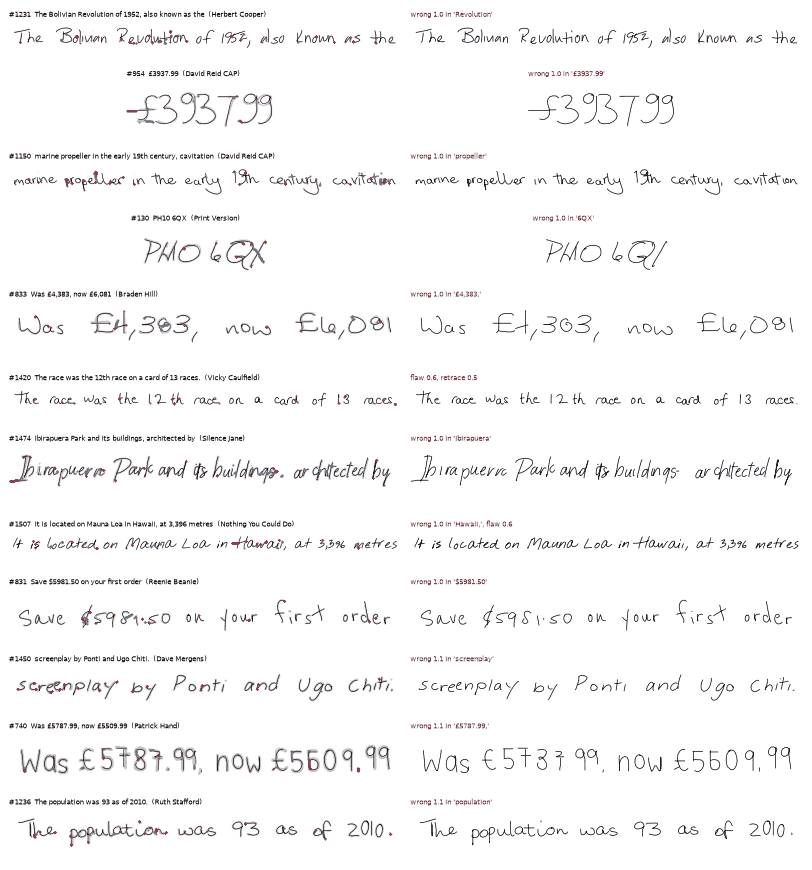

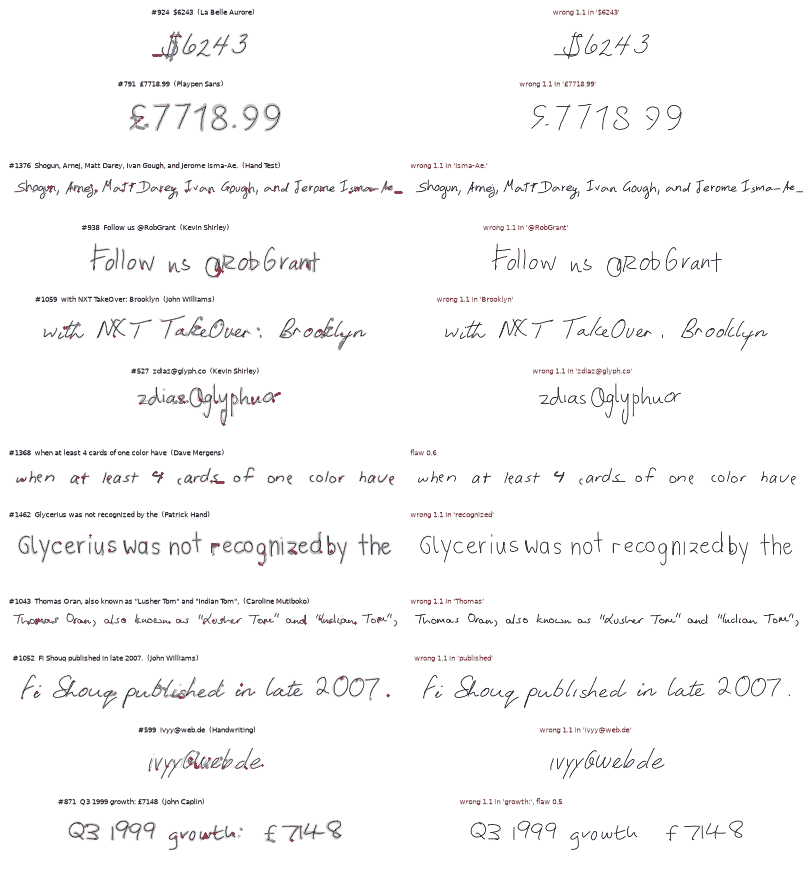

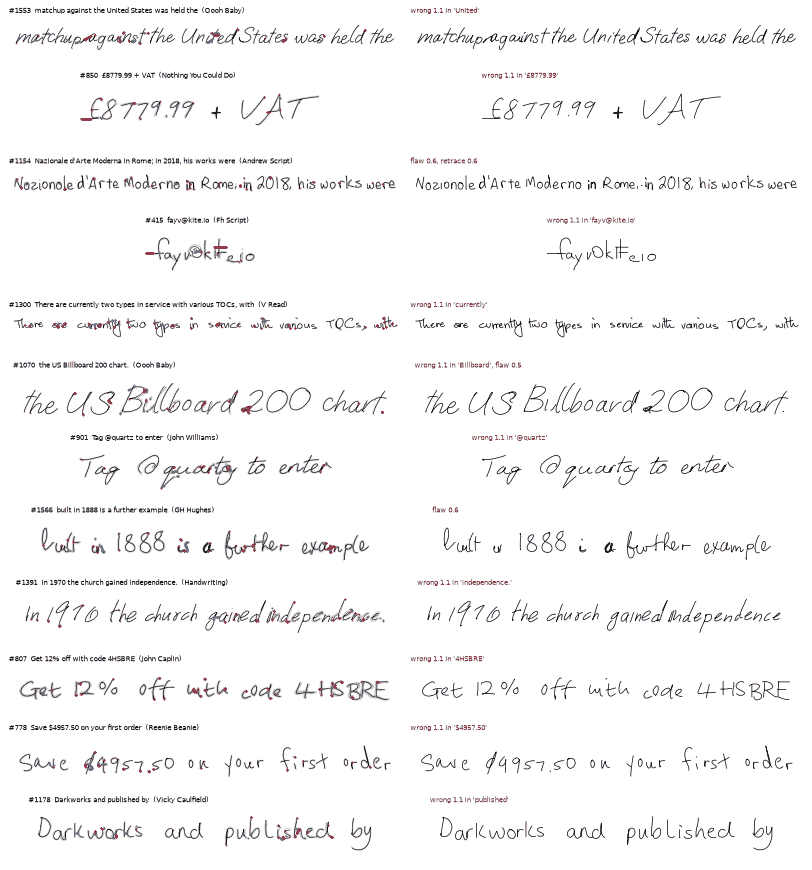

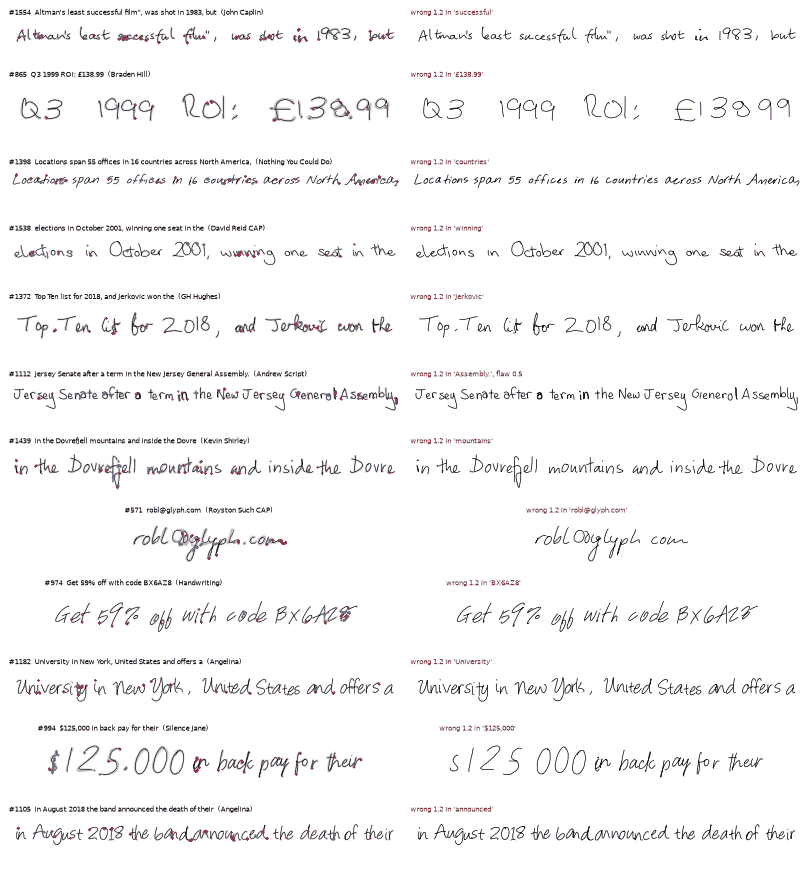

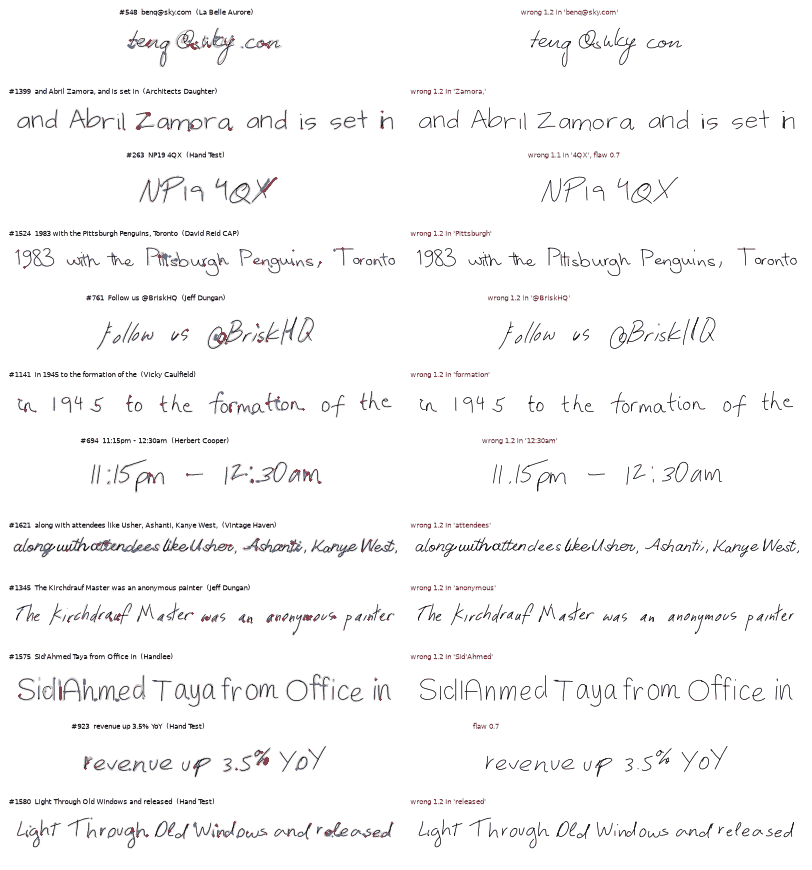

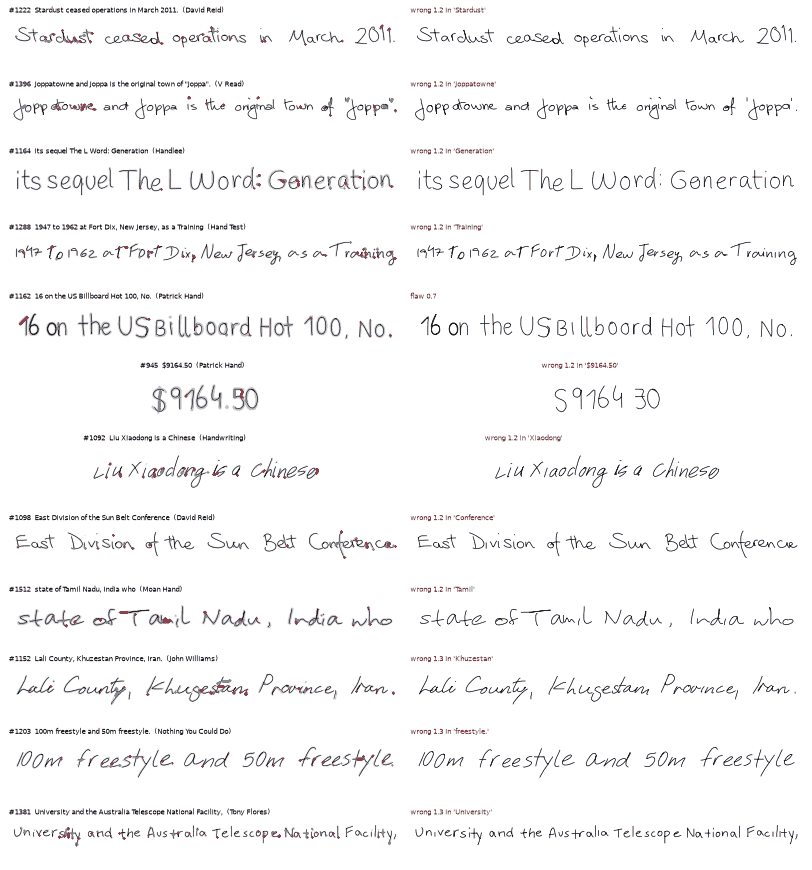

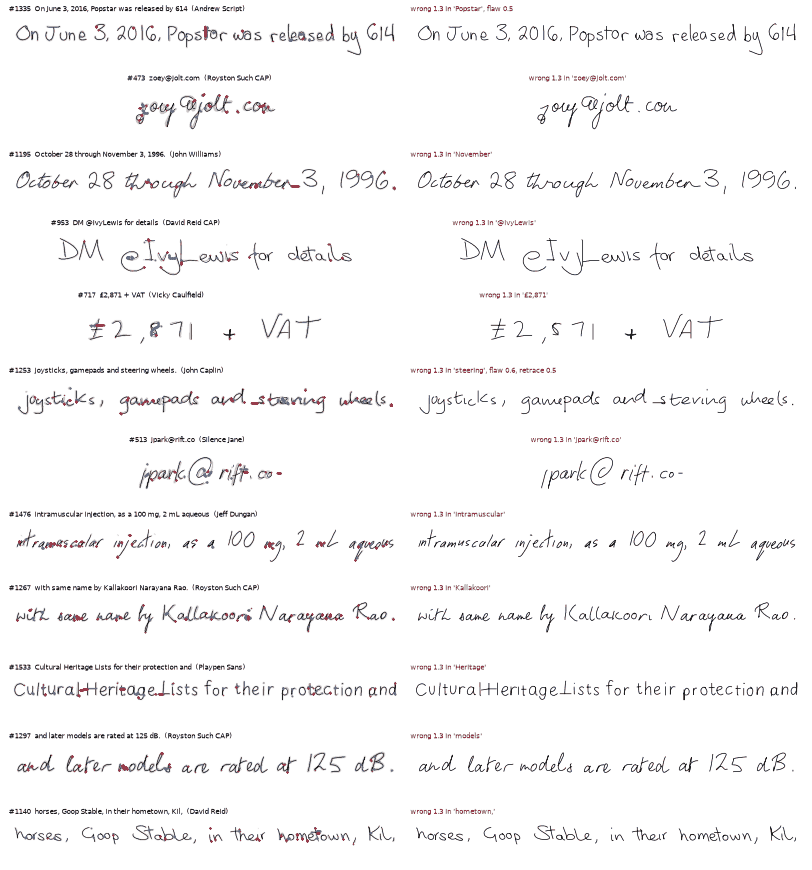

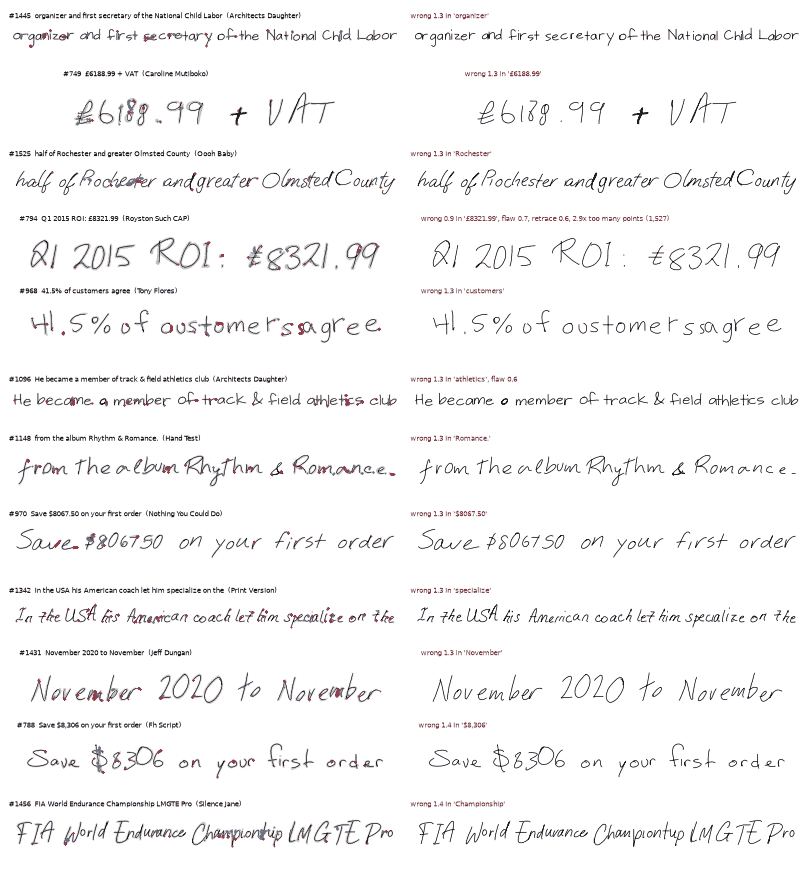

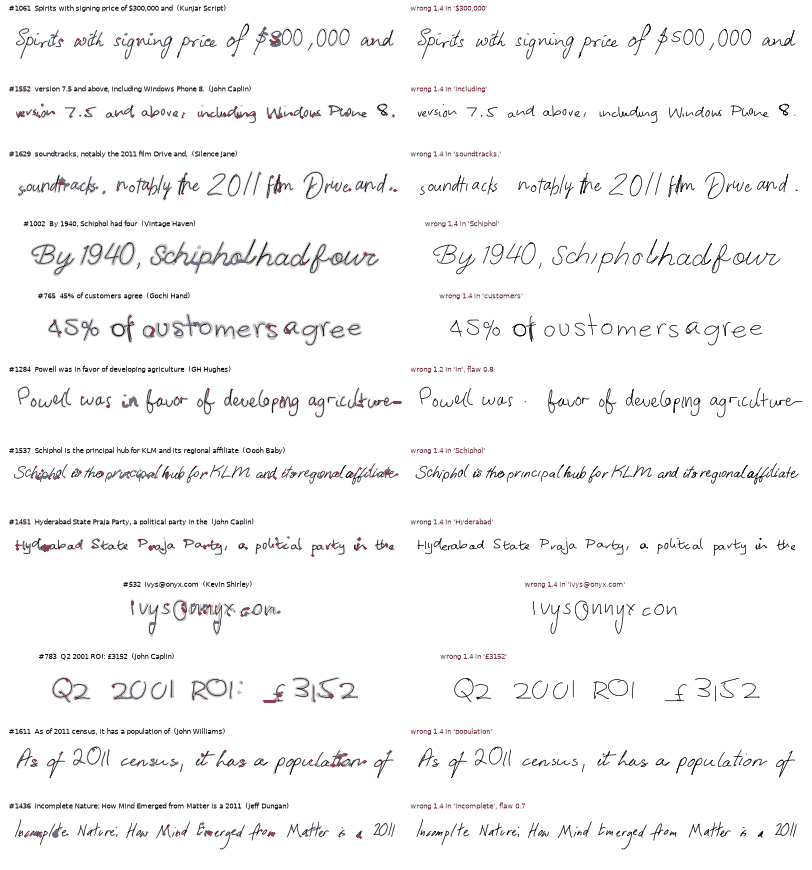

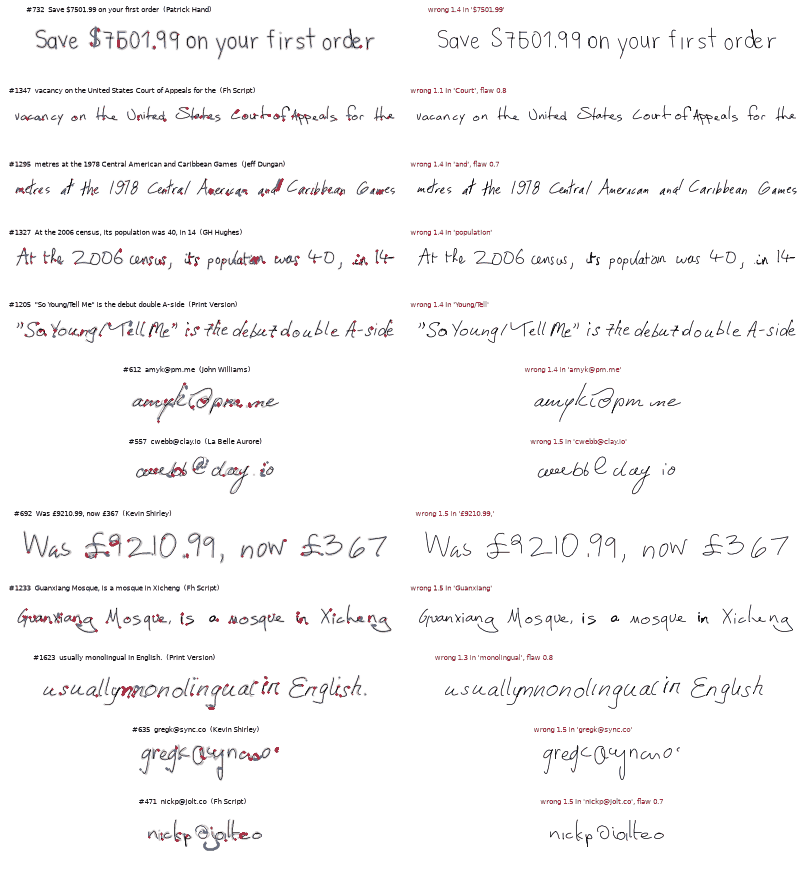

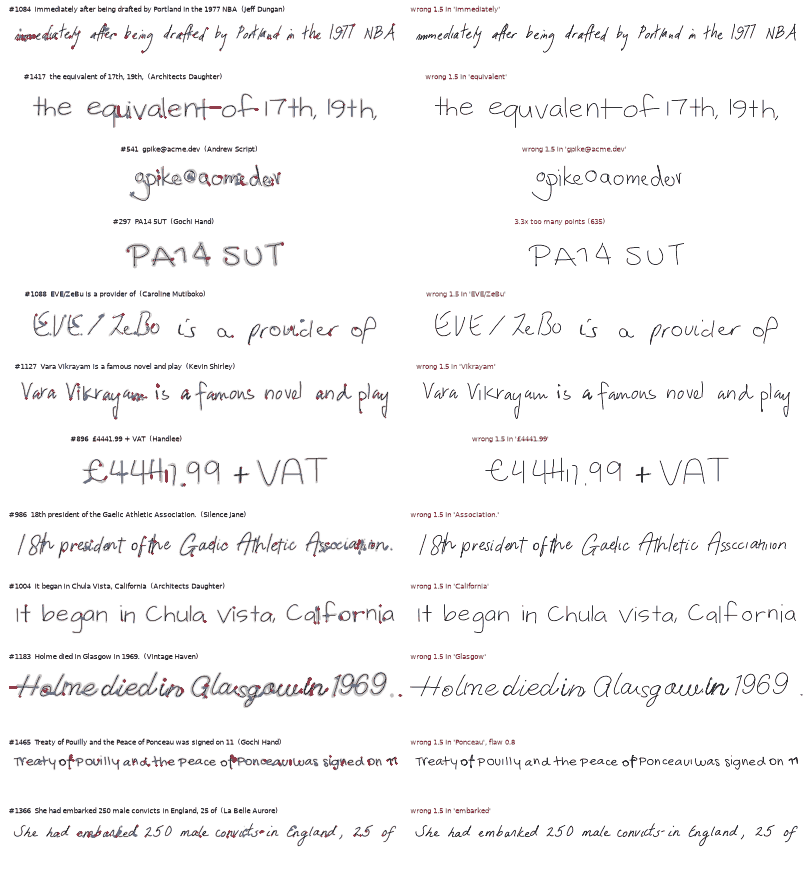

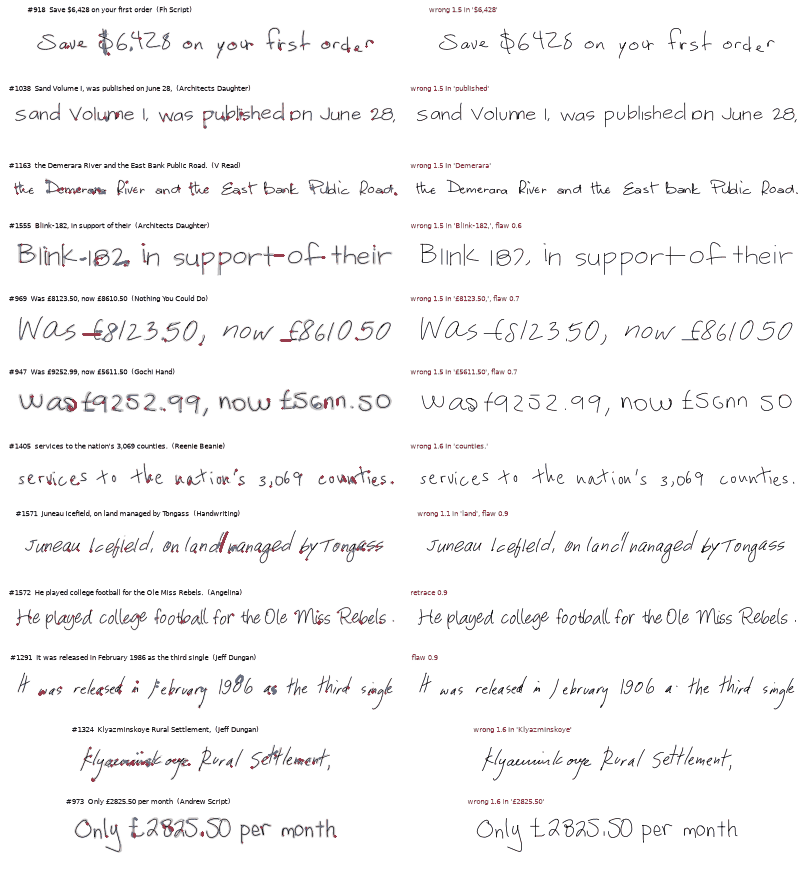

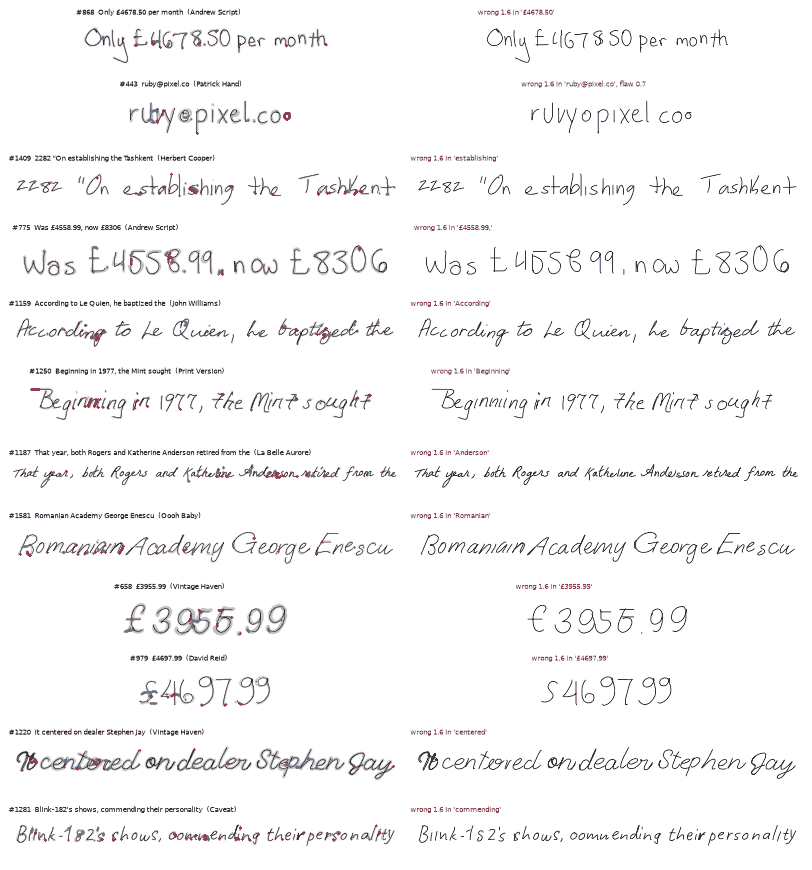

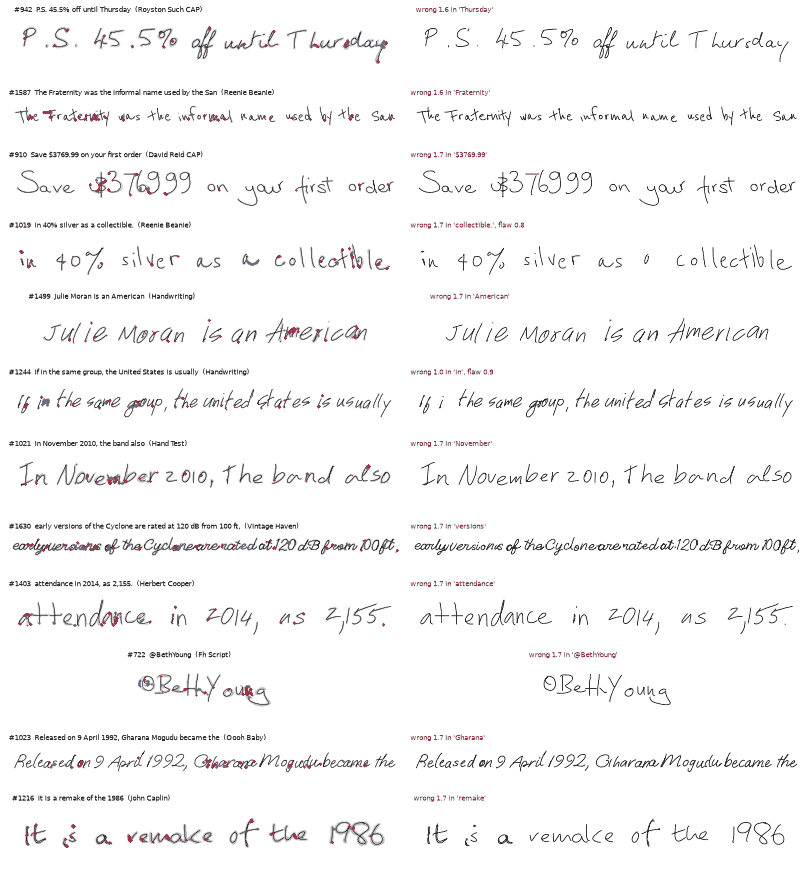

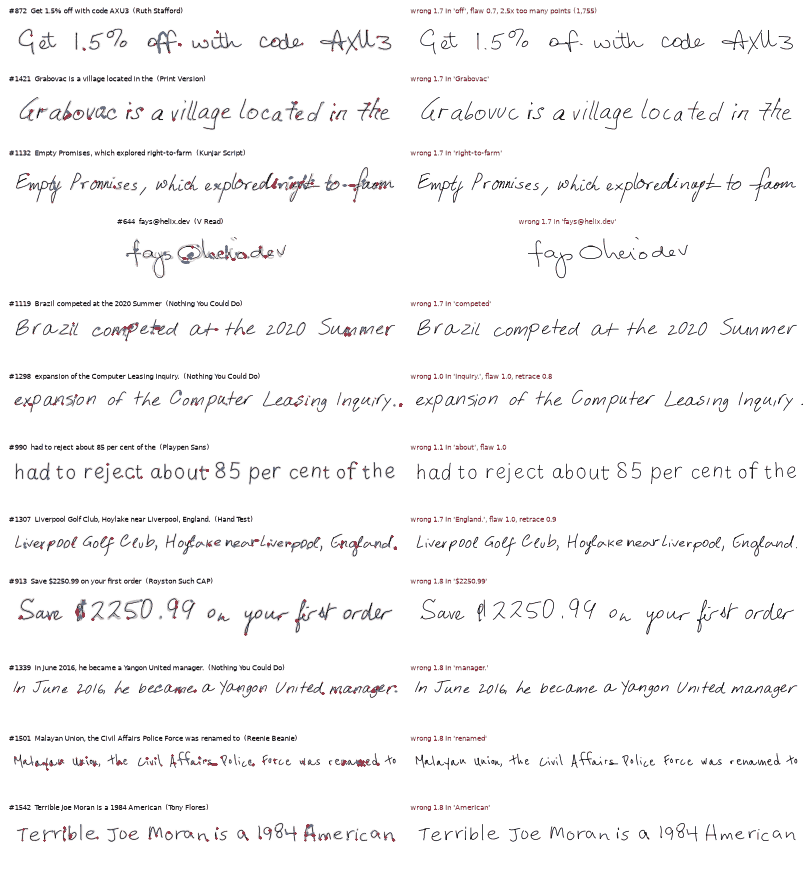

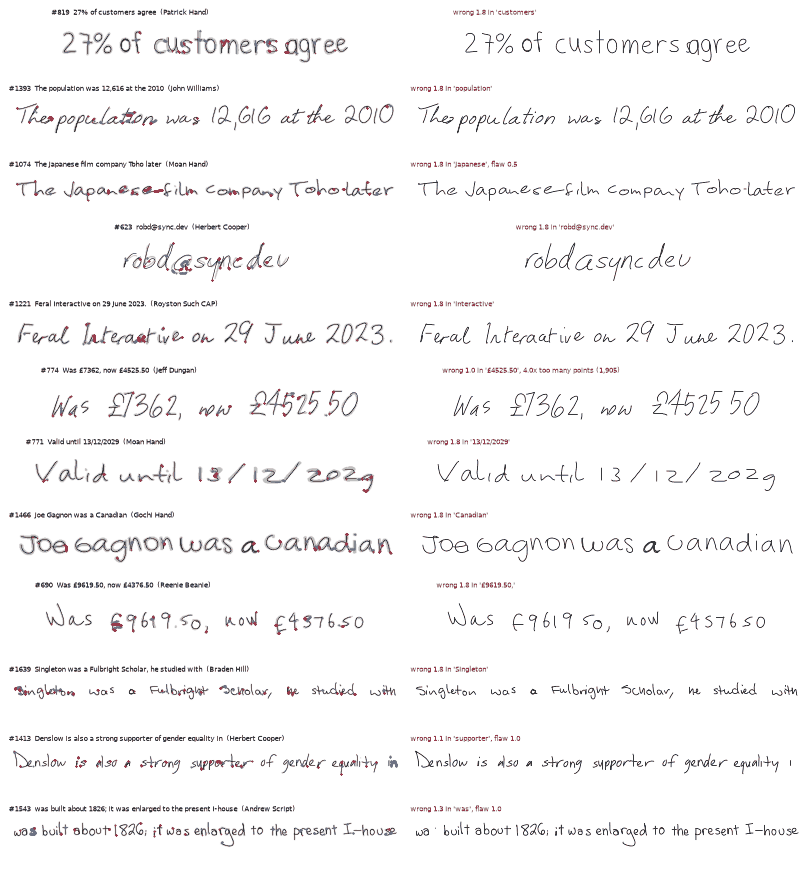

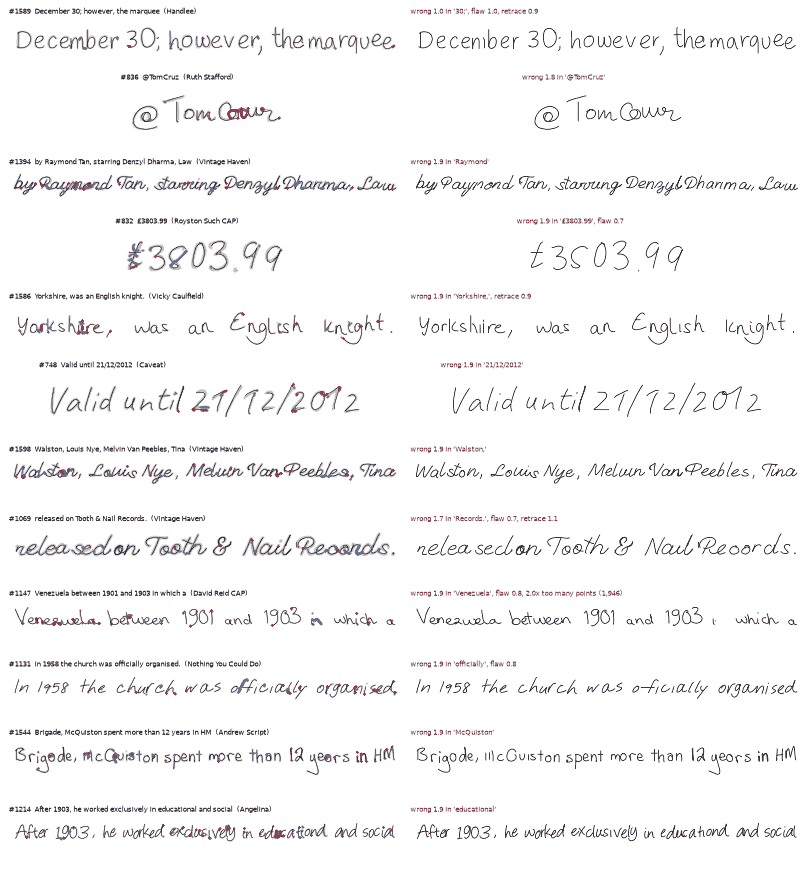

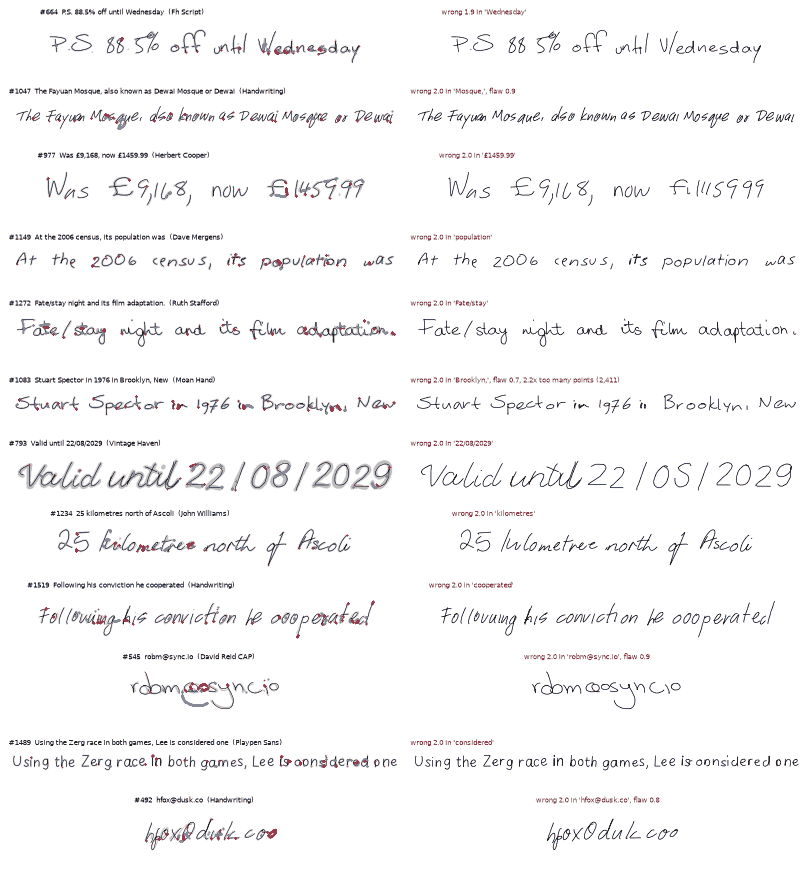

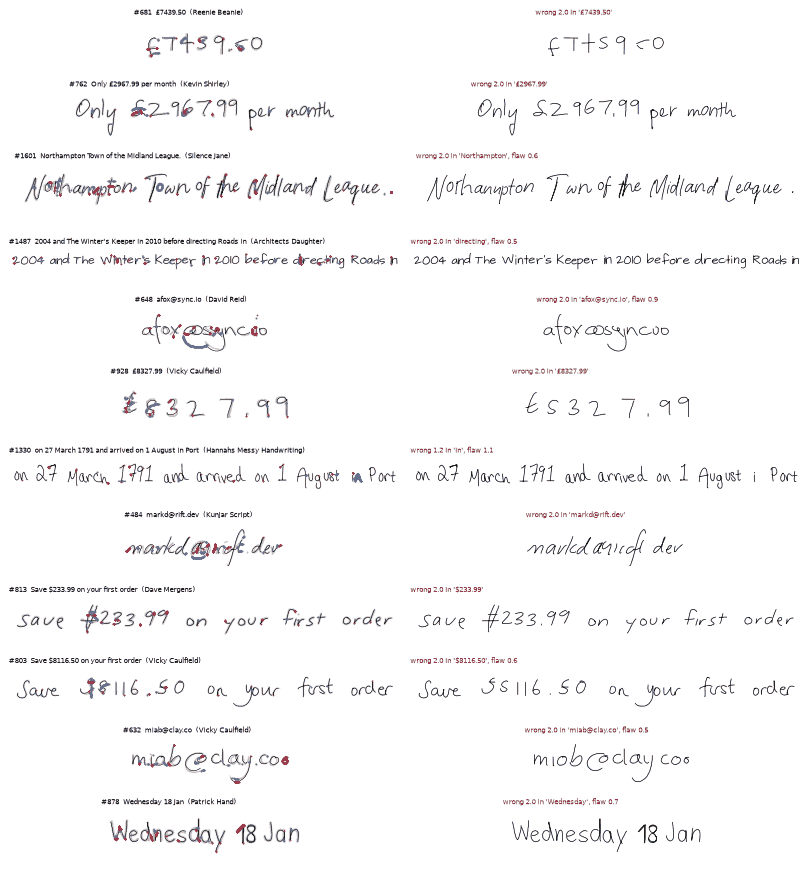

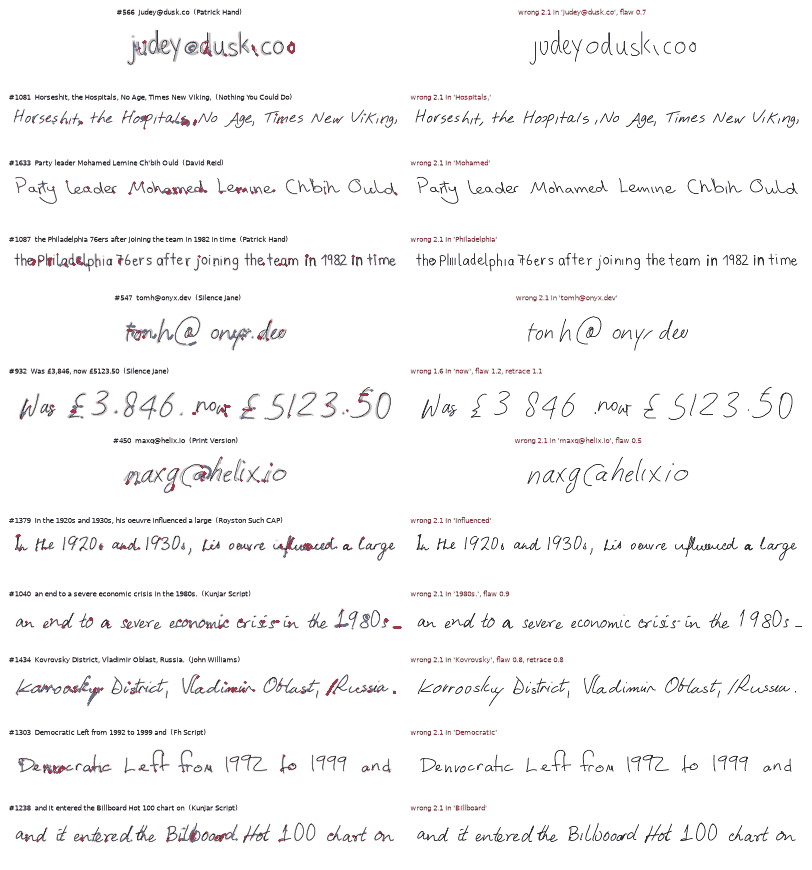

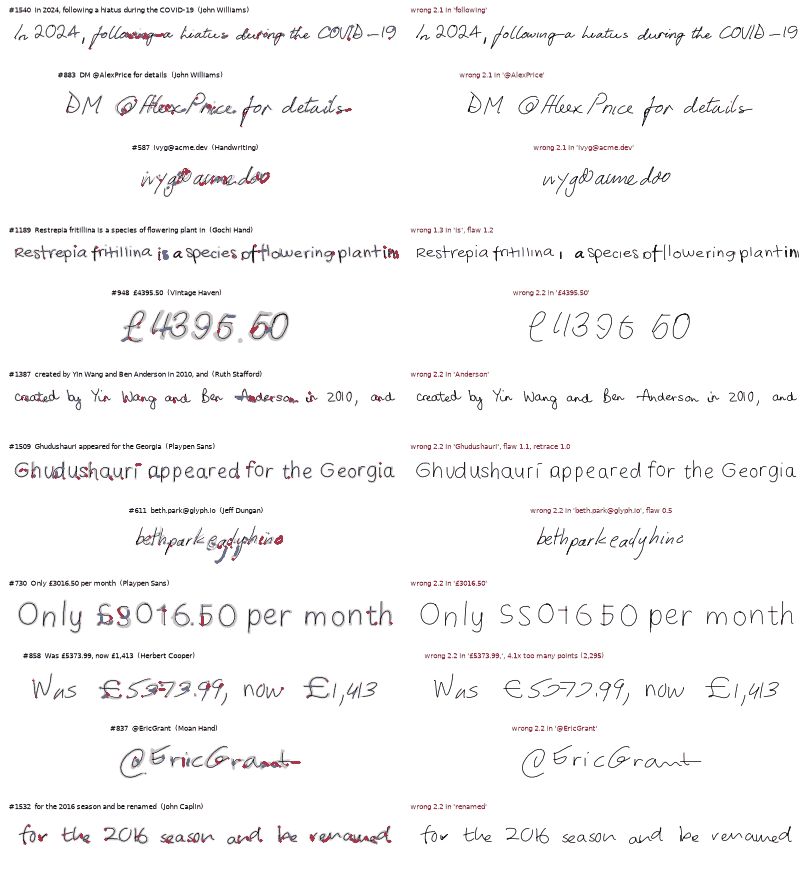

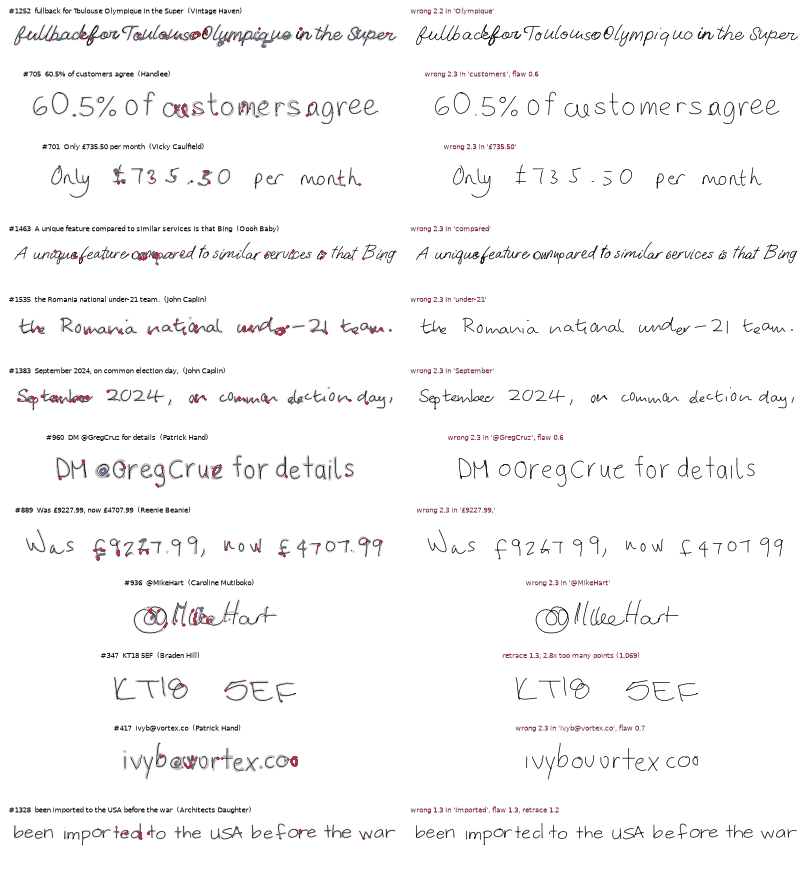

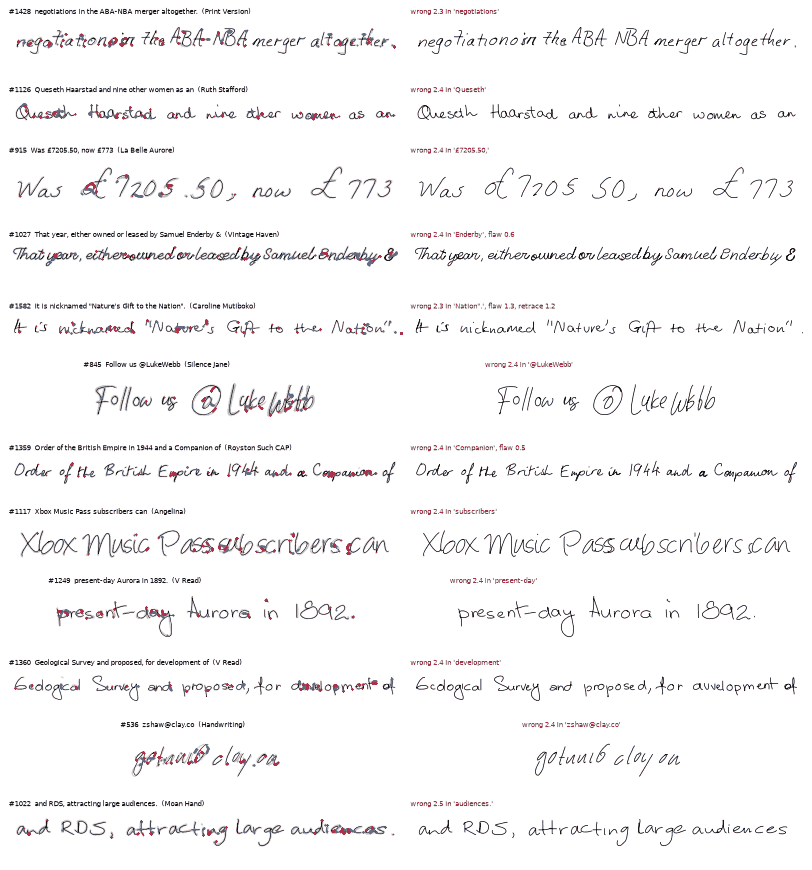

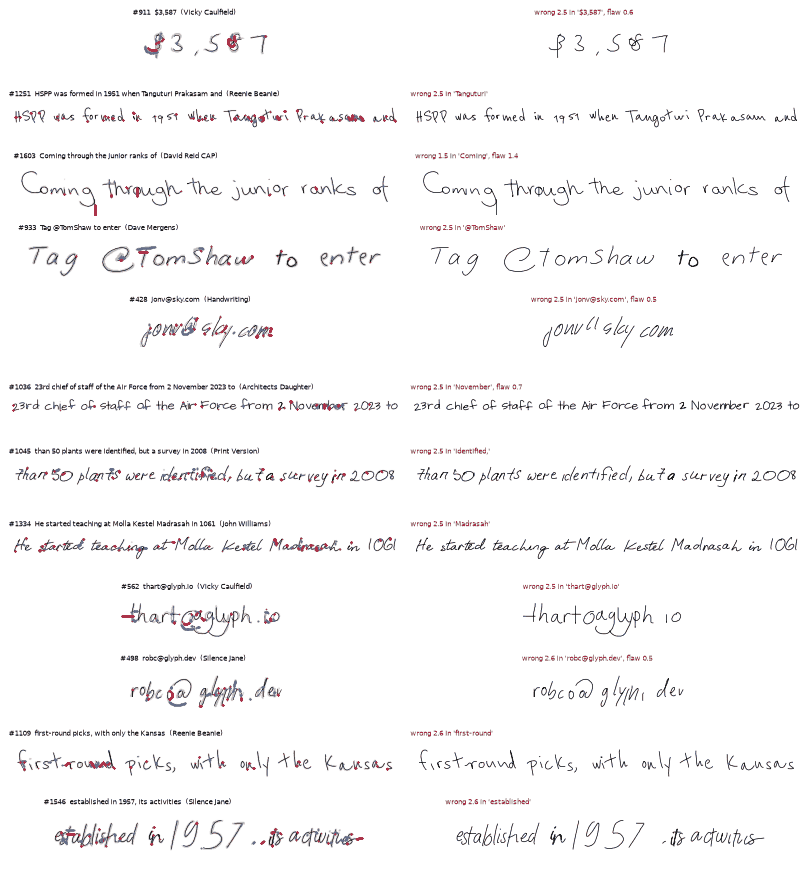

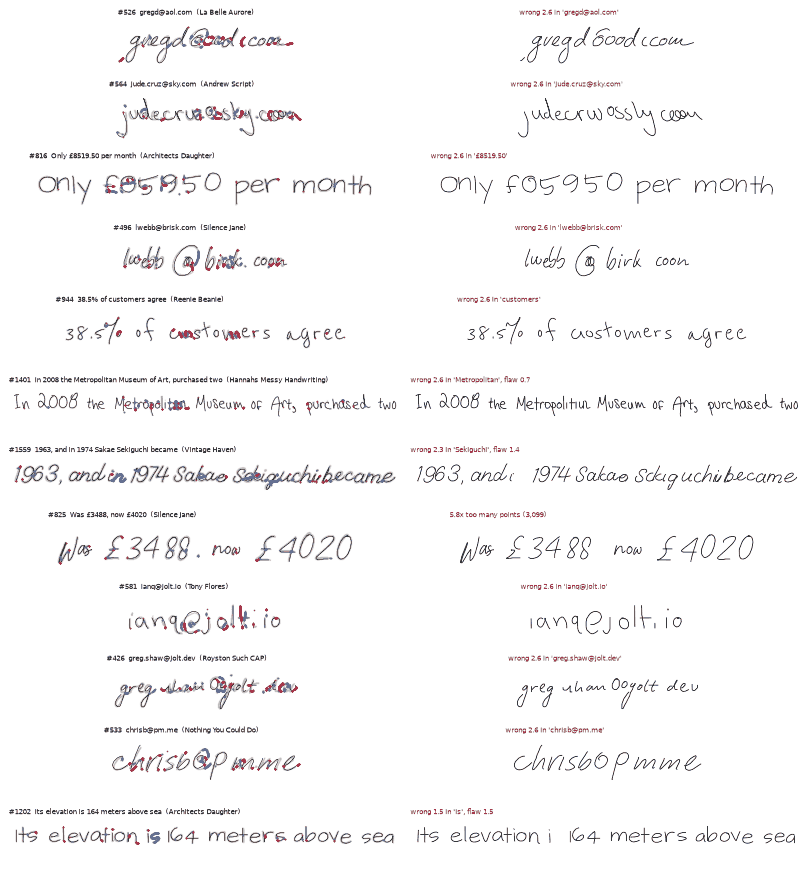

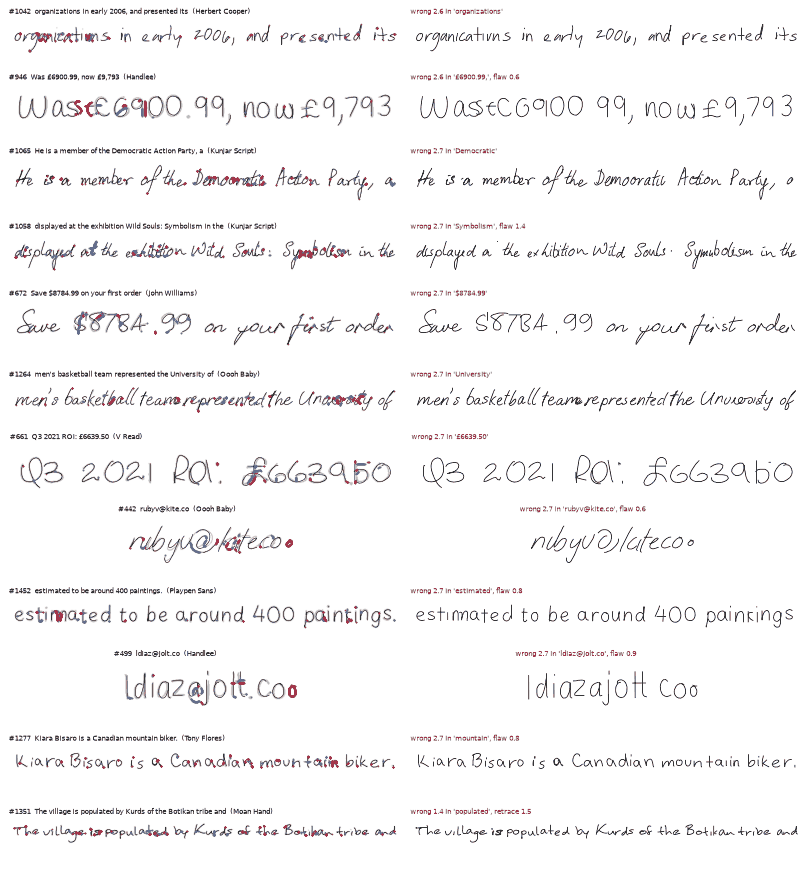

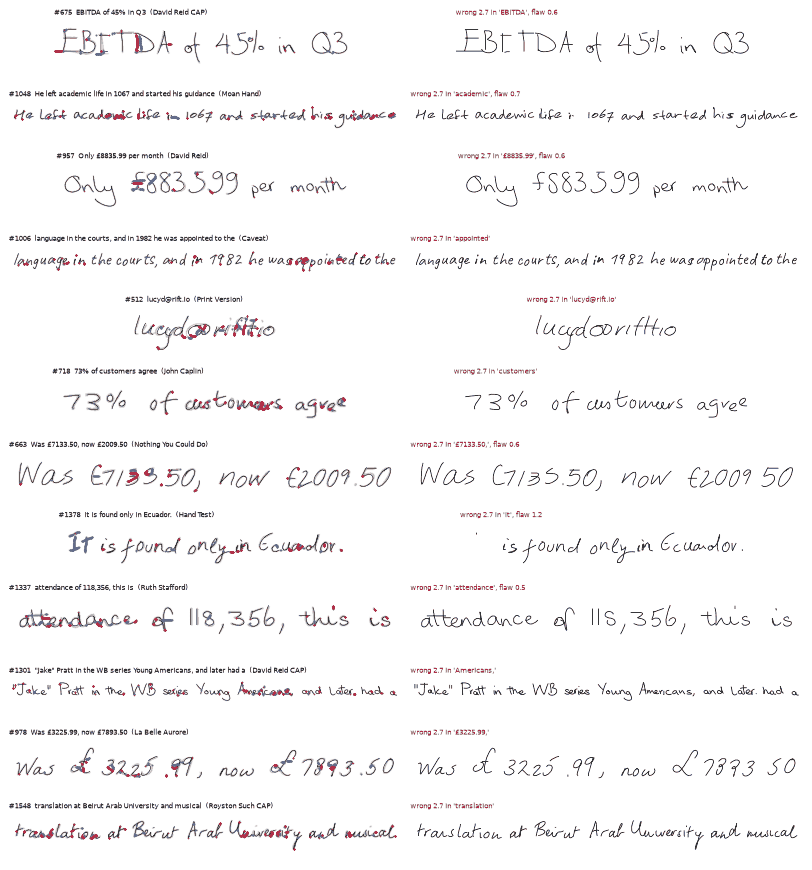

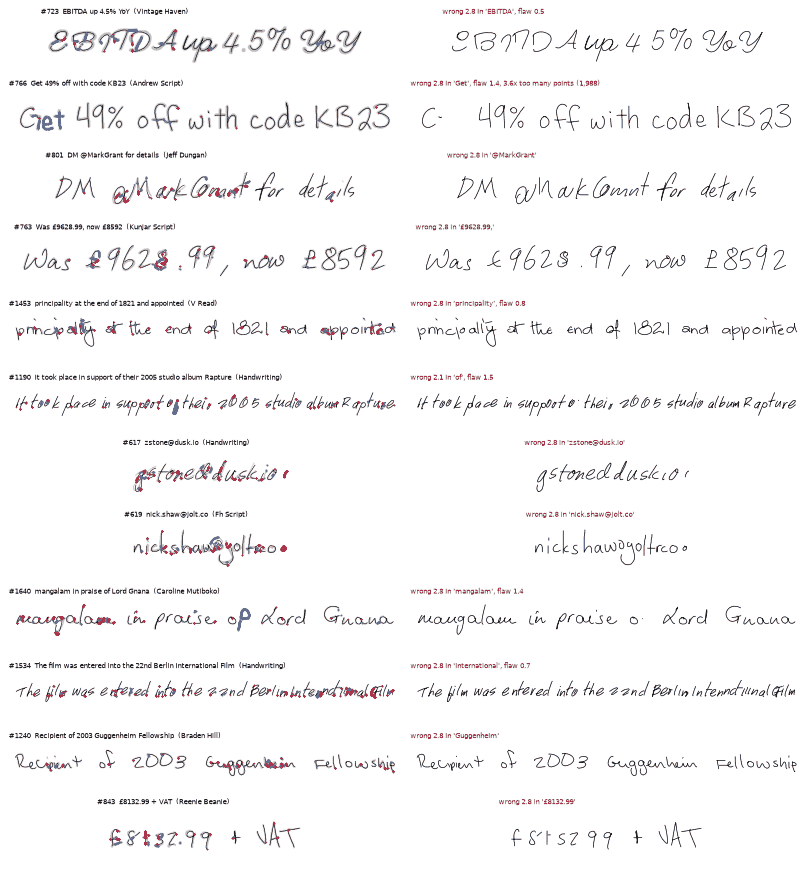

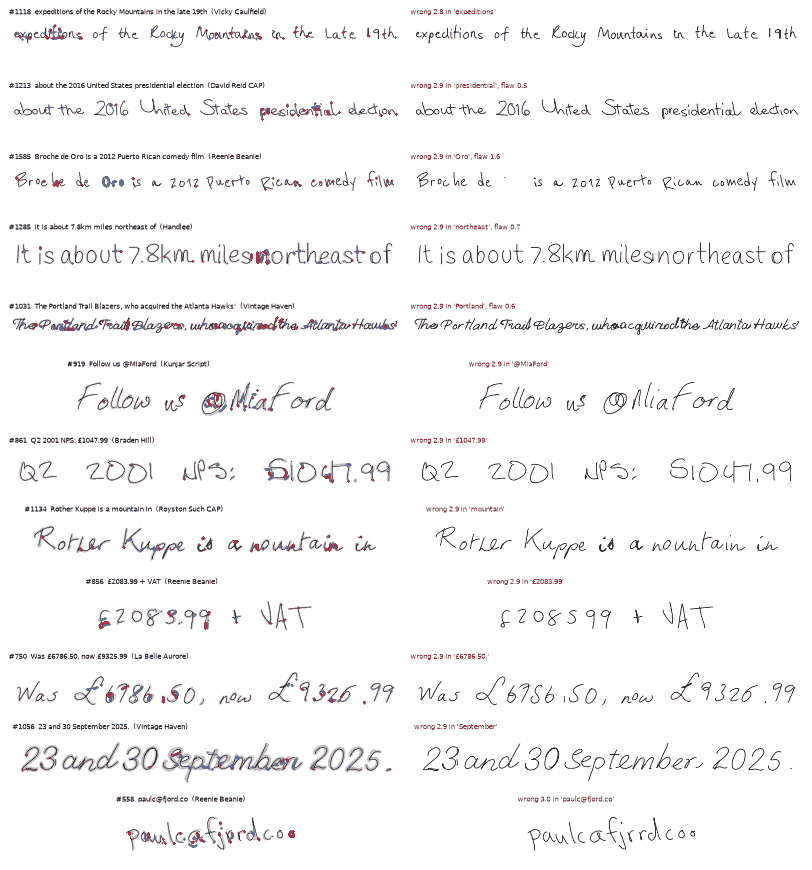

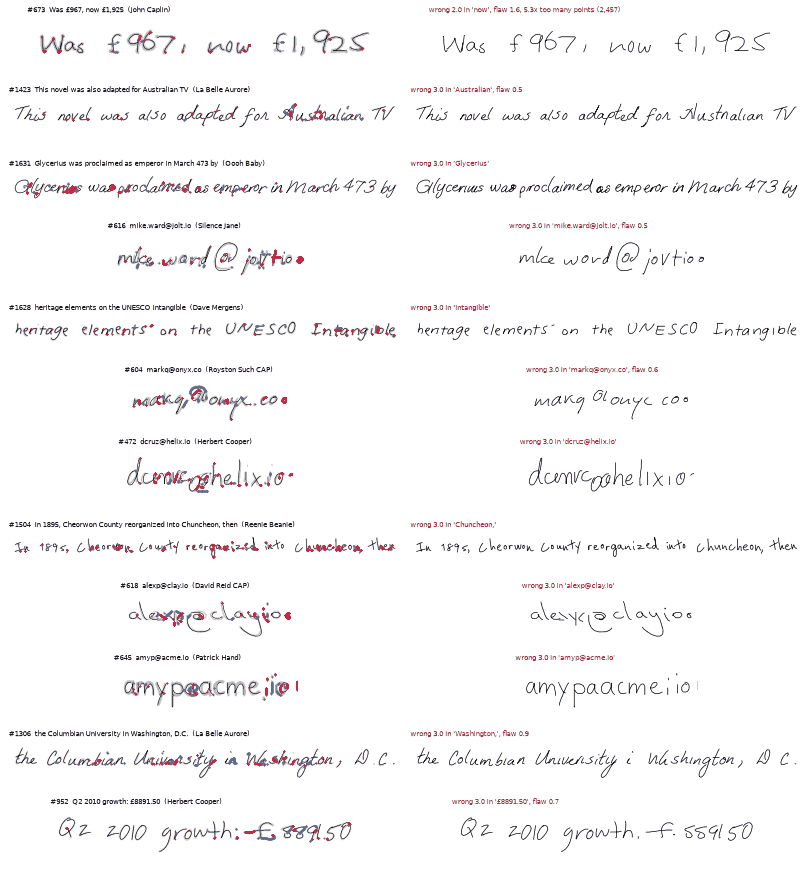

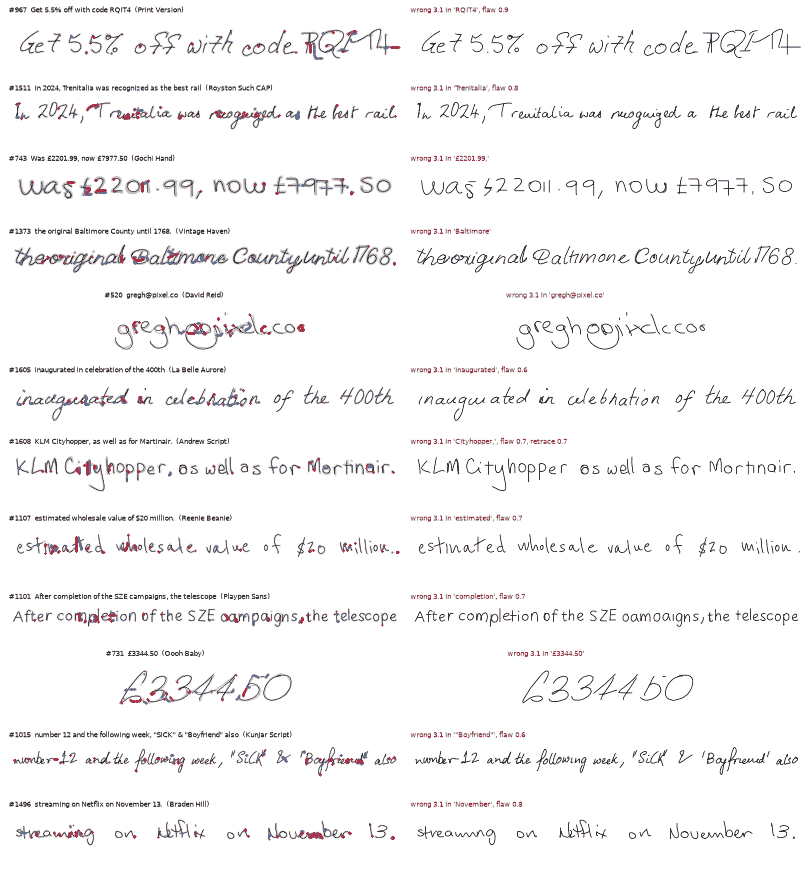

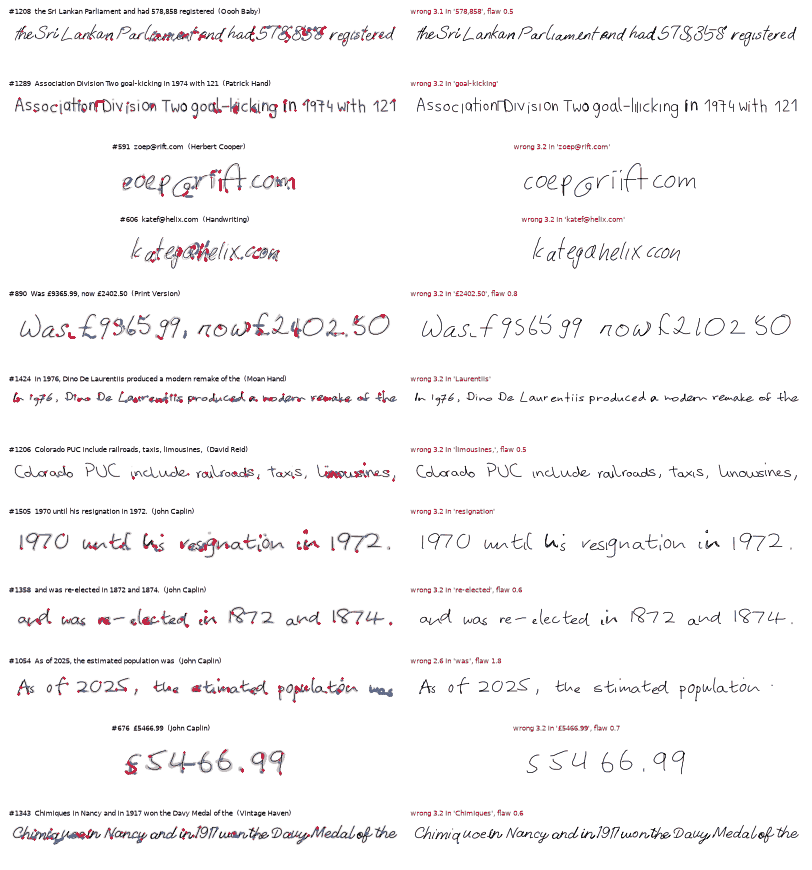

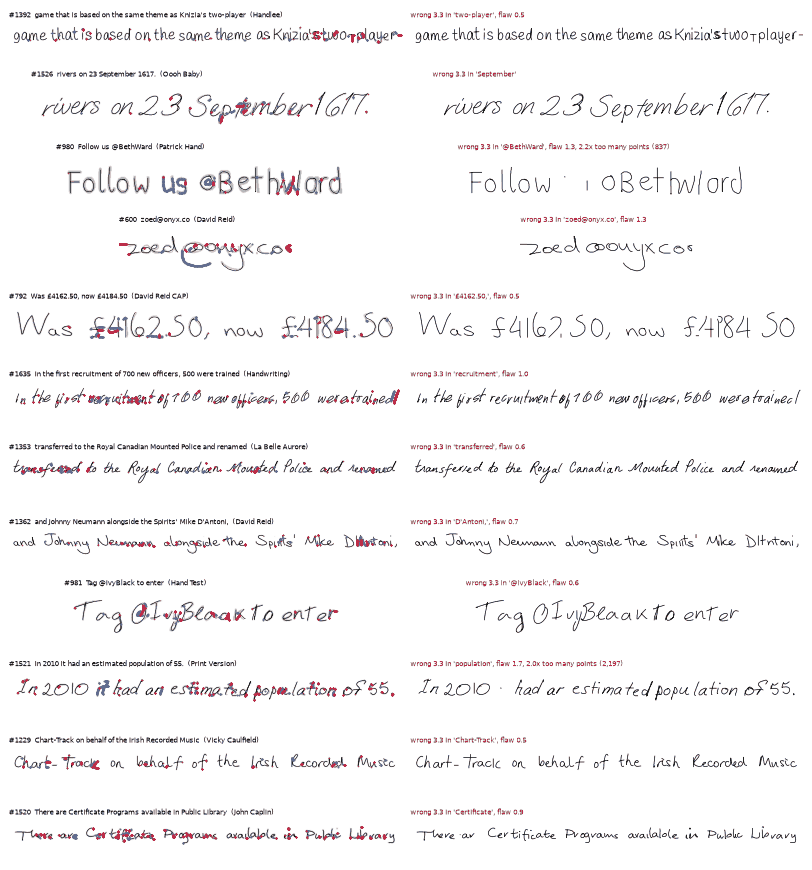

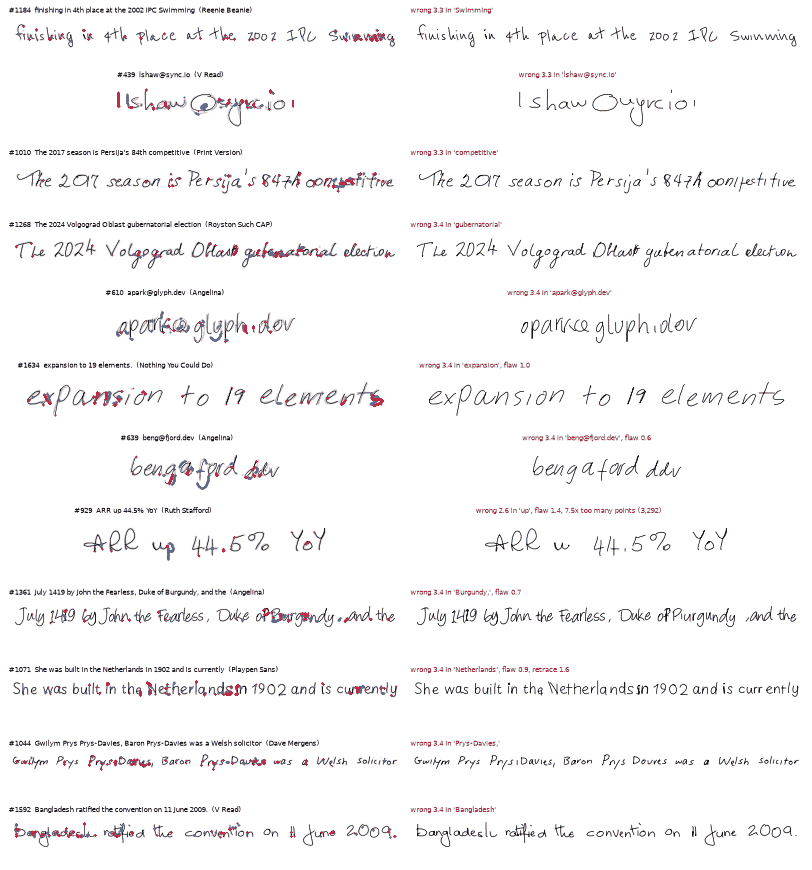

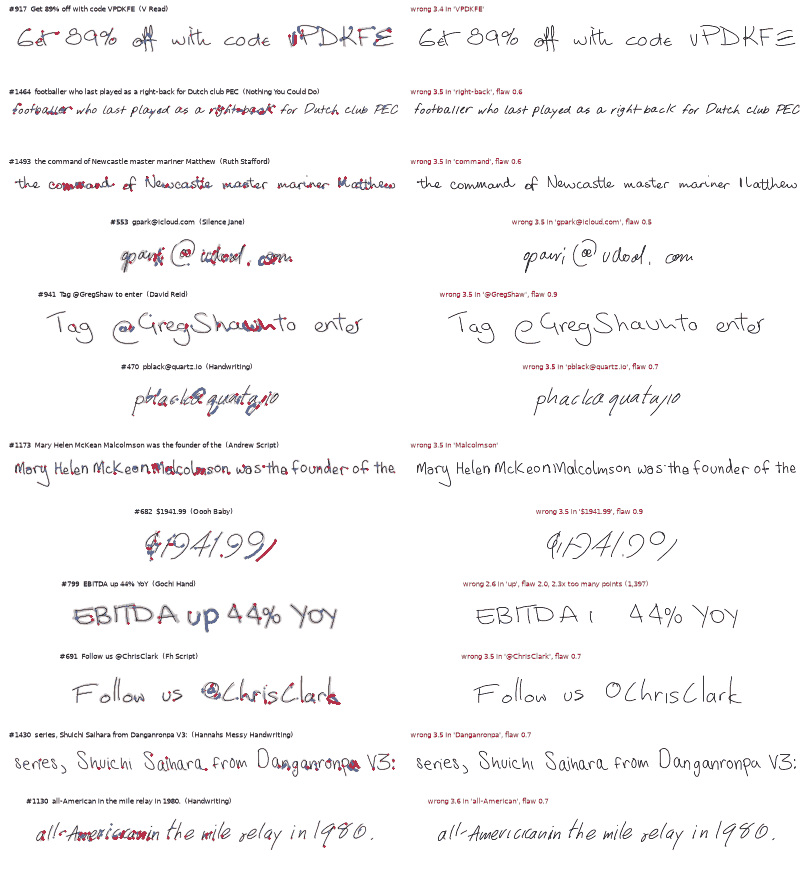

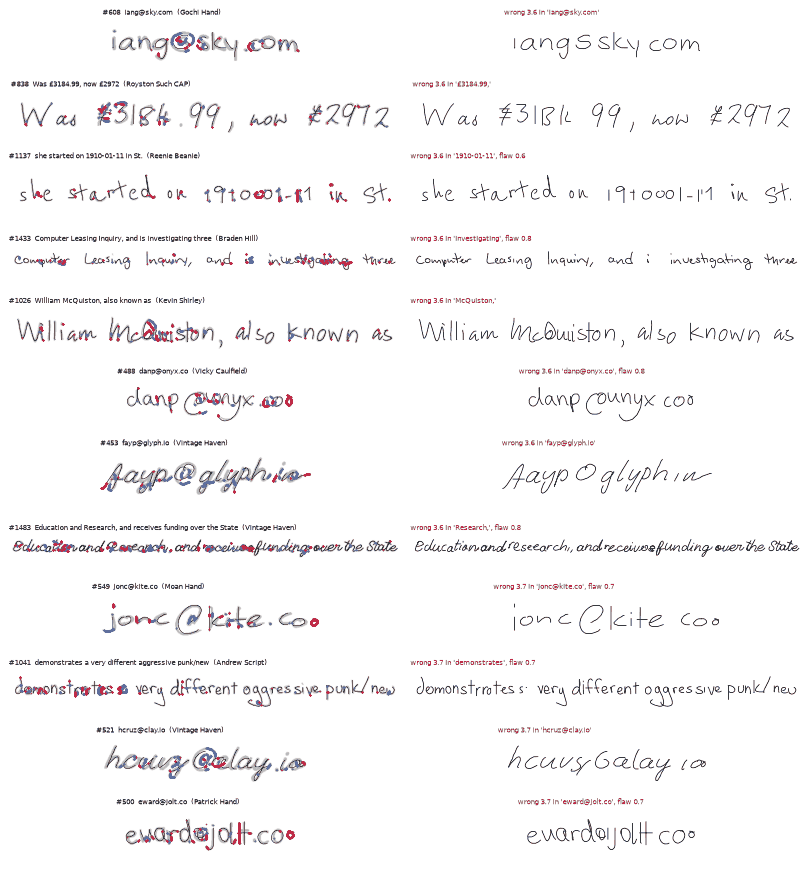

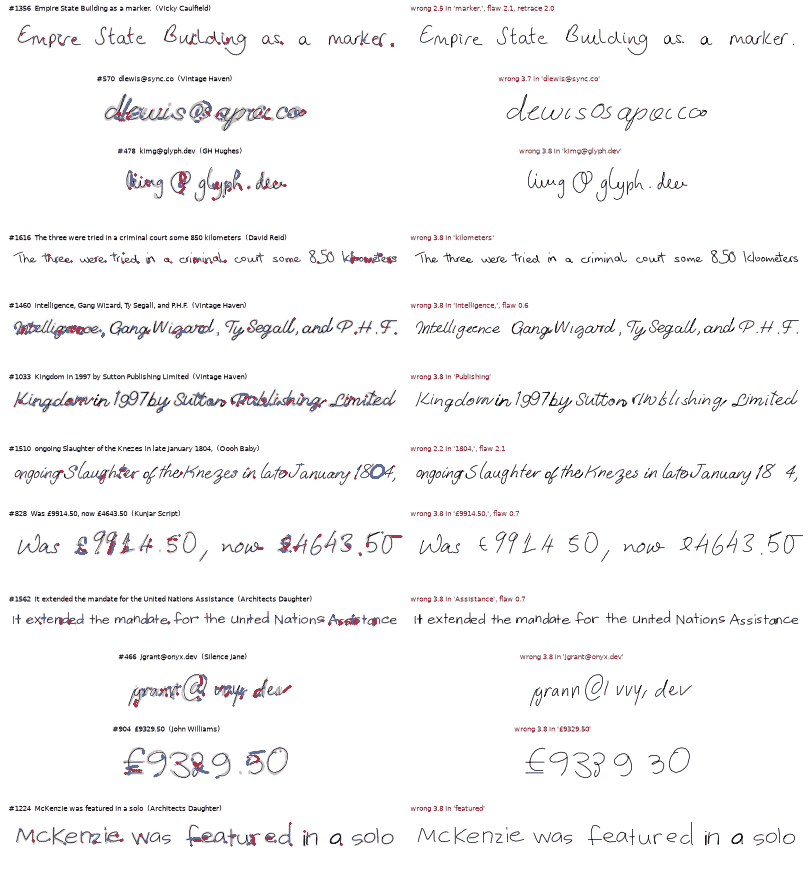

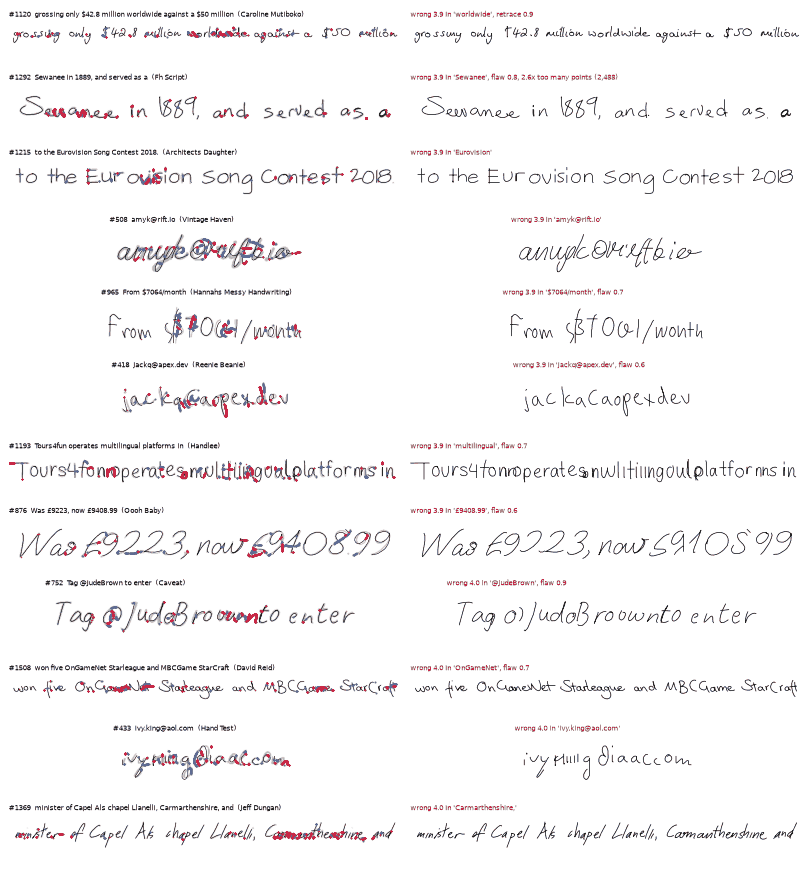

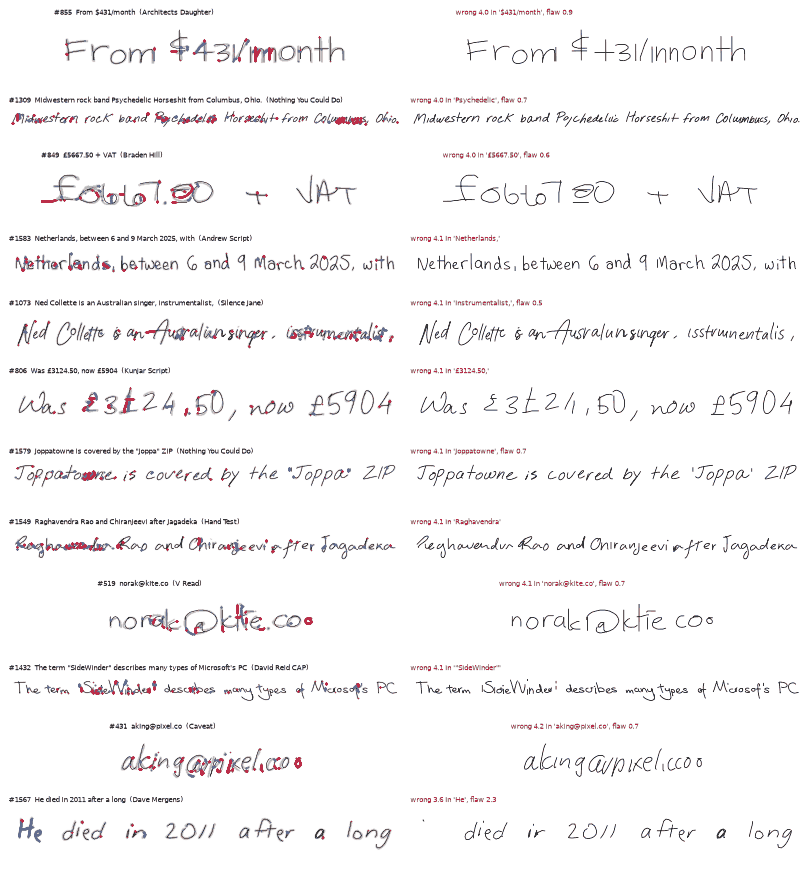

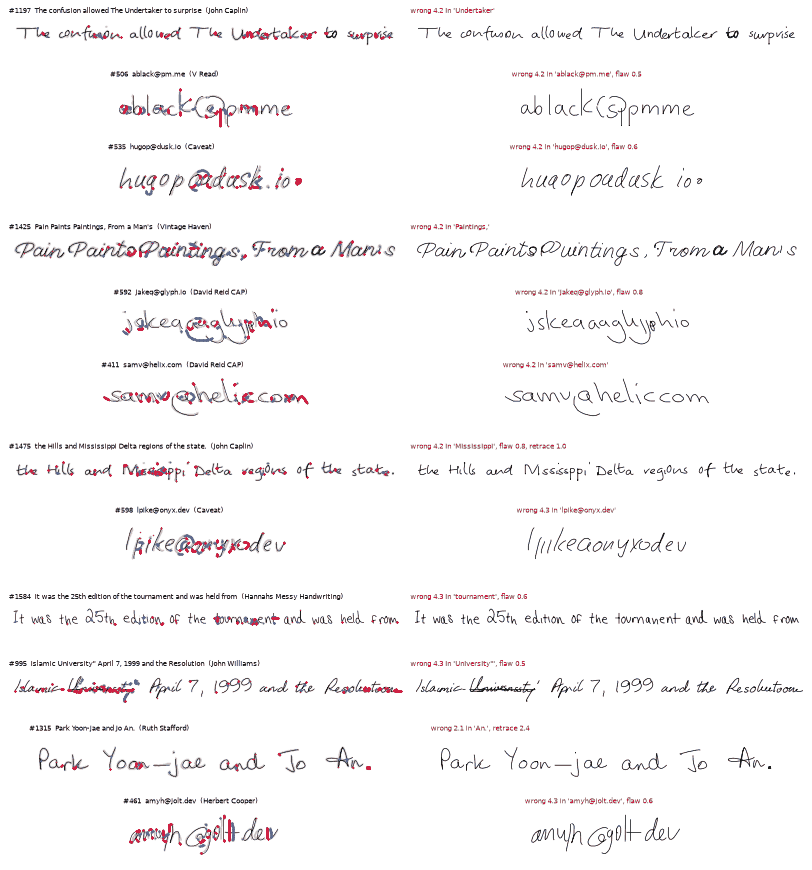

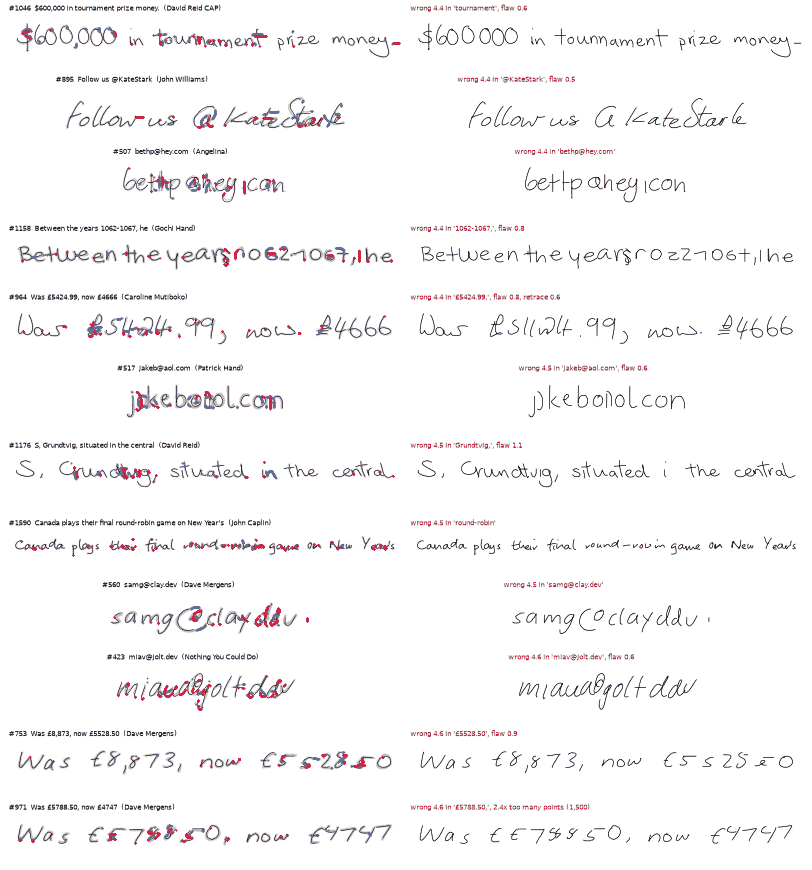

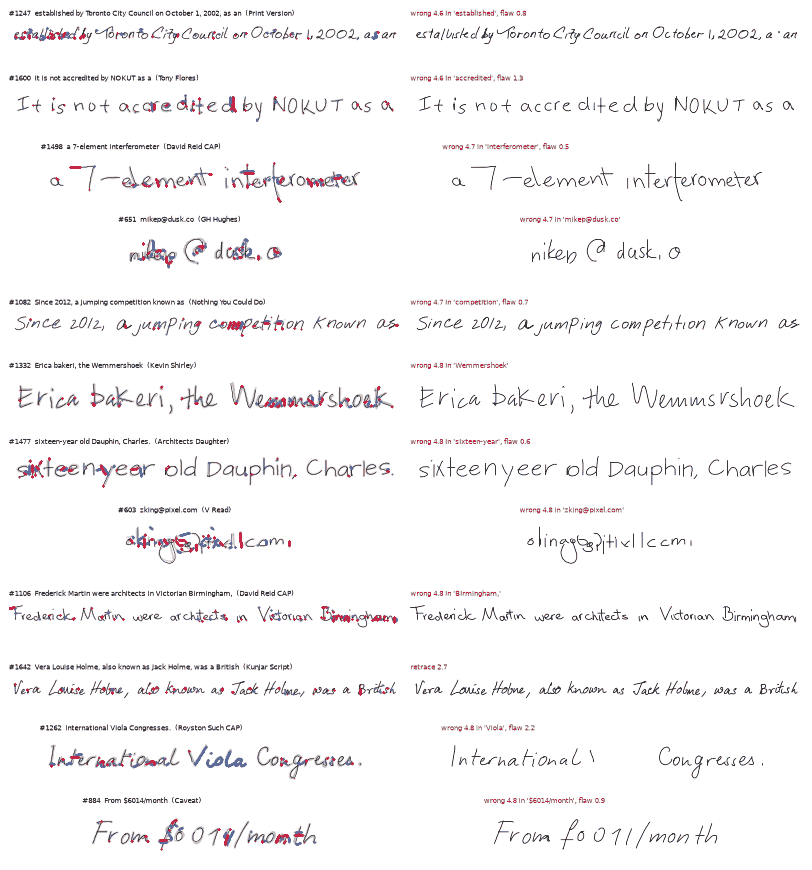

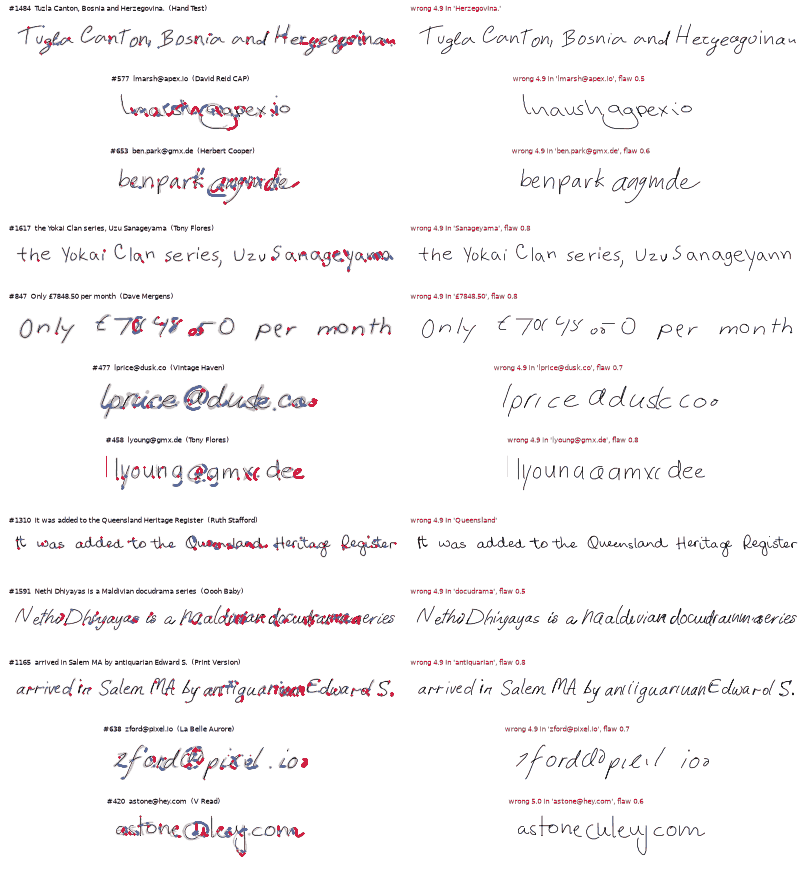

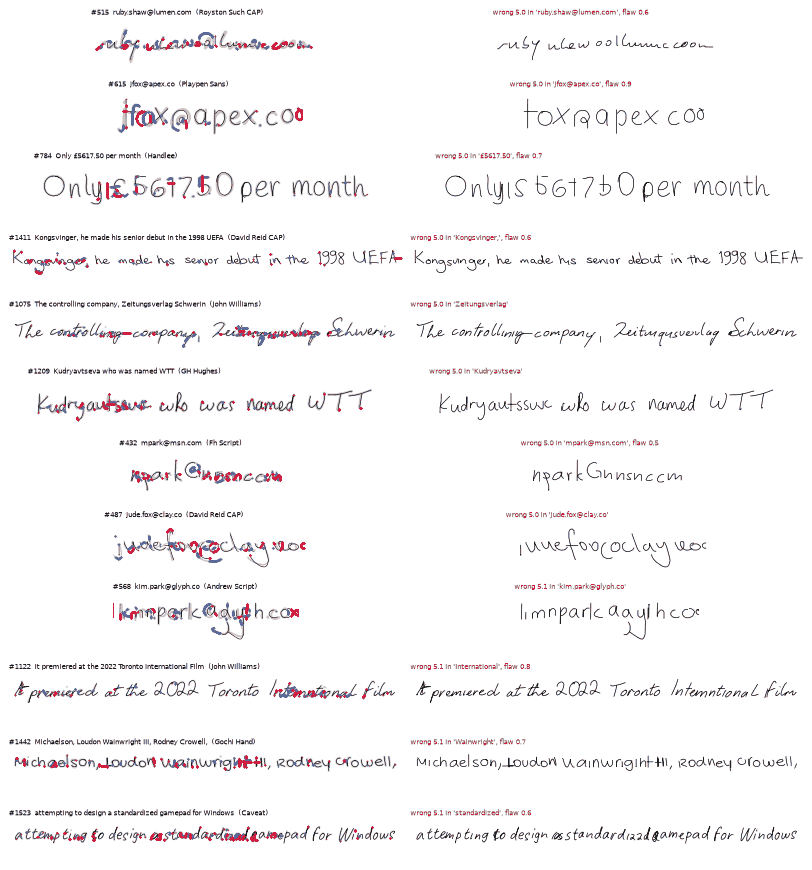

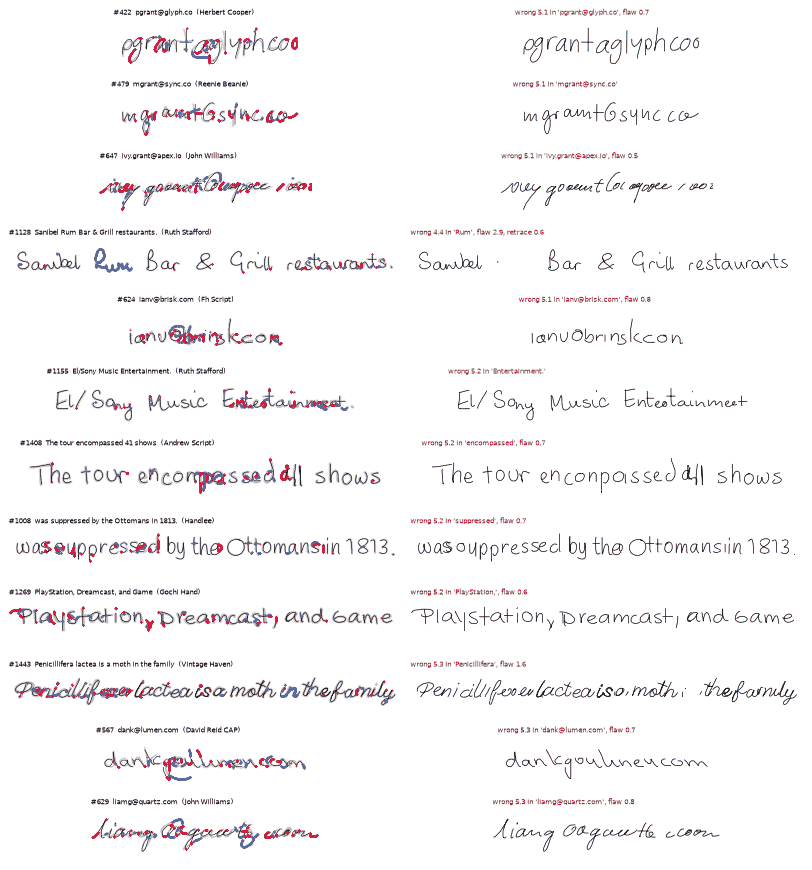

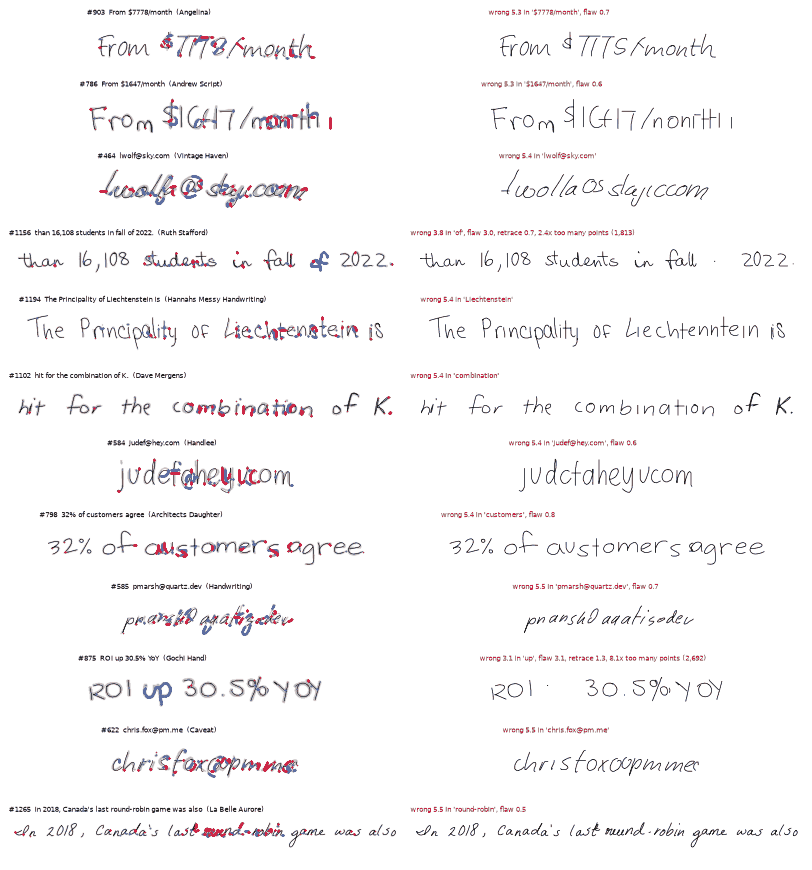

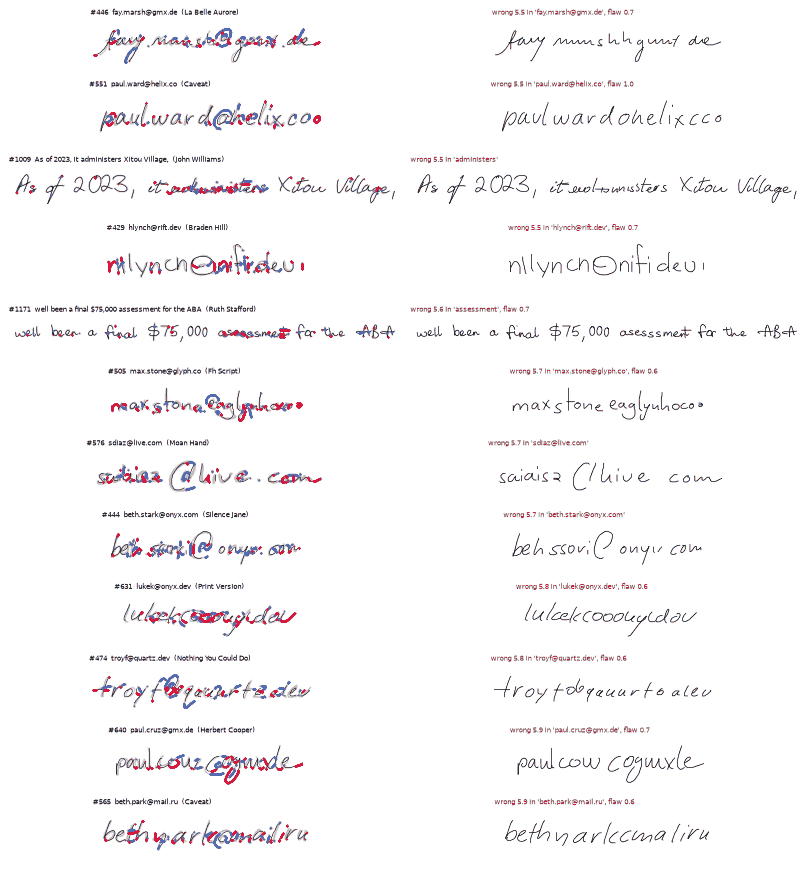

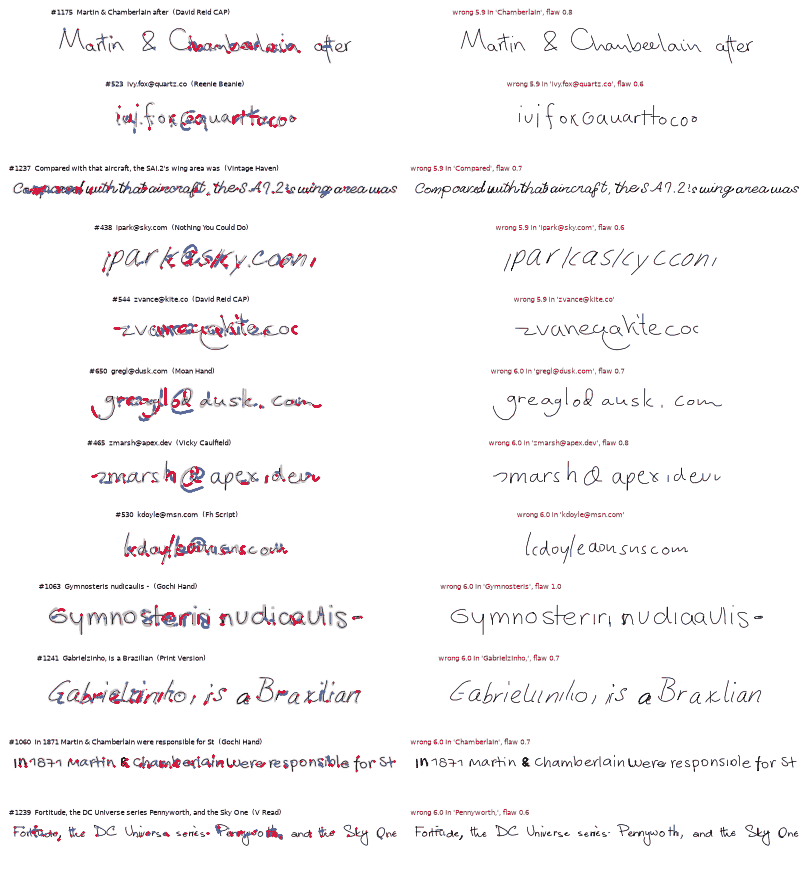

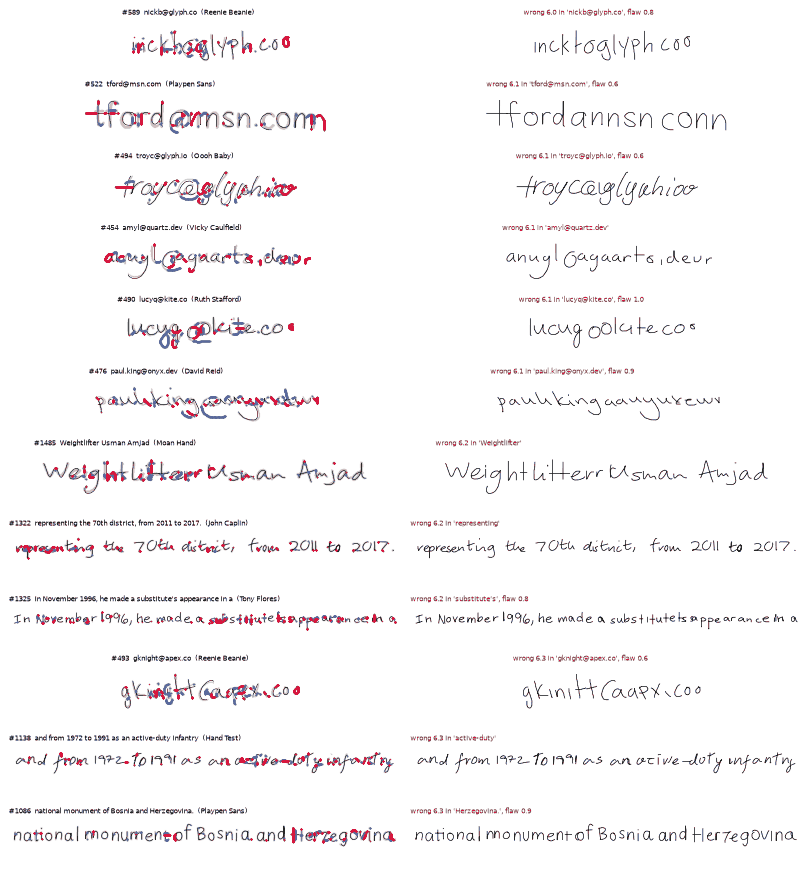

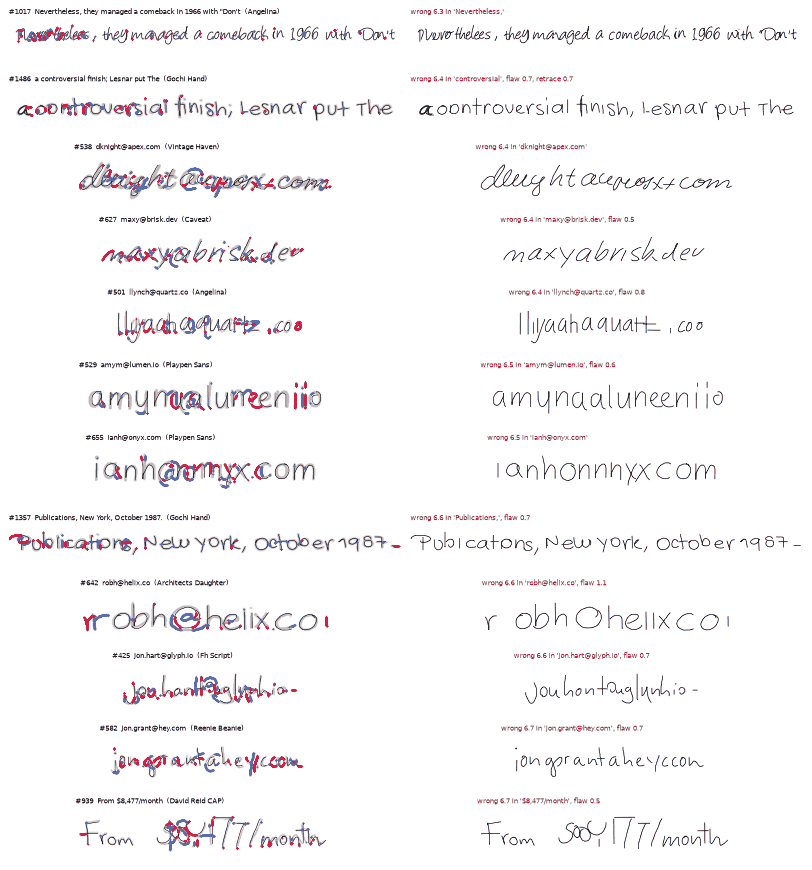

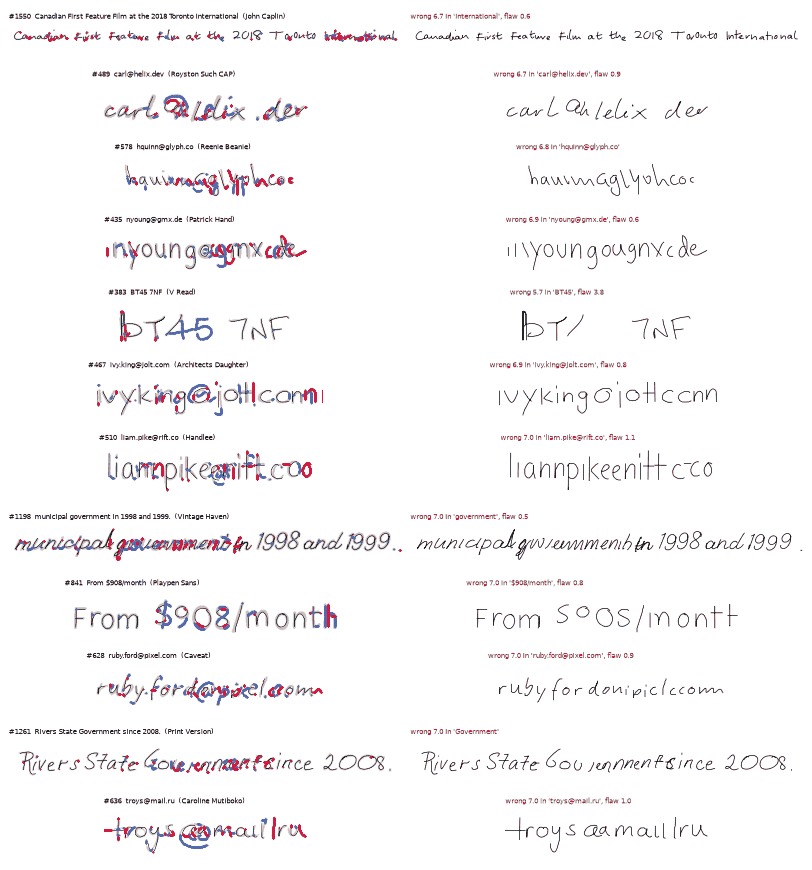

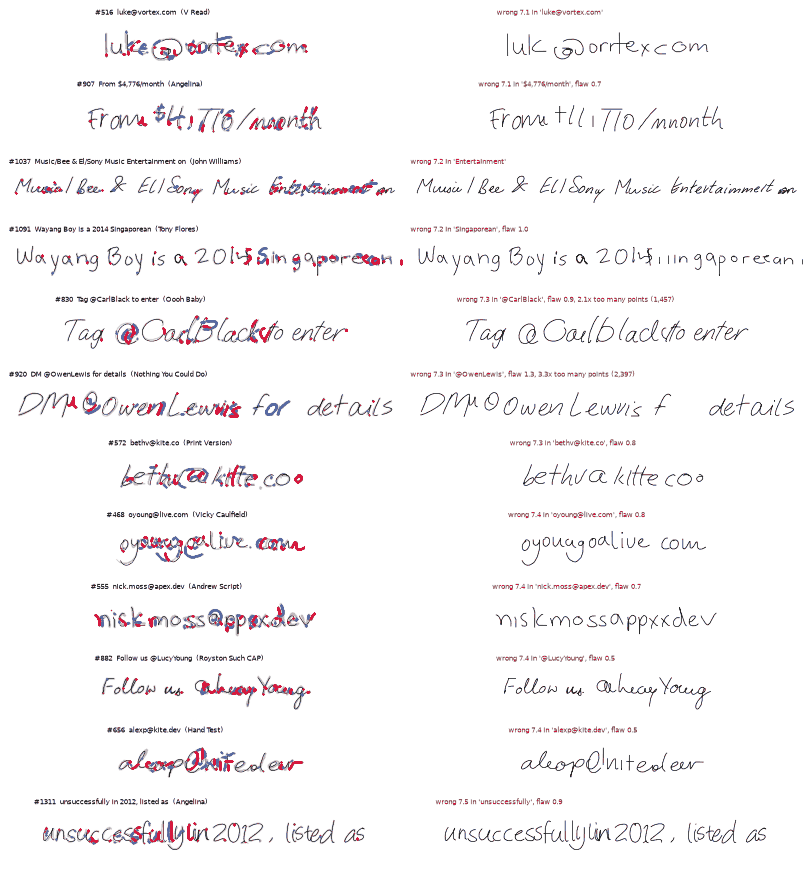

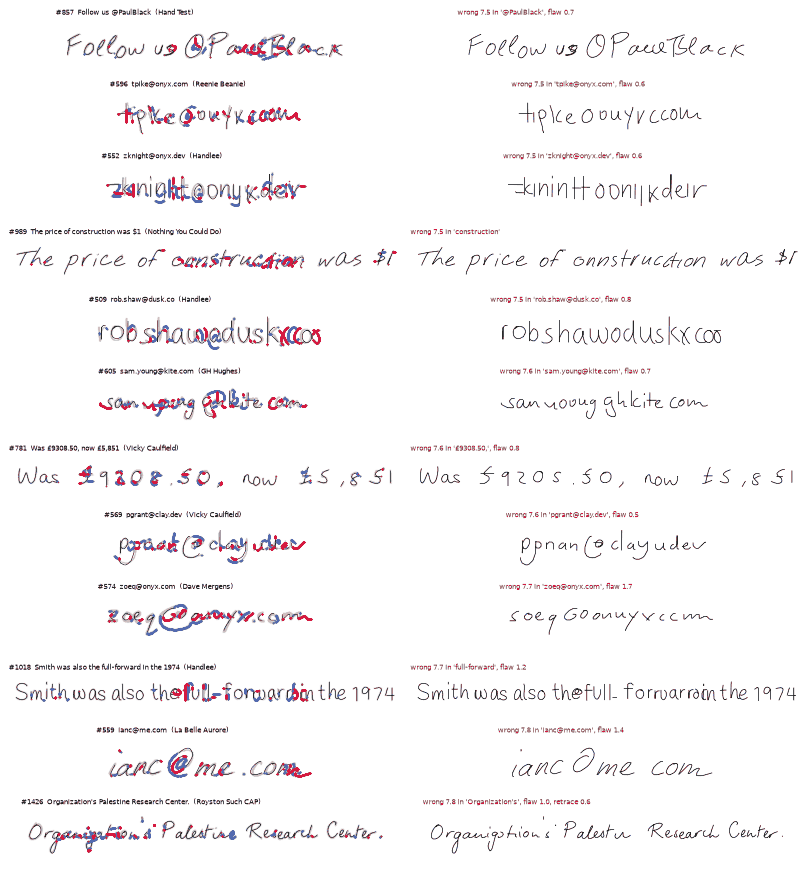

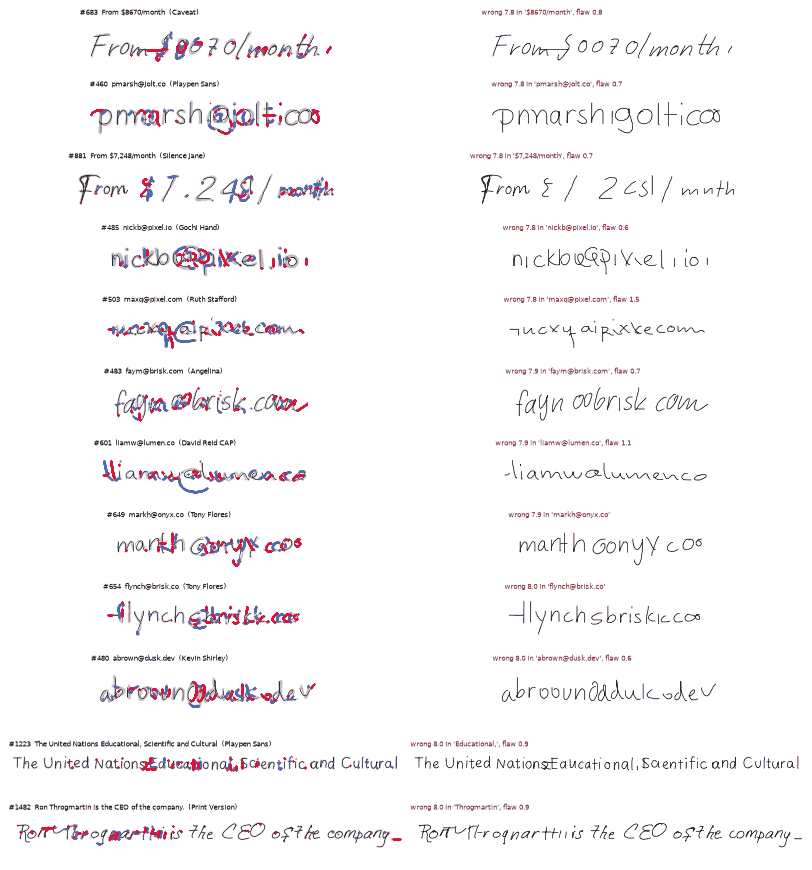

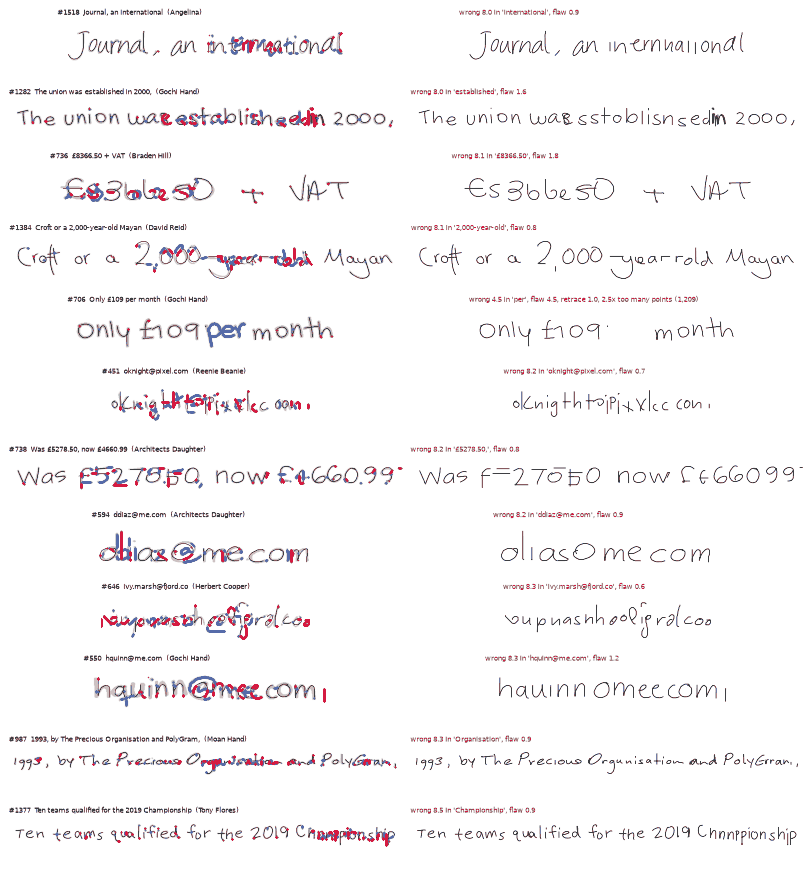

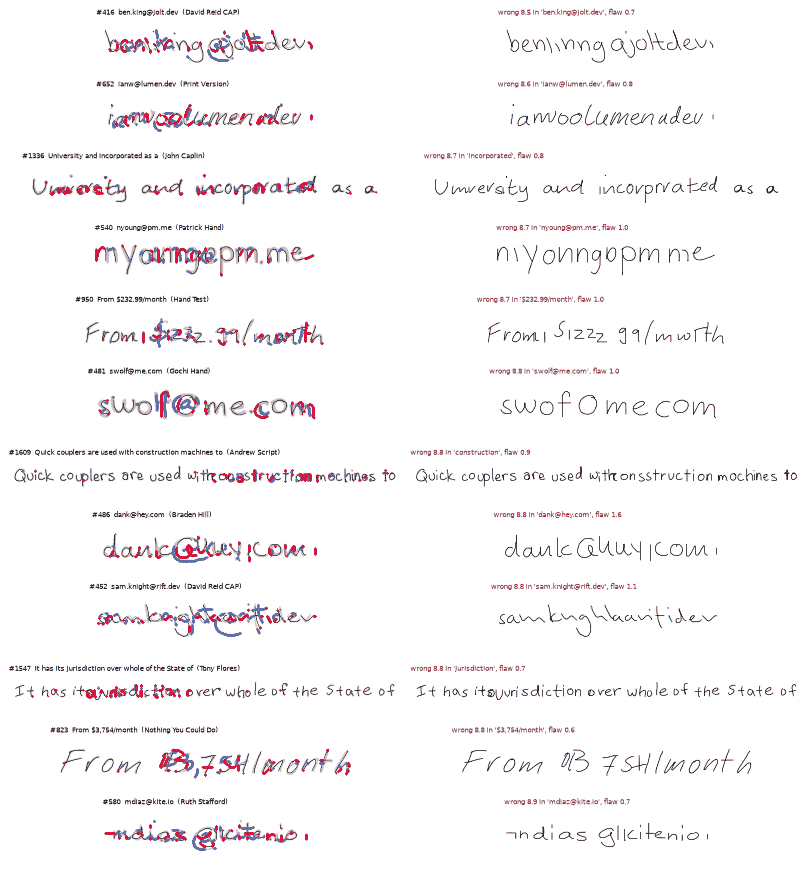

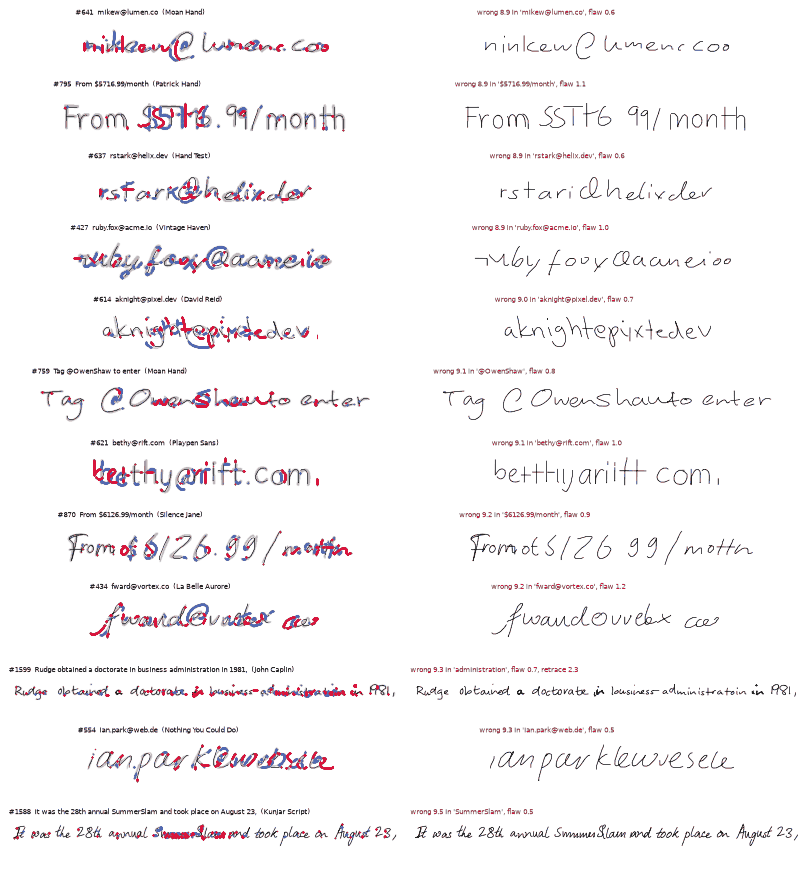

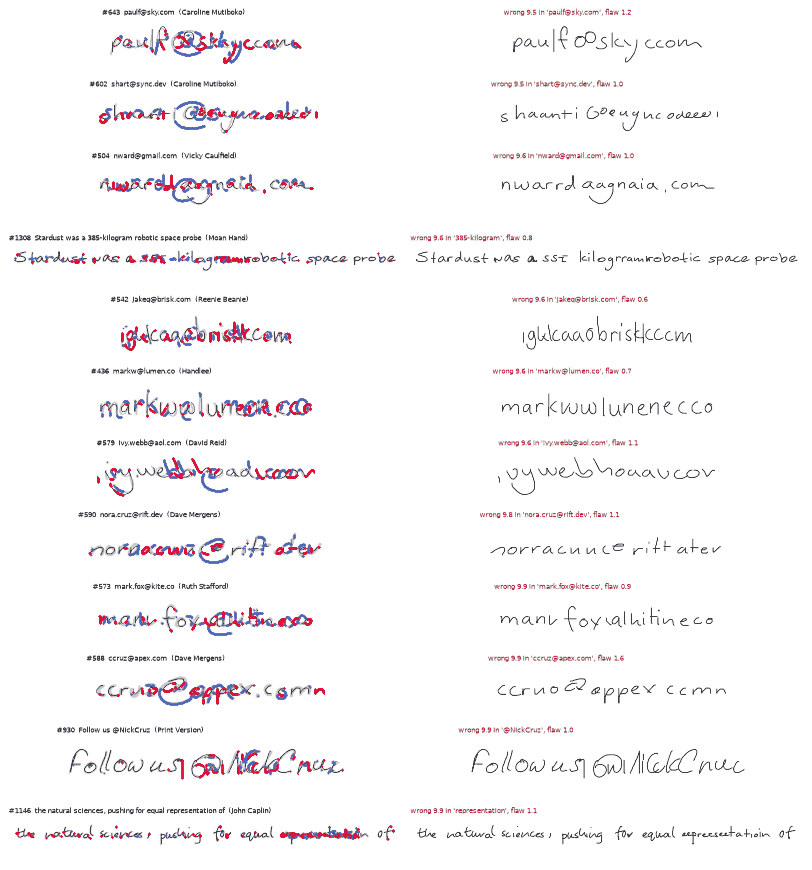

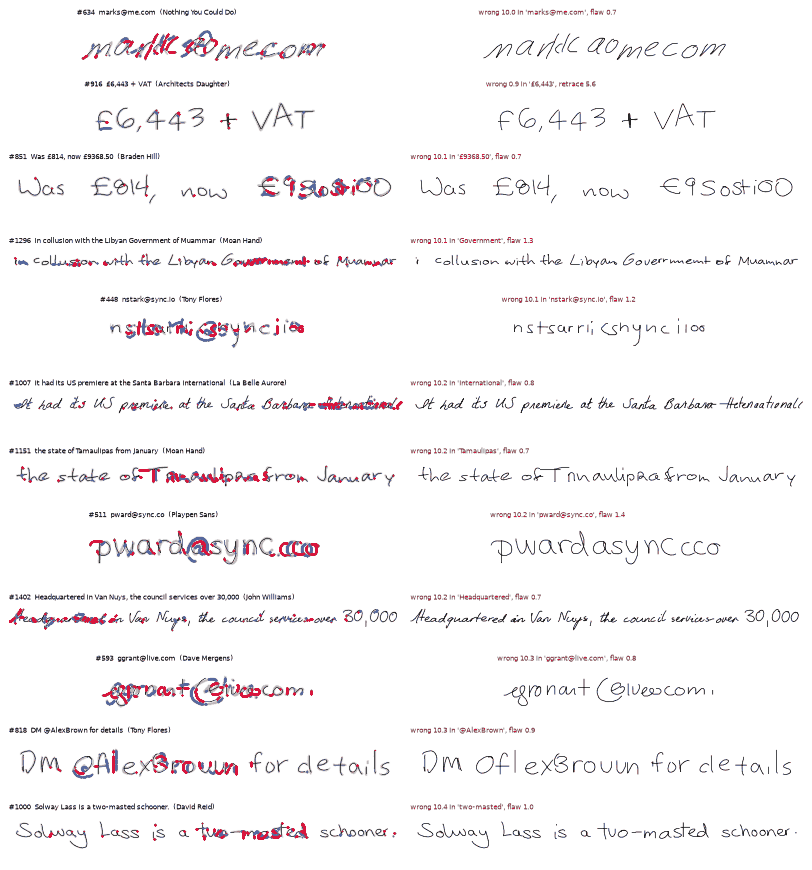

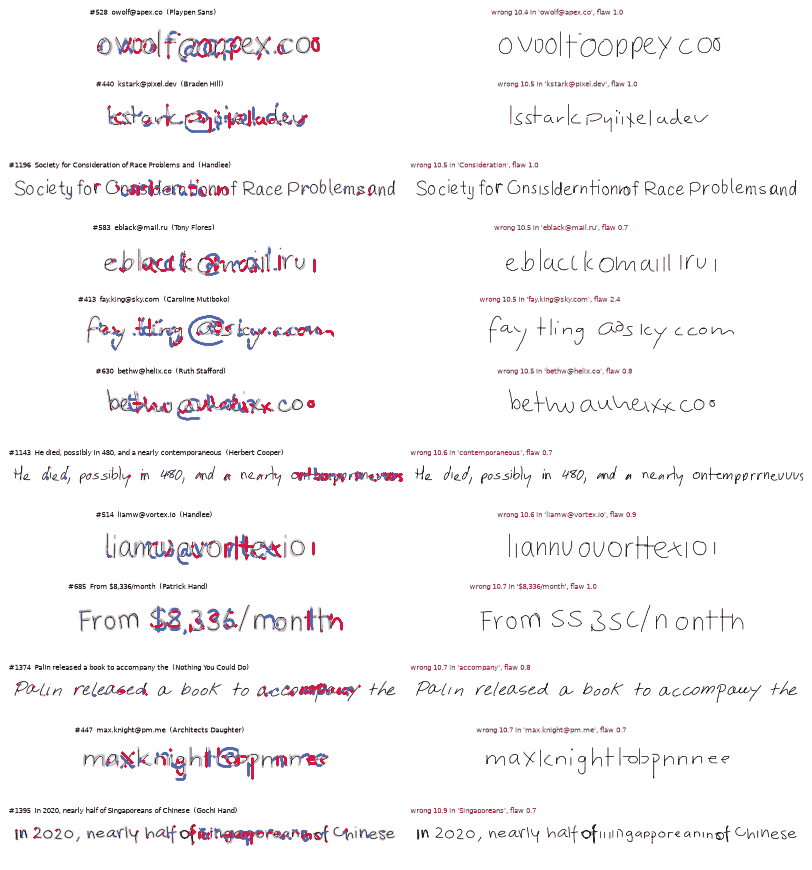

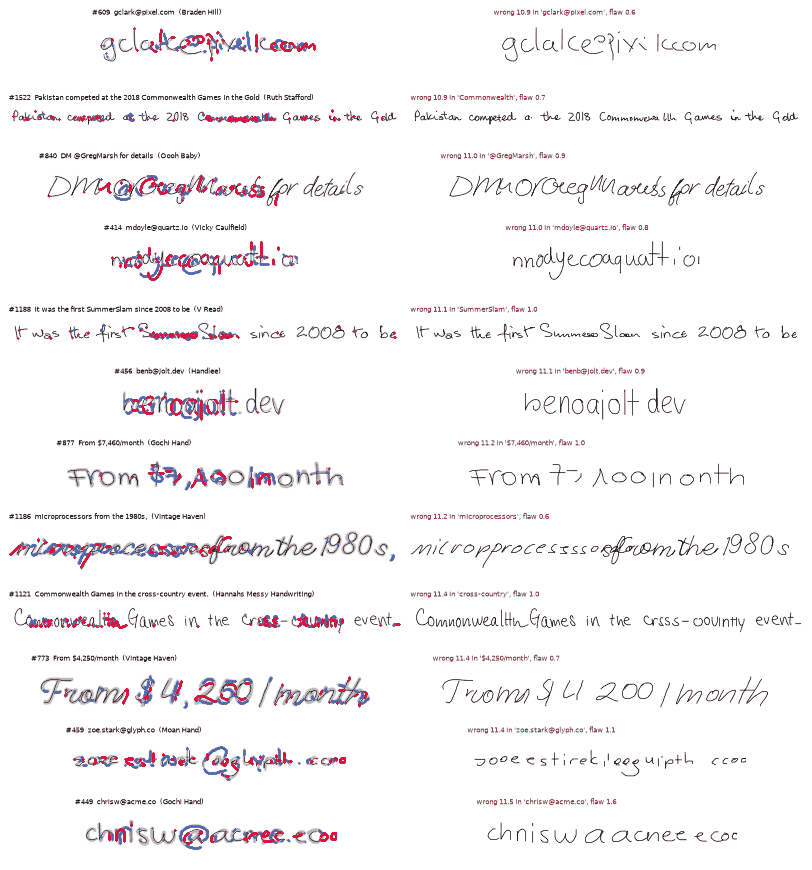

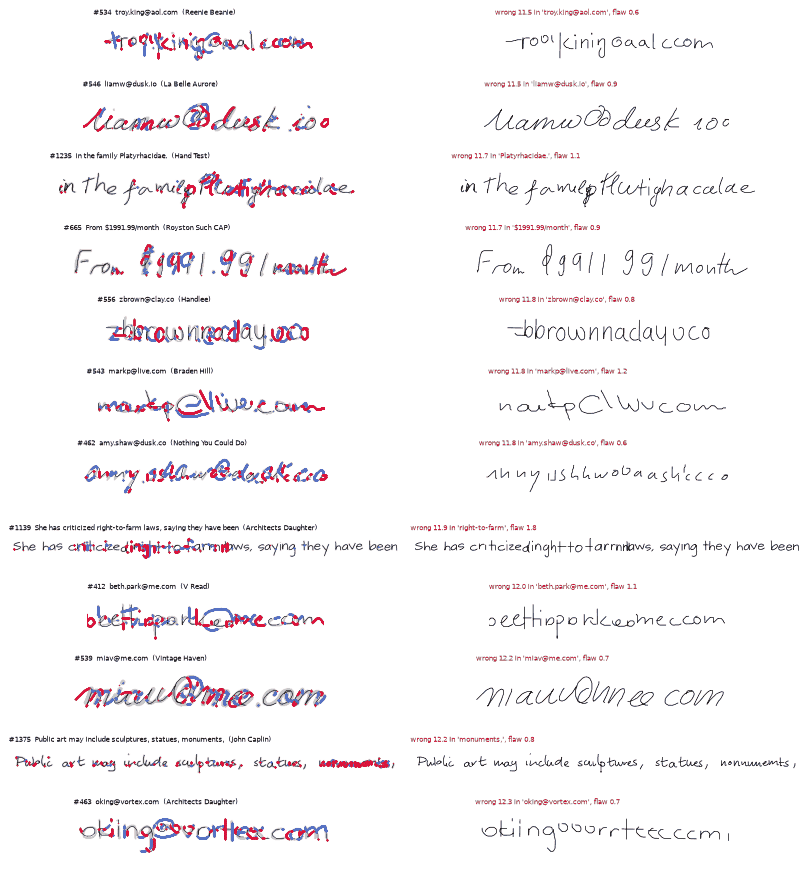

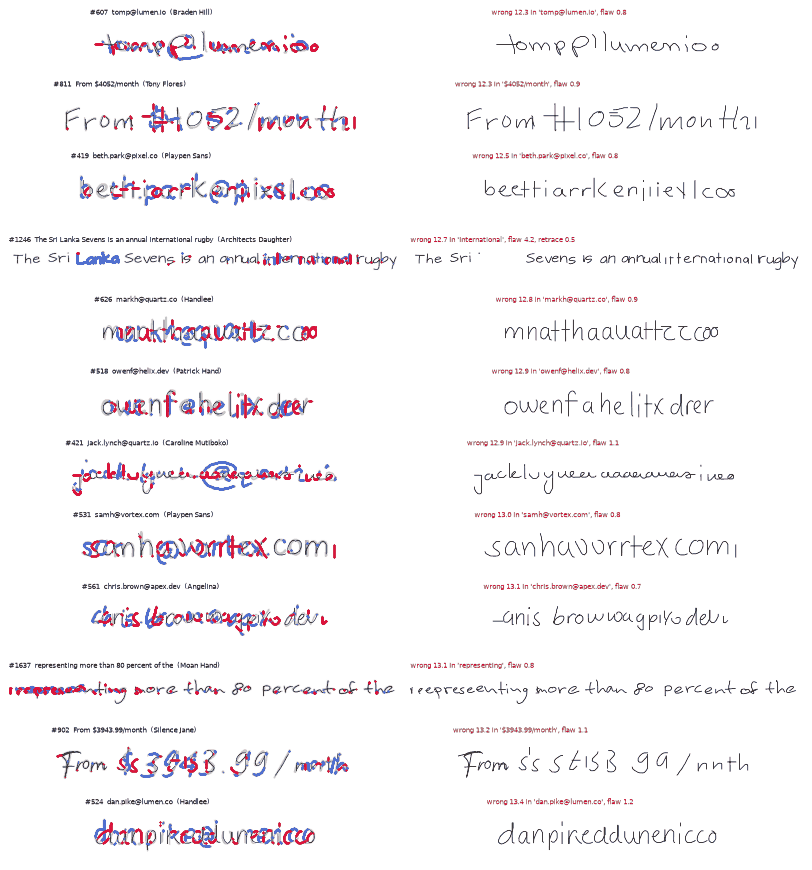

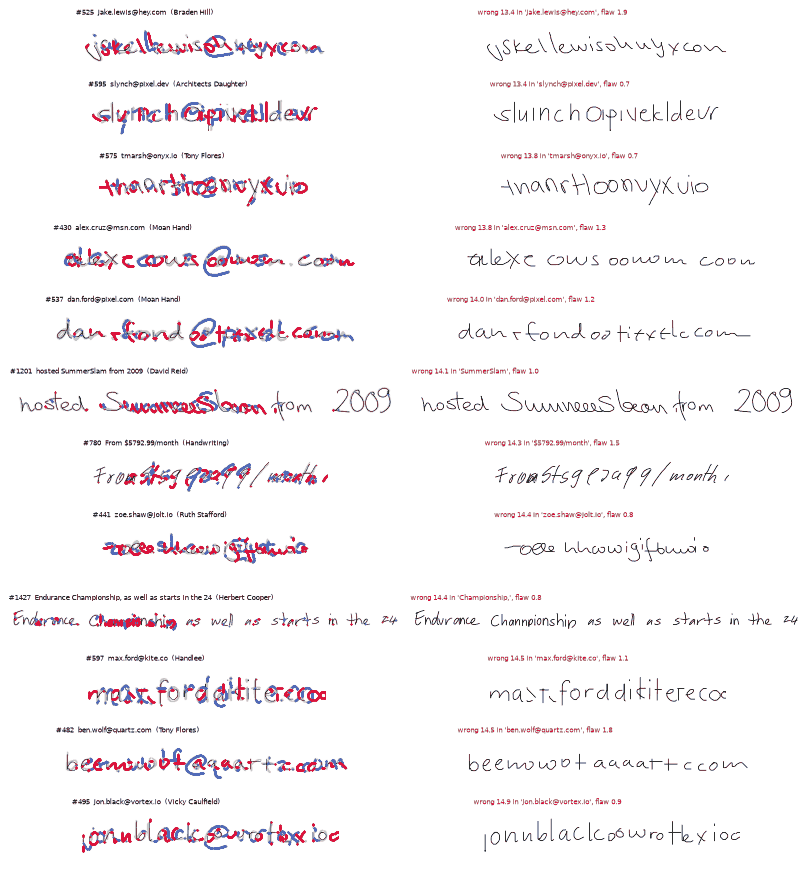

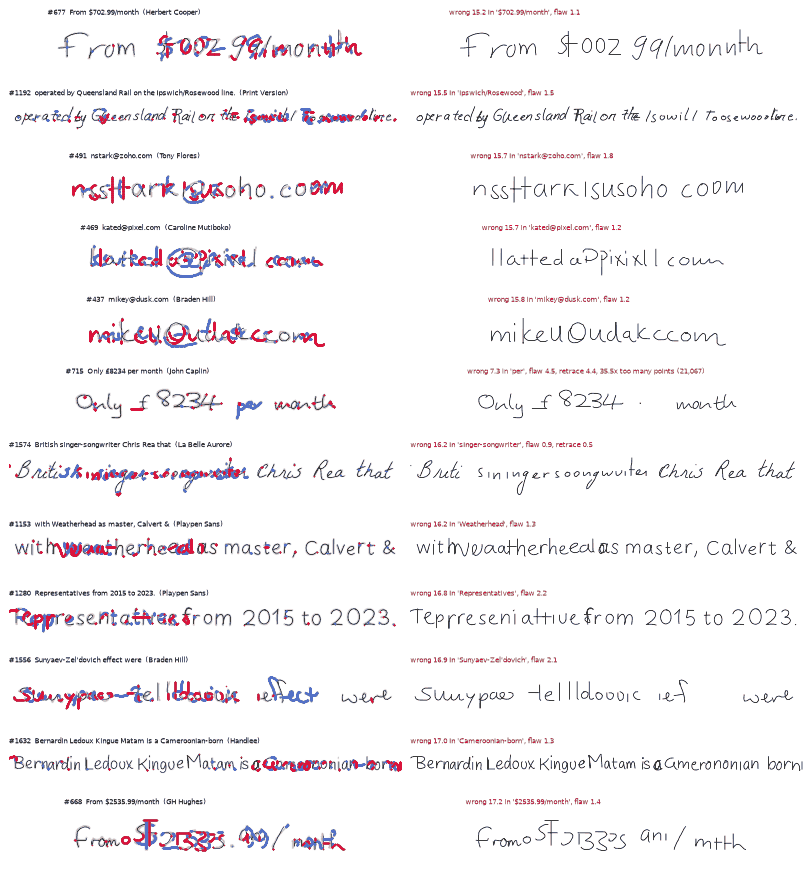

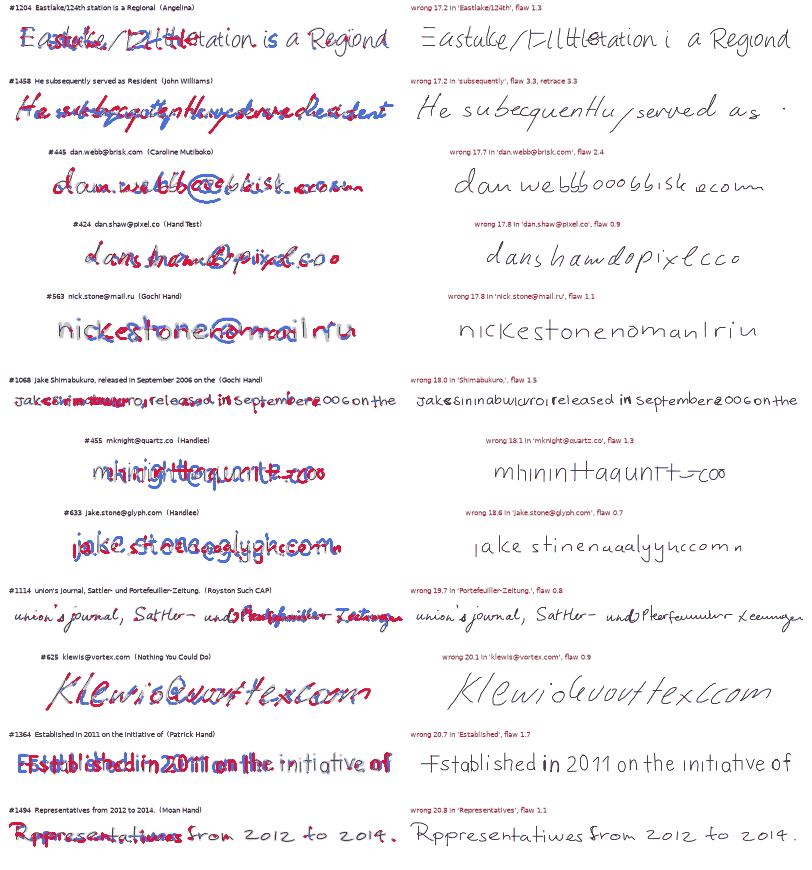

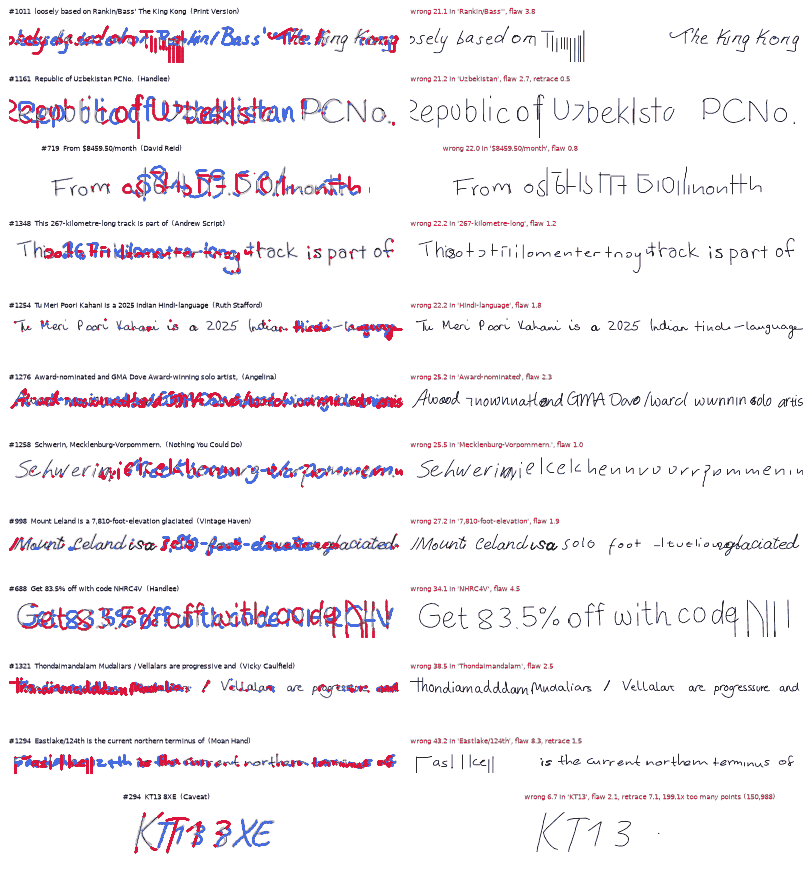

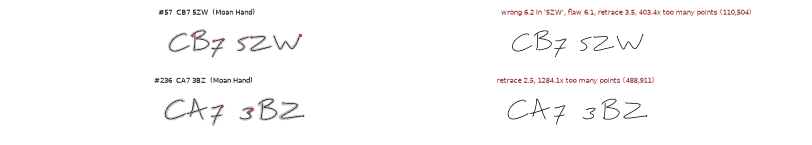

In [21]:
removed = report[report.verdict == "removed"].sort_values("severity")
print(len(removed), "samples")

show(list(removed.index))

### Clean

A random handful of the samples that passed everything, for comparison.

603 samples


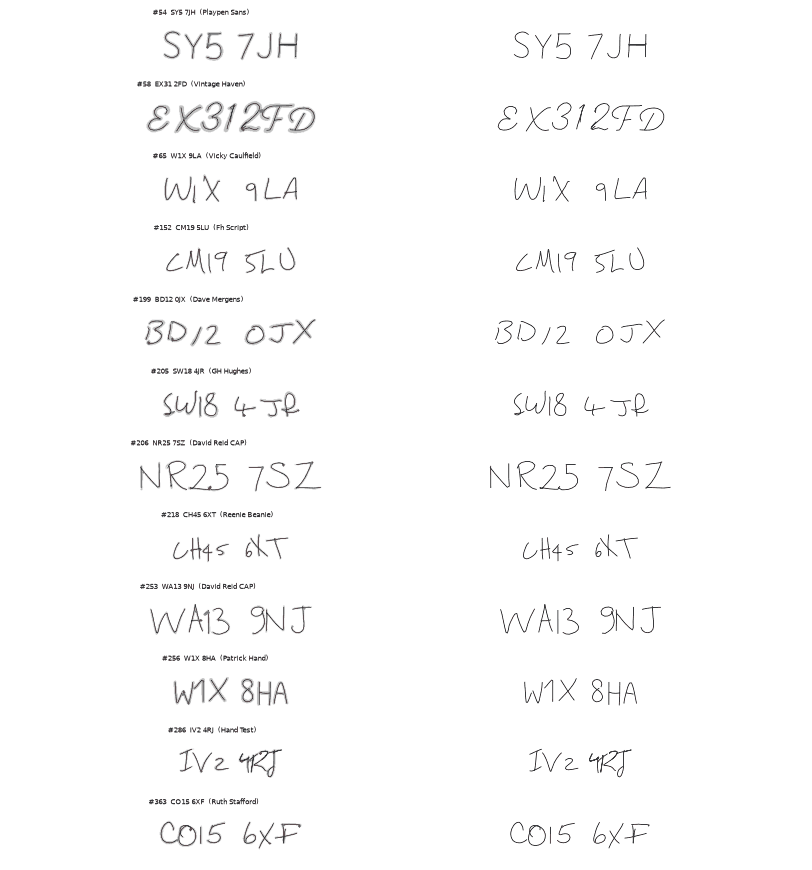

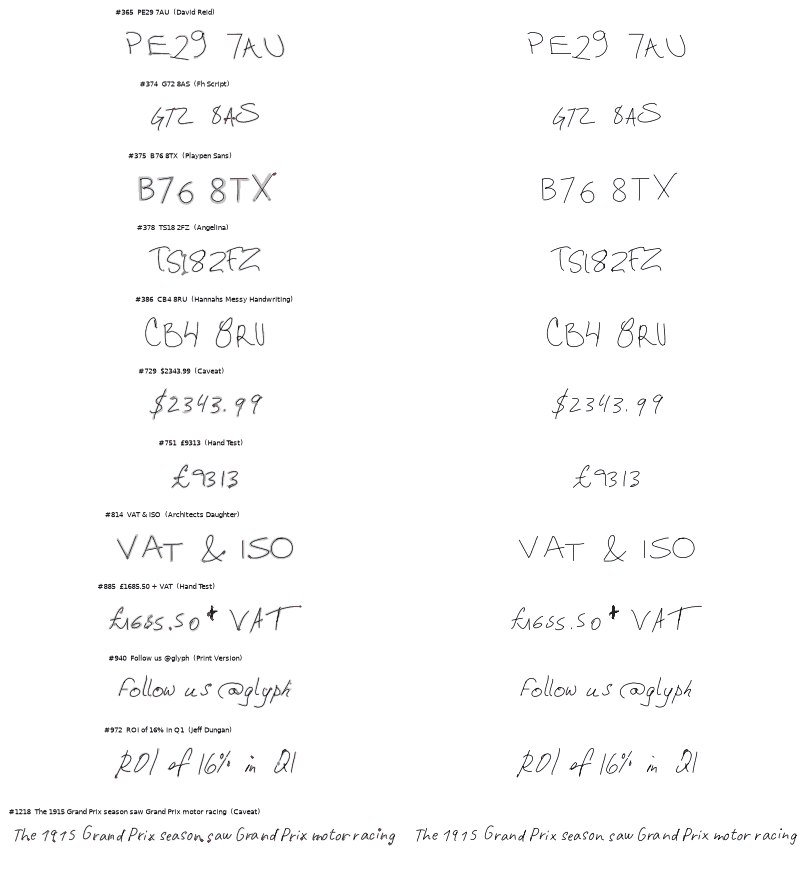

In [22]:
clean = report[report.verdict == "clean"]
print(len(clean), "samples")

show(sorted(clean.sample(24, random_state=0).index))

# Notes

**What the measures cannot see.** They compare shapes, not order: a sample whose strokes are right but drawn in an odd order or direction passes. And detail finer than `TOLERANCE` is invisible, which matters for one glyph: a small `@` whose inside is drawn as a plain `o`. The four in `MANUAL_REMOVE` were found by looking at every kept sample with an `@` in it; three more (#693, #866, #888) draw the inside as a hook, which reads as an `@` and was kept.

**Why samples fail.** Four causes account for nearly everything removed:

1. **Long words.** InkSight sees each word scaled into 224 × 224 pixels. A 15-character email address leaves each letter about 15 pixels wide, and instead of tracing letters it cannot make out, the model writes its own version of the prompt text. That is why almost every email is removed, and why the longest word of a corpus line is usually its worst.
2. **`@`** is mostly drawn as an `o` or an `a`, for the same reason: inside a word it is too small.
3. **Scribbling on the spot.** InkSight sometimes repeats a few tokens over and over, so the pen shuttles between two or three pixels dozens of times. It draws as a dot, or not at all.
4. **Too many points.** Notebook 07 spaces points by the handwriting scale it measures on InkSight's raw points. Those are unevenly spread, and when many bunch at one height (a scribble does exactly this) the scale comes out too small and the spacing with it. One postcode has 488,911 points where about 150 are expected.

The first two are InkSight's limits, and would need the long words cut into shorter crops (an email at its `@` and dots, say) before derendering. The last two can be fixed in notebook 07: drop repeated points before measuring, and measure the scale on evenly spaced points.